# Análises estatísticas após o data wrangling e técnicas não supervisionadas
## Notebook de referência para Engenharia de Computação

Este material começa no ponto em que a base já passou por organização, conversão de tipos, revisão de duplicatas e tratamento documentado de inconsistências. O próximo objetivo é transformar dados em respostas: descrever o comportamento de equipamentos, comparar soluções, investigar associações, estimar incerteza e descobrir estruturas sem rótulos.

O percurso é didático e progressivo. Em cada técnica são apresentados a pergunta que ela responde, o motivo de utilizar, os pressupostos relevantes, o código, os gráficos e os limites da interpretação. O material cobre um conjunto amplo de técnicas usuais de análise estatística e de aprendizado não supervisionado. Nenhum catálogo finito contém todas as técnicas existentes: métodos especializados são indicados quando o desenho exige aprofundamento.

Os exemplos utilizam dados **sintéticos**, gerados no próprio notebook: dispositivos embarcados, benchmarks de firmware, tempos de resposta, falhas de comunicação e perfis de utilização de servidores. Os dados não representam experimentos reais. A geração controlada permite aprender sem depender de downloads, APIs ou arquivos externos.

**Execução:** abrir no Google Colab, Jupyter ou VS Code e executar de cima para baixo. As primeiras células verificam as bibliotecas. Caso faltem pacotes, a instalação precisa de internet. Todas as análises principais são executáveis. Os dados e resultados exportados ficam na pasta `saidas_estatistica`; baixar os arquivos antes de encerrar uma sessão temporária do Colab.

**Uso como referência:** ler a introdução de cada técnica antes de executar. Não aplicar todos os testes à mesma pergunta até encontrar um p-valor pequeno. A pergunta, a unidade de observação, o desenho e a medida de efeito vêm antes da escolha do teste. Resultados descobertos durante exploração precisam ser distinguidos de hipóteses previamente planejadas.

**Percurso de estudo:** fundamentos e descrição → distribuições e incerteza → comparações e associações → modelos estatísticos → redução de dimensionalidade → agrupamentos → detecção de anomalias → interpretação e aplicação a dados próprios.

**No Google Colab:** selecionar Arquivo > Fazer upload de notebook e enviar este arquivo `.ipynb`; depois selecionar Ambiente de execução > Executar tudo. Não é necessário montar o Google Drive nem ativar GPU. Os exemplos utilizam CPU. Se a primeira célula instalar ou atualizar um pacote já carregado, reiniciar a sessão e executar tudo novamente. UMAP é uma extensão opcional desativada; todas as demais técnicas integram o percurso executável.

## Sumário do material

1. O que fazer depois do tratamento dos dados
2. Preparar o ambiente e registrar versões
3. Revisão de Python necessária para acompanhar os exemplos
4. Construir bases limpas e conhecer o dicionário de dados
5. Verificação final após o data wrangling
6. População, amostra, desenho e pseudorreplicação
7. Definir perguntas e escolher famílias de técnicas
8. Frequências absolutas, relativas e composição
9. Média, mediana, moda e médias aparadas
10. Variância, desvio padrão, amplitude e coeficiente de variação
11. Quantis, IQR, MAD e métricas de cauda
12. Histogramas, densidade, ECDF e escolha do gráfico
13. Assimetria, curtose e mistura de populações
14. Estatística por grupos e risco de conclusões agregadas
15. Investigar extremos e realizar análise de sensibilidade
16. Distribuições de probabilidade e escolha pelo fenômeno
17. Avaliar normalidade com gráficos e Shapiro-Wilk
18. Transformações logarítmicas e Yeo-Johnson
19. Amostragem, erro padrão e teorema central do limite
20. Intervalo de confiança para a média
21. Bootstrap para média, mediana e diferenças
22. Proporções, eventos raros e intervalo de Wilson
23. Hipóteses, p-valor, significância e relevância prática
24. Verificar variâncias com Levene e Brown-Forsythe
25. Teste t de uma amostra contra uma referência
26. Welch para comparar médias de dois grupos independentes
27. Tamanho de efeito: diferença absoluta e Hedges g
28. Mann-Whitney para grupos independentes
29. Teste de permutação e hipótese de intercambiabilidade
30. Teste t pareado e gráfico das mudanças individuais
31. Wilcoxon pareado e teste dos sinais
32. ANOVA clássica para três ou mais grupos
33. ANOVA de Welch quando variâncias não são comuns
34. Pós-testes e controle de comparações múltiplas
35. Kruskal-Wallis para grupos independentes por postos
36. Três condições nas mesmas placas: ANOVA repetida e Friedman
37. Comparar duas proporções independentes
38. Qui-quadrado de independência e V de Cramér
39. Fisher, risco relativo e odds ratio
40. McNemar para eventos binários pareados
41. Comparar distribuições completas com Kolmogorov-Smirnov
42. Pearson, covariância e associação linear
43. Spearman e Kendall para relações monotônicas
44. Matriz de correlações, redundância e associação condicionada
45. Regressão linear simples: associação em unidades do problema
46. Regressão múltipla, categorias e ANCOVA
47. Diagnosticar resíduos, heterocedasticidade e erros padrão HC3
48. Multicolinearidade, VIF, alavancagem e influência
49. Interações e ANOVA fatorial: o efeito depende do contexto
50. Intervalo da média prevista versus intervalo de observação
51. Regressão robusta e regressão quantílica
52. Regressão logística para uma resposta binária
53. Poisson, exposição e sobredispersão em contagens
54. Modelos mistos para medições repetidas e hierarquia
55. MANOVA: comparar um vetor de respostas
56. Poder estatístico, tamanho amostral e equivalência
57. Introdução bayesiana: probabilidade de falha com Beta-Binomial
58. Dados censurados: por que tempo até falha exige outra análise
59. Escrever resultados sem extrapolar os dados
60. Aprendizado não supervisionado: o que pode ser descoberto
61. Construir perfis de servidores sem fornecer seus rótulos
62. Distâncias, escala e por que padronizar
63. Escolher atributos e uma noção de semelhança
64. PCA: reduzir redundância com combinações lineares
65. Interpretar pesos, número de componentes e reconstrução
66. Análise fatorial: modelar fatores latentes e variância específica
67. SVD truncada e uma aplicação a logs textuais
68. NMF: representar dados não negativos por partes
69. ICA: separar fontes estatisticamente independentes
70. K-means: perfis em torno de centroides
71. Escolher k com cotovelo e silhueta
72. Interpretar grupos nas unidades originais e em perfis
73. MiniBatchKMeans para volume maior de dados
74. Agrupamento hierárquico e dendrograma
75. DBSCAN: grupos por densidade e pontos de ruído
76. Escolher parâmetros de densidade e analisar sensibilidade
77. OPTICS e HDBSCAN para estrutura de densidade
78. Gaussian Mixture: grupos probabilísticos e covariâncias
79. Agrupamento espectral e semelhança em um grafo
80. Avaliação interna: silhueta, Davies-Bouldin e Calinski-Harabasz
81. Estabilidade entre sementes, amostras e escalas
82. Atribuir novos equipamentos sem reajustar a escala
83. t-SNE: visualização local e riscos de interpretação
84. Isomap e UMAP: representações não lineares
85. Isolation Forest: pontuar combinações incomuns
86. Local Outlier Factor: anomalia relativa aos vizinhos
87. Regras de associação: eventos que aparecem juntos
88. Comparar técnicas não supervisionadas conforme a pergunta
89. Roteiro completo de uma análise após data wrangling
90. Exportar resultados e construir um registro reutilizável
91. Adaptar a uma base própria sem aplicar todos os testes
92. Exercícios guiados de estatística e interpretação
93. Exercícios guiados de técnicas não supervisionadas
94. Respostas orientadoras e síntese dos critérios de escolha
95. Glossário e limites de aplicação
96. Referências e documentação para consulta

## 1. O que fazer depois do tratamento dos dados

**Pergunta central:** a base está pronta para responder a qual pergunta? Data wrangling produz uma estrutura utilizável, mas não assegura representatividade, independência nem validade de uma comparação.

A primeira etapa é definir uma unidade de observação. Neste notebook, uma linha da base principal representa um dispositivo independente, avaliado uma vez em um benchmark. Isso é diferente de registrar mil leituras do mesmo dispositivo. Na segunda situação, as leituras podem ser dependentes e não equivalem a mil dispositivos independentes.

Em seguida, registrar população de interesse, amostragem, variáveis, unidades e desenho. Comparar firmware pode significar comparar dispositivos diferentes ou medir os mesmos dispositivos antes e depois. Esses desenhos exigem análises distintas. Selecionar apenas equipamentos aprovados também pode excluir justamente os casos de falha que se deseja compreender.

A sequência recomendada é: confirmar o contrato dos dados, descrever variáveis isoladas, examinar relações e grupos, formular hipóteses, estimar efeitos e incerteza, verificar pressupostos e somente então selecionar testes ou modelos. Na descoberta não supervisionada, definir atributos e noção de semelhança antes de executar o algoritmo.

**O que se busca descobrir:** quais informações estão disponíveis, o que cada linha representa e quais conclusões a coleta permite. **Erro a evitar:** começar por um teste estatístico sem saber o que foi medido nem como os equipamentos foram selecionados.

## 2. Preparar o ambiente e registrar versões

Uma biblioteca reúne ferramentas prontas. `numpy` trabalha com vetores numéricos, `pandas` organiza tabelas, `matplotlib` e `seaborn` geram gráficos, `scipy` fornece distribuições e testes, `statsmodels` oferece modelos e inferência, e `scikit-learn` implementa transformação de atributos e métodos não supervisionados.

A célula verifica os módulos e instala apenas os ausentes. O interpretador do notebook é usado na instalação para reduzir o risco de instalar pacotes em outro ambiente. Depois de uma instalação, pode ser necessário reiniciar o kernel e executar novamente. As versões serão mostradas e exportadas, porque bibliotecas podem modificar parâmetros e comportamento.

**Quando usar:** em todo projeto reproduzível. **O que se busca descobrir:** se o ambiente consegue executar os exemplos e quais versões produziram os resultados. **Limite:** registrar versões não substitui preservar os dados, a semente e as decisões analíticas.

In [1]:
import importlib
import importlib.util
import importlib.metadata
import subprocess
import sys
import re
# Executar no Google Colab, Jupyter ou VS Code usando Python 3.10 ou posterior.
if sys.version_info < (3, 10):
    raise RuntimeError('Utilizar Python 3.10 ou posterior; o Colab fornece um ambiente compatível.')
pacotes = {
    'numpy': ('numpy', (1,24)), 'pandas': ('pandas', (2,1)),
    'matplotlib': ('matplotlib', (3,7)), 'seaborn': ('seaborn', (0,12)),
    'scipy': ('scipy', (1,11)), 'statsmodels': ('statsmodels', (0,14)),
    'sklearn': ('scikit-learn', (1,5))
}
instalar = []
for modulo, (distribuicao, minimo) in pacotes.items():
    if importlib.util.find_spec(modulo) is None:
        instalar.append(distribuicao + '>=' + '.'.join(map(str,minimo)))
    else:
        versao = tuple(int(v) for v in re.findall(r'\d+', importlib.metadata.version(distribuicao))[:2])
        if versao < minimo:
            instalar.append(distribuicao + '>=' + '.'.join(map(str,minimo)))
if instalar:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *instalar])
    print('Instalação concluída. Se um pacote já estava carregado, reiniciar a sessão e executar tudo novamente.')
else:
    print('Ambiente compatível: os pacotes necessários já estão disponíveis.')
# Mapeamento utilizado nas células seguintes.
pacotes = {modulo: distribuicao for modulo, (distribuicao, _) in pacotes.items()}


Ambiente compatível: os pacotes necessários já estão disponíveis.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from itertools import combinations
from pathlib import Path
import json
import warnings
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.contingency_tables import mcnemar, Table2x2
from statsmodels.stats.power import TTestIndPower
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.anova import AnovaRM
from statsmodels.multivariate.manova import MANOVA
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, PowerTransformer
from sklearn.decomposition import PCA, TruncatedSVD, NMF, FastICA, FactorAnalysis
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN, OPTICS, HDBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE, Isomap, trustworthiness
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize':(11,4), 'font.size':11, 'figure.max_open_warning':30})
pd.set_option('display.max_columns',14)
rng = np.random.default_rng(2026)
saida = Path('saidas_estatistica'); saida.mkdir(exist_ok=True)
versoes = {m: importlib.import_module(m).__version__ for m in pacotes}
display(pd.Series(versoes, name='versão').to_frame())
registros = []
def registrar(analise, **valores):
    registros.append({'analise':analise, **valores})
def decisao_p(p, alpha=0.05):
    return ('Há evidência contra a hipótese nula no nível definido.' if p < alpha
            else 'Não há evidência suficiente para rejeitar a hipótese nula no nível definido.')
def resultado_teste(nome, resultado):
    print(nome, '| estatística =', round(float(resultado.statistic),4), '| p =', f'{resultado.pvalue:.5g}')
    print(decisao_p(resultado.pvalue))
    registrar(nome, estatistica=float(resultado.statistic), p=float(resultado.pvalue))
print('Funções auxiliares definidas. A interpretação substantiva deve acompanhar cada teste.')

Funções auxiliares definidas. A interpretação substantiva deve acompanhar cada teste.


,versão
numpy,2.3.5
pandas,2.2.3
matplotlib,3.10.8
seaborn,0.13.2
scipy,1.17.0
statsmodels,0.15.0
sklearn,1.8.0


## 3. Revisão de Python necessária para acompanhar os exemplos

Uma variável armazena um valor. Uma lista organiza vários elementos. Um `DataFrame` representa uma tabela; uma coluna numérica é normalmente uma `Series`. Uma condição booleana seleciona linhas. `.loc` trabalha com rótulos e condições; `.iloc` trabalha com posições.

`groupby` separa a tabela por categorias para calcular resumos. `agg` aplica uma ou várias funções. `def` define uma função reutilizável. A função `display` apresenta tabelas no notebook; `print` mostra mensagens. Não é necessário memorizar as bibliotecas: é necessário reconhecer a entrada, a operação e a saída.

**O que se busca descobrir:** como selecionar dados sem alterar sua interpretação. **Erro a evitar:** confundir o número identificador de um equipamento com uma medida de desempenho. Um identificador numérico continua sendo um rótulo.

In [3]:
mini = pd.DataFrame({'dispositivo':['D1','D2','D3','D4'],
                     'firmware':['A','A','B','B'], 'latencia_ms':[20.,25.,18.,21.]})
display(mini)
display(mini.loc[mini['latencia_ms'] > 20, ['dispositivo','latencia_ms']])
display(mini.groupby('firmware')['latencia_ms'].agg(['count','mean','median']))
def amplitude(valores):
    return valores.max() - valores.min()
print('Amplitude das latências:', amplitude(mini['latencia_ms']), 'ms')

Amplitude das latências: 7.0 ms


,dispositivo,firmware,latencia_ms
0,D1,A,20.0
1,D2,A,25.0
2,D3,B,18.0
3,D4,B,21.0


,dispositivo,latencia_ms
1,D2,25.0
3,D4,21.0


,count,mean,median
firmware,,,
A,2,22.5,22.5
B,2,19.5,19.5


**Interpretação do exemplo e decisão seguinte**

A média de cada grupo descreve este pequeno exemplo. Quatro linhas não justificam conclusões gerais sobre todos os firmwares. A descrição é o primeiro passo; inferência exige examinar amostragem e incerteza.

## 4. Construir bases limpas e conhecer o dicionário de dados

A base principal representa 360 dispositivos independentes. O firmware é atribuído aleatoriamente na simulação. A carga de trabalho e o local variam entre dispositivos. CPU, memória, temperatura, consumo e latência guardam relações controladas pelo processo gerador. Os tempos de resposta possuem assimetria positiva; contagens de falhas são inteiras; violação de SLA é binária.

A aleatorização do firmware ajuda a discutir experimentos, mas o restante das relações não deve ser tratado automaticamente como causal. O notebook utiliza também bases separadas para medidas pareadas e para agrupamento. Misturar unidades ou estruturas diferentes seria inadequado.

**O que se busca descobrir:** o significado de cada coluna e o papel de cada variável. **Quando usar:** antes de qualquer estatística. **Cuidado:** a tabela não terá falhas de formatação intencionais, porque o foco começa após o data wrangling. Ainda será verificado se o tratamento foi coerente.

In [4]:
n = 360
firmware = rng.choice(['A','B','C'], size=n)
carga = rng.choice(['baixa','média','alta'], size=n, p=[0.30,0.40,0.30])
local = rng.choice(['laboratório_1','laboratório_2','laboratório_3'], size=n)
nivel = pd.Series(carga).map({'baixa':0,'média':1,'alta':2}).to_numpy()
cpu = np.clip(22 + 23*nivel + rng.normal(0,7,n), 1,99)
memoria = np.clip(18 + 0.48*cpu + rng.normal(0,8,n), 1,99)
temperatura = 28 + 0.37*cpu + rng.normal(0,3,n)
consumo = 4 + 0.12*cpu + 0.03*memoria + rng.normal(0,0.7,n)
efeito_fw = pd.Series(firmware).map({'A':3,'B':0,'C':-3}).to_numpy()
latencia = 14 + 0.30*cpu + efeito_fw + rng.lognormal(mean=1.5,sigma=0.55,size=n)
# Uma ocorrência real extrema, mantida para análise de sensibilidade.
latencia[7] += 35
falhas = rng.poisson(np.exp(-0.2 + 0.014*cpu + 0.15*(firmware=='A')))
logit = -5 + 0.055*cpu + 0.25*(firmware=='A')
violacao = rng.binomial(1, 1/(1+np.exp(-logit)))
dados = pd.DataFrame({'dispositivo':[f'D{i:03d}' for i in range(n)],
    'firmware':firmware, 'carga':pd.Categorical(carga,categories=['baixa','média','alta'],ordered=True),
    'local':local, 'cpu_pct':cpu, 'memoria_pct':memoria, 'temperatura_c':temperatura,
    'consumo_w':consumo, 'latencia_ms':latencia, 'falhas_24h':falhas, 'violacao_sla':violacao})
# Benchmarks pareados: as mesmas placas, avaliadas com A, B e C.
m = 48
base_placa = rng.normal(40,5,m)
pareados = pd.DataFrame({'placa':[f'P{i:02d}' for i in range(m)],
    'A':base_placa+rng.normal(0,2,m), 'B':base_placa-3+rng.normal(0,2,m),
    'C':base_placa-5+rng.normal(0,2,m)})
latencia_cauda = rng.lognormal(mean=3.3,sigma=0.65,size=240)
display(dados.head())
display(pareados.head())
dados.to_csv(saida/'dispositivos_limpos.csv',index=False)

,dispositivo,firmware,carga,local,cpu_pct,memoria_pct,temperatura_c,consumo_w,latencia_ms,falhas_24h,violacao_sla
0,D000,C,alta,laboratório_2,81.306500,65.906929,60.386487,15.038252,36.715666,2,1
1,D001,A,alta,laboratório_2,71.544082,42.094161,52.645660,13.202757,42.881211,0,0
2,D002,A,alta,laboratório_1,70.120850,49.315001,50.437299,15.040021,45.962365,4,1
3,D003,B,alta,laboratório_3,52.256096,46.677387,49.328084,12.628363,41.128858,2,0
4,D004,B,baixa,laboratório_1,21.925616,29.839385,38.615925,8.012922,27.666448,0,0


,placa,A,B,C
0,P00,42.104075,39.589225,37.855603
1,P01,39.483979,34.321261,30.313091
2,P02,32.942133,29.849066,27.895905
3,P03,46.489648,47.605088,42.591462
4,P04,39.698220,36.779595,41.382252


**Interpretação do exemplo e decisão seguinte**

Os nomes informam unidades: ms, W, °C e %. A variável `violacao_sla` é um evento separado, gerado por probabilidade; não é definida por um corte determinístico na latência. A base pareada contém várias medições da mesma placa e exige preservar a correspondência entre colunas.

| Coluna | Tipo e escala | Papel possível |
|---|---|---|
| dispositivo | Identificador nominal | Rastreabilidade, nunca medida de distância |
| firmware | Categoria nominal | Fator de comparação |
| carga | Categoria ordinal | Contexto com ordenação |
| local | Categoria nominal | Estratificação ou estrutura de coleta |
| cpu_pct, memoria_pct | Quantitativas, porcentagens de utilização | Descrição, associação, agrupamento |
| temperatura_c | Quantitativa em escala intervalar | Comparação e modelo; razões em °C não têm interpretação absoluta |
| consumo_w | Quantitativa em escala de razão | Análise de consumo |
| latencia_ms | Quantitativa positiva em escala de razão | Tempo de resposta e comparação |
| falhas_24h | Contagem não negativa | Modelos de contagem |
| violacao_sla | Binária: 0 = não; 1 = sim | Proporção e modelo logístico |

Uma coluna numérica não é necessariamente quantitativa. A média de códigos de firmware ou de identificadores não responde a uma pergunta substantiva. Escalas e unidades orientam as operações que fazem sentido.

## 5. Verificação final após o data wrangling

**Pergunta:** os dados tratados obedecem ao contrato? Confirmar ausência de duplicatas na chave, tipos, limites físicos e volume de dados. Tratamento anterior não dispensa essa auditoria. Uma transformação pode ter criado números válidos sintaticamente, mas sem significado físico.

Imputações anteriores também precisam ser documentadas. Um valor imputado não possui a mesma informação que uma observação direta. Em inferência, imputação única pode reduzir artificialmente a variabilidade; em alguns problemas será necessário utilizar imputação múltipla e combinar a incerteza. Neste exemplo, todos os valores principais são observados na simulação.

**O que se busca descobrir:** violações que invalidariam resumos ou comparações. **Erro a evitar:** eliminar registros extremos apenas para obter uma distribuição normal. Um extremo pode ser falha de medição, evento real ou sinal de um subgrupo diferente.

In [5]:
auditoria = pd.DataFrame({'tipo':dados.dtypes.astype(str),
                           'ausentes':dados.isna().sum(), 'distintos':dados.nunique()})
display(auditoria)
assert dados['dispositivo'].is_unique
assert dados[['cpu_pct','memoria_pct']].apply(lambda s:s.between(0,100).all()).all()
assert (dados['latencia_ms']>0).all()
assert (dados['falhas_24h']>=0).all()
assert dados['violacao_sla'].isin([0,1]).all()
print('Contrato da base didática validado.')

Contrato da base didática validado.


,tipo,ausentes,distintos
dispositivo,object,0,360
firmware,object,0,3
carga,category,0,3
local,object,0,3
cpu_pct,float64,0,360
memoria_pct,float64,0,360
temperatura_c,float64,0,360
consumo_w,float64,0,360
latencia_ms,float64,0,360
falhas_24h,int64,0,7


**Interpretação do exemplo e decisão seguinte**

As verificações geram interrupção se algo essencial estiver incorreto. Em dados próprios, adaptar os limites ao equipamento e à unidade; temperatura em °C, por exemplo, não possui um limite universal de 0 a 100.

## 6. População, amostra, desenho e pseudorreplicação

População é o conjunto sobre o qual se deseja concluir. Amostra é o conjunto efetivamente observado. Amostragem por conveniência permite uma descrição útil, mas pode limitar generalização. Um laboratório com equipamentos novos não representa automaticamente todos os dispositivos em campo.

Independência depende do desenho, não de um teste de normalidade. Dispositivos independentes, várias leituras do mesmo dispositivo e placas medidas antes e depois são situações diferentes. Tratar leituras repetidas como unidades independentes pode produzir erros padrão pequenos e p-valores enganosos. Esse problema é chamado pseudorreplicação.

**Quando usar esta revisão:** antes de qualquer intervalo de confiança, teste ou bootstrap. **O que se busca descobrir:** qual é a unidade que pode ser reamostrada ou comparada independentemente. Nos benchmarks pareados, a placa inteira constitui uma unidade. Em séries temporais, a dependência exige modelos ou reamostragem por blocos, não o bootstrap independente aplicado neste notebook.

Aleatorização de tratamento e seleção aleatória de amostra são processos distintos. A primeira ajuda a estimar efeitos do tratamento na amostra; a segunda ajuda a justificar generalização para uma população. Uma não substitui automaticamente a outra.

In [6]:
print('Base principal:', dados['dispositivo'].nunique(), 'dispositivos independentes na simulação.')
longa = pareados.melt(id_vars='placa', var_name='firmware', value_name='latencia_ms')
print('Benchmark pareado:', longa['placa'].nunique(), 'placas e', len(longa), 'medições.')
display(longa.head(8))

Base principal: 360 dispositivos independentes na simulação.
Benchmark pareado: 48 placas e 144 medições.


,placa,firmware,latencia_ms
0,P00,A,42.104075
1,P01,A,39.483979
2,P02,A,32.942133
3,P03,A,46.489648
4,P04,A,39.698220
5,P05,A,39.217312
6,P06,A,46.205643
7,P07,A,36.037926


**Interpretação do exemplo e decisão seguinte**

Há 144 medições no benchmark, mas apenas 48 placas independentes. Para comparar A, B e C nessa base, é necessário um procedimento para medidas repetidas. Somar o número de medições não triplica a quantidade de unidades independentes.

## 7. Definir perguntas e escolher famílias de técnicas

Uma boa pergunta inclui variável, grupo ou relação, população e magnitude relevante. “Os dados são diferentes?” é vaga. “Qual é a diferença média de latência entre firmware A e B, em dispositivos submetidos ao mesmo protocolo?” é operacional.

Descrição procura o comportamento observado. Inferência estima parâmetros ou avalia hipóteses sob um desenho. Modelagem investiga relações condicionais e pode apoiar previsão. Aprendizado não supervisionado procura estrutura sem um alvo informado ao algoritmo. Cada família produz descobertas diferentes.

**O que se busca descobrir:** a técnica coerente com o objetivo. **Erro a evitar:** selecionar um método apenas porque a biblioteca oferece uma função. A tabela organiza perguntas frequentes; pressupostos e desenhos ainda precisam ser examinados.

| Pergunta | Resultado desejado | Técnicas usuais |
|---|---|---|
| Qual é o comportamento típico e a dispersão? | Centro, variabilidade e caudas | Média, mediana, quantis, desvio, IQR, gráficos |
| Qual a incerteza da estimativa? | Intervalo para parâmetro | IC t, Wilson, bootstrap |
| Dois grupos independentes diferem em média? | Diferença média e IC | Welch, teste t sob condições adequadas |
| As mesmas placas mudam após atualização? | Diferença dentro da placa | Teste t pareado, Wilcoxon, teste dos sinais |
| Há diferenças entre três grupos? | Evidência global e contrastes | ANOVA, Welch ANOVA, Kruskal-Wallis |
| Duas categorias se associam? | Associação e intensidade | Qui-quadrado, Fisher, V de Cramér |
| Variáveis quantitativas se relacionam? | Direção, forma e força | Gráfico, Pearson, Spearman, Kendall |
| Qual relação permanece após ajustes? | Coeficientes condicionais | Regressão, ANCOVA, modelos generalizados |
| Há perfis semelhantes sem rótulos? | Grupos e suas características | K-means, hierárquico, DBSCAN, GMM |
| Há redundância entre atributos? | Dimensões ou fatores | PCA, análise fatorial, SVD |
| Há equipamentos incomuns? | Escores e candidatos | Isolation Forest, LOF, métodos robustos |

A análise exploratória pode gerar novas perguntas. Os testes confirmatórios devem distinguir hipóteses planejadas de descobertas pós-exploração.

## 8. Frequências absolutas, relativas e composição

**Pergunta:** como os dispositivos estão distribuídos entre categorias? Frequência absoluta conta ocorrências; frequência relativa divide pela quantidade observada. Elas permitem identificar grupos pouco representados e desequilíbrios que podem influenciar comparações.

Um gráfico de barras é adequado para categorias. A ordenação deve refletir o sentido da variável ou facilitar a leitura. Um histograma não deve ser aplicado a códigos de categorias como se fossem medidas contínuas. Ausências, quando existem, devem aparecer no denominador ou ser explicitamente excluídas.

**O que se busca descobrir:** composição da amostra, representatividade de subgrupos e denominadores. **Quando usar:** antes de comparar taxas ou médias por grupo. **Limite:** equilíbrio de contagens não garante equilíbrio de todas as características nem qualidade de amostragem.

,n,proporcao
firmware,,
A,121,0.336111
B,132,0.366667
C,107,0.297222


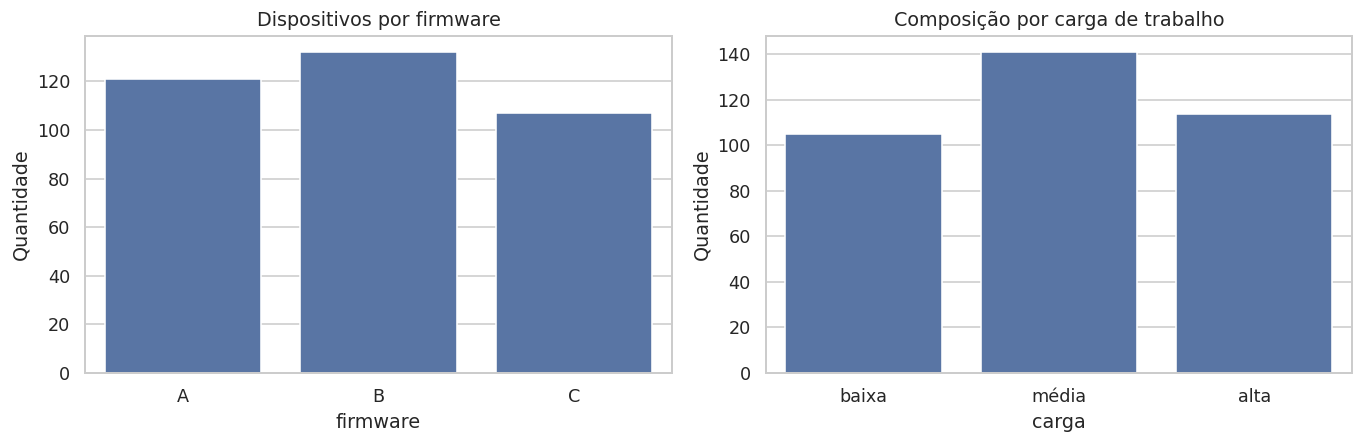

In [7]:
freq = dados['firmware'].value_counts().sort_index().to_frame('n')
freq['proporcao'] = freq['n']/len(dados)
display(freq)
fig, axs = plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=dados,x='firmware',order=['A','B','C'],ax=axs[0])
sns.countplot(data=dados,x='carga',order=['baixa','média','alta'],ax=axs[1])
axs[0].set(title='Dispositivos por firmware',ylabel='Quantidade')
axs[1].set(title='Composição por carga de trabalho',ylabel='Quantidade')
plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

Comparações com tamanhos diferentes são possíveis, mas exigem considerar incerteza e variabilidade. Um grupo pequeno pode produzir uma média instável. Registrar o número de observações junto com cada estatística.

## 9. Média, mediana, moda e médias aparadas

**Pergunta:** qual valor representa o centro? A média aritmética é $ar{x}=sum x_i/n$. Ela utiliza todos os valores e é relevante para custos totais e consumo esperado. A mediana divide a amostra ordenada ao meio e é mais resistente a extremos. A moda é o valor mais frequente; em dados contínuos, uma moda empírica pode depender do arredondamento e ser pouco informativa.

A média aparada remove uma fração previamente definida de cada cauda antes de calcular a média. Ela descreve um parâmetro diferente da média original. Não deve ser apresentada como se medisse exatamente a mesma coisa.

**Quando usar:** média para comportamento esperado e agregação; mediana para uma leitura robusta do centro; moda para categorias ou valores discretos. **O que se busca descobrir:** se a conclusão sobre “típico” muda conforme extremos e assimetria.

Normalidade não é requisito para calcular nem interpretar média e outras medidas descritivas. Em uma distribuição assimétrica, a média continua respondendo a uma pergunta válida, mas pode não representar bem uma observação típica. Sempre declarar qual aspecto se deseja resumir.

Categoria de carga modal: ['média']


,valor
média_ms,32.891359
mediana_ms,32.823389
média_aparada_10pct_ms,32.753270


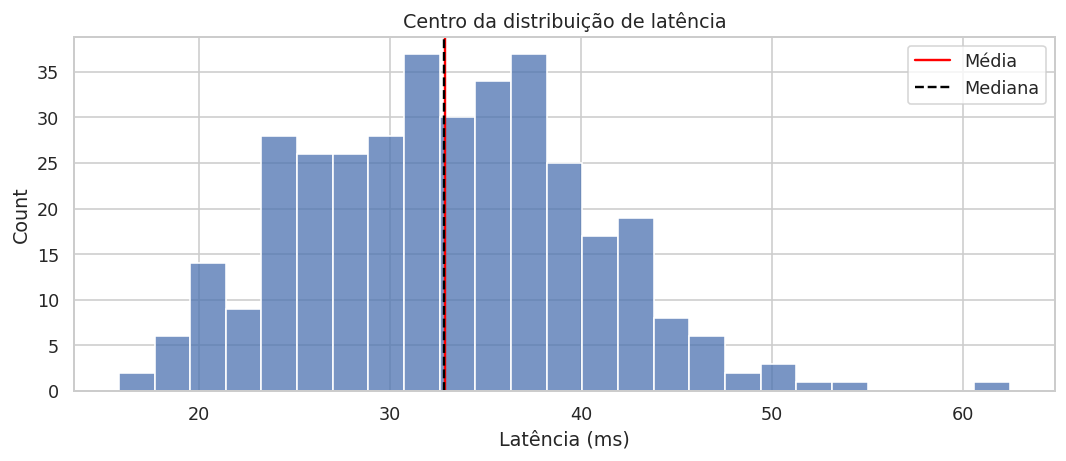

In [8]:
x = dados['latencia_ms']
resumo_centro = pd.Series({'média_ms':x.mean(),'mediana_ms':x.median(),
                           'média_aparada_10pct_ms':stats.trim_mean(x,0.10)})
display(resumo_centro.to_frame('valor'))
print('Categoria de carga modal:', dados['carga'].mode().astype(str).tolist())
fig, ax = plt.subplots()
sns.histplot(x,bins=25,ax=ax)
ax.axvline(x.mean(),color='red',label='Média')
ax.axvline(x.median(),color='black',linestyle='--',label='Mediana')
ax.set(title='Centro da distribuição de latência',xlabel='Latência (ms)');ax.legend();plt.show()

**Interpretação do exemplo e decisão seguinte**

Se média e mediana diferem, investigar assimetria ou mistura de grupos, sem presumir erro de coleta. Para capacidade, consumo ou custo agregado, substituir a média pela mediana pode responder à pergunta errada.

## 10. Variância, desvio padrão, amplitude e coeficiente de variação

**Pergunta:** quanto os valores variam? Variância amostral é $s^2=sum(x_i-ar{x})^2/(n-1)$. O desvio padrão é sua raiz e possui a mesma unidade da variável. A amplitude é máximo menos mínimo, mas depende fortemente dos extremos e do tamanho da amostra.

O coeficiente de variação é $100s/ar{x}$, permitindo comparação relativa quando há escala de razão, média positiva e interpretação adequada. Não é apropriado para temperatura em Celsius, porque zero °C não representa ausência de temperatura e razões nessa escala não são fisicamente absolutas. Também se torna instável quando a média está perto de zero.

**O que se busca descobrir:** estabilidade e variabilidade relativa. **Quando usar:** comparar dispersão de consumo entre condições ou verificar variabilidade de tempos. **Erro a evitar:** confundir desvio padrão das observações com erro padrão da média. O primeiro descreve variabilidade individual; o segundo descreve precisão da estimativa.

In [9]:
dispersao = dados.groupby('firmware',observed=True)['latencia_ms'].agg(['count','mean','std','min','max'])
dispersao['variancia'] = dados.groupby('firmware')['latencia_ms'].var(ddof=1)
dispersao['amplitude'] = dispersao['max']-dispersao['min']
dispersao['cv_pct'] = 100*dispersao['std']/dispersao['mean']
display(dispersao.round(3))
print('ddof=1 utiliza n−1 no cálculo amostral.')

ddof=1 utiliza n−1 no cálculo amostral.


,count,mean,std,min,max,variancia,amplitude,cv_pct
firmware,,,,,,,,
A,121,36.257,6.870,21.992,54.632,47.198,32.640,18.948
B,132,32.759,6.907,19.021,62.477,47.710,43.456,21.085
C,107,29.248,6.622,15.794,43.277,43.855,27.484,22.642


**Interpretação do exemplo e decisão seguinte**

Dois grupos podem ter a mesma média e dispersões muito diferentes. Em engenharia, instabilidade pode ser importante mesmo quando não há diferença no desempenho médio. Complementar estas medidas com quantis e gráficos.

## 11. Quantis, IQR, MAD e métricas de cauda

**Pergunta:** onde estão as caudas e qual é a dispersão robusta? Quantil de 0,95 indica um ponto abaixo do qual ficam aproximadamente 95% dos valores amostrais, segundo o método de interpolação adotado. Em serviços computacionais, p95 e p99 ajudam a avaliar tempos elevados que a média pode esconder.

O intervalo interquartil é Q3 − Q1 e descreve a extensão dos 50% centrais. O MAD é a mediana de |x − mediana(x)|. A multiplicação por aproximadamente 1,4826 produz uma escala calibrada ao desvio padrão sob normalidade, mas não torna a distribuição normal.

**Quando usar:** latências com caudas longas, medidas com extremos ou descrição robusta. **O que se busca descobrir:** desempenho típico versus experiência nos piores casos frequentes. **Limite:** estimar p99 com poucas observações é instável; em 100 observações, ele é influenciado por cerca de uma posição na cauda. Quantis amostrais não são garantias futuras.

IQR: 10.351 ms | MAD: 5.152 ms


,latencia_ms
0.05,20.837151
0.25,27.409003
0.50,32.823389
0.75,37.760142
0.95,44.348631
0.99,50.153962


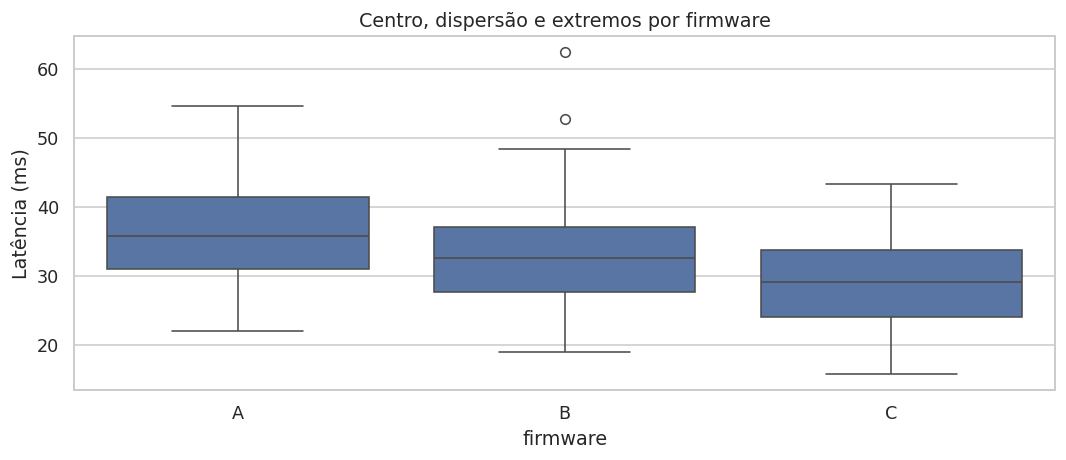

In [10]:
q = x.quantile([0.05,0.25,0.50,0.75,0.95,0.99])
iqr = q.loc[0.75]-q.loc[0.25]
mad = (x-x.median()).abs().median()
display(q.to_frame('latencia_ms'))
print('IQR:',round(iqr,3),'ms | MAD:',round(mad,3),'ms')
fig, ax = plt.subplots()
sns.boxplot(data=dados,x='firmware',y='latencia_ms',order=['A','B','C'],ax=ax)
ax.set(title='Centro, dispersão e extremos por firmware',ylabel='Latência (ms)');plt.show()

**Interpretação do exemplo e decisão seguinte**

Pontos fora dos bigodes são candidatos a investigação, não medições automaticamente erradas. A regra usual de 1,5 IQR é uma convenção visual. Se o SLA depende da cauda, reportar p95/p99 com incerteza e quantidade de dados.

## 12. Histogramas, densidade, ECDF e escolha do gráfico

O histograma distribui observações em intervalos. Seu aspecto depende do número e das bordas das classes. Uma curva de densidade suaviza os dados, mas também depende da largura de banda; pode criar ou esconder picos. Ela não corresponde à probabilidade de um ponto exato numa variável contínua.

A função de distribuição empírica (ECDF) mostra a proporção acumulada até cada valor. Ela responde diretamente a perguntas como “qual fração das respostas ocorreu em até 40 ms?”. A ECDF não depende da escolha de classes.

**O que se busca descobrir:** assimetria, concentração, caudas e diferenças de distribuição. **Quando usar:** sempre que um único resumo for insuficiente. **Erro a evitar:** interpretar duas curvas suavizadas como evidência confirmatória sem considerar incerteza e desenho. Escalas logarítmicas podem facilitar caudas longas, mas devem ser identificadas e não podem receber valores negativos ou zero sem tratamento explícito.

Fração em até 40 ms: 0.729


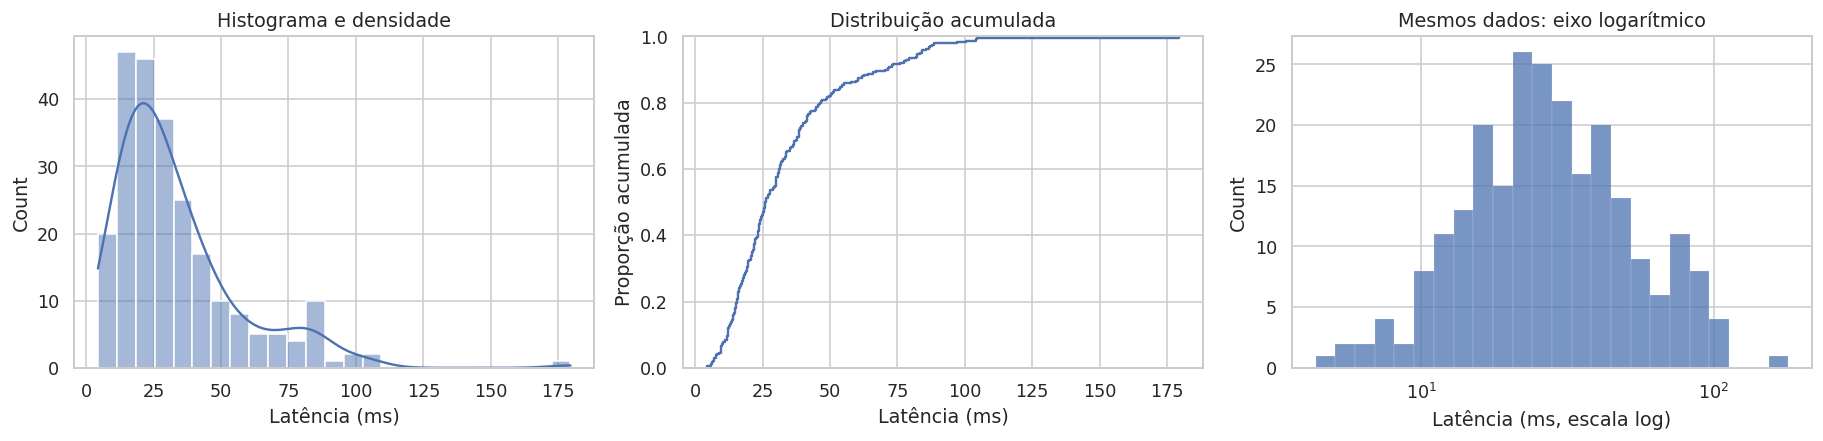

In [11]:
fig, axs = plt.subplots(1,3,figsize=(16,4))
sns.histplot(latencia_cauda,bins=25,kde=True,ax=axs[0])
axs[0].set(title='Histograma e densidade',xlabel='Latência (ms)')
sns.ecdfplot(latencia_cauda,ax=axs[1]);axs[1].set(title='Distribuição acumulada',xlabel='Latência (ms)',ylabel='Proporção acumulada')
sns.histplot(latencia_cauda,bins=np.geomspace(latencia_cauda.min(),latencia_cauda.max(),25),ax=axs[2])
axs[2].set_xscale('log');axs[2].set(title='Mesmos dados: eixo logarítmico',xlabel='Latência (ms, escala log)')
plt.tight_layout();plt.show()
print('Fração em até 40 ms:',round(float((latencia_cauda<=40).mean()),3))

**Interpretação do exemplo e decisão seguinte**

Uma cauda à direita representa respostas raras muito demoradas. A mudança de escala melhora a visualização, mas não modifica os dados originais. Para comparar categorias, utilizar curvas com cores e denominadores claramente identificados.

## 13. Assimetria, curtose e mistura de populações

Assimetria descreve falta de simetria. Assimetria positiva costuma acompanhar uma cauda mais longa à direita. Curtose relaciona-se à forma e às caudas; a curtose excedente da normal é zero na convenção de Fisher. Ela não deve ser interpretada apenas como “altura do pico”.

Valores agregados podem misturar distribuições diferentes. CPU de dispositivos em carga baixa, média e alta pode gerar uma distribuição com vários picos. Isso não significa necessariamente falha ou necessidade de transformar os dados. Pode significar que há subgrupos substantivos.

**Quando usar:** complementar a inspeção gráfica e decidir se a agregação esconde perfis. **O que se busca descobrir:** caudas e heterogeneidade. **Limite:** assimetria e curtose são sensíveis a extremos e não determinam sozinhas uma família de distribuição nem o teste correto.

Assimetria da latência: 0.273
Curtose excedente: 0.135


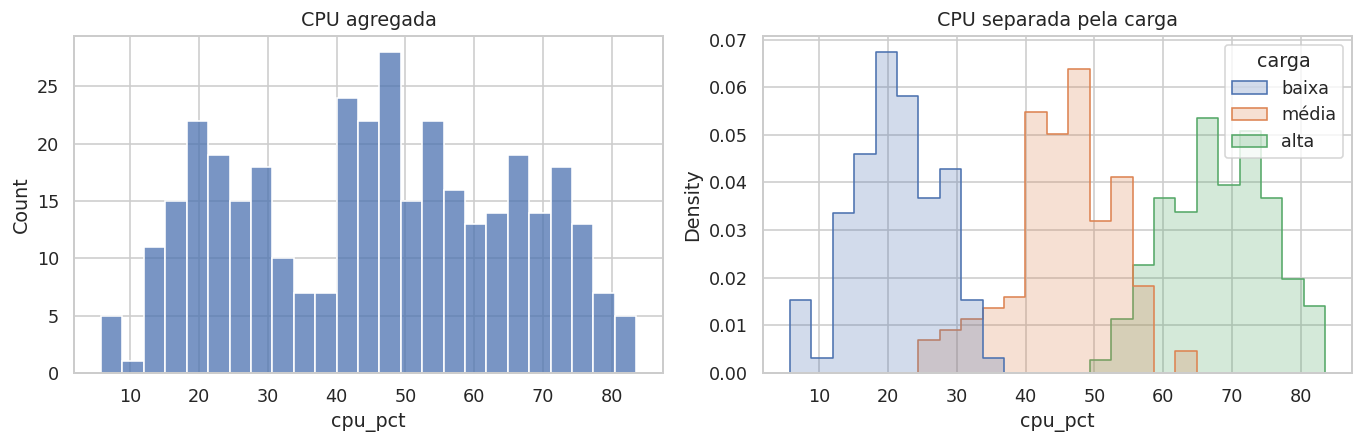

In [12]:
print('Assimetria da latência:',round(stats.skew(x,bias=False),3))
print('Curtose excedente:',round(stats.kurtosis(x,fisher=True,bias=False),3))
fig, axs = plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=dados,x='cpu_pct',bins=25,ax=axs[0])
sns.histplot(data=dados,x='cpu_pct',hue='carga',bins=25,element='step',stat='density',common_norm=False,ax=axs[1])
axs[0].set_title('CPU agregada');axs[1].set_title('CPU separada pela carga')
plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

A separação por carga ajuda a explicar a distribuição agregada. Se a pergunta exige comparar firmware, considerar se a carga também altera a resposta. A análise condicionada será retomada na regressão.

## 14. Estatística por grupos e risco de conclusões agregadas

Uma média global pode esconder relações diferentes dentro de subgrupos. Estratificar por carga, local ou modelo de equipamento permite verificar composição e heterogeneidade. Porém, criar muitos grupos reduz a quantidade de observações por combinação e aumenta a instabilidade.

O paradoxo de Simpson ocorre quando uma relação agregada muda de direção ou desaparece após estratificação. Nem toda diferença entre análise global e estratificada constitui o paradoxo, mas a possibilidade lembra que composição importa. Ajustar por uma variável também não é sempre correto: ela pode ser consequência do tratamento, mediadora ou variável de seleção.

**O que se busca descobrir:** se a comparação está misturando contextos. **Quando usar:** estudos observacionais e comparações com cargas diferentes. **Erro a evitar:** afirmar que ajuste estatístico elimina todos os confundidores; apenas variáveis medidas e uma estrutura adequada podem ser consideradas.

count   mean  median   std
firmware carga                            
A        baixa     28  27.54   28.08  2.80
         média     50  35.17   34.80  3.58
         alta      43  43.20   42.87  3.65
B        baixa     37  26.23   25.11  6.71
         média     53  32.57   32.27  4.28
         alta      42  38.74   37.67  3.81
C        baixa     40  22.74   22.12  3.83
         média     38  30.50   30.82  3.43
         alta      29  36.58   36.72  3.41

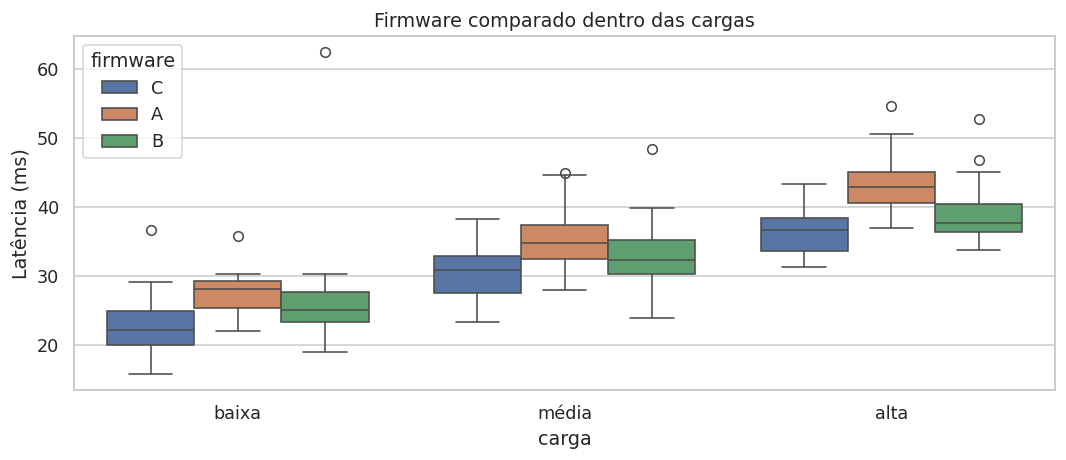

In [13]:
resumo_grupos = dados.groupby(['firmware','carga'],observed=True)['latencia_ms'].agg(['count','mean','median','std'])
display(resumo_grupos.round(2))
fig, ax = plt.subplots()
sns.boxplot(data=dados,x='carga',y='latencia_ms',hue='firmware',ax=ax)
ax.set(title='Firmware comparado dentro das cargas',ylabel='Latência (ms)');plt.show()

**Interpretação do exemplo e decisão seguinte**

Verificar primeiro o número de dispositivos por célula. Se um contexto possuir poucos registros, declarar a limitação. A análise por grupos orienta perguntas e modelos; não substitui um desenho experimental bem definido.

## 15. Investigar extremos e realizar análise de sensibilidade

Extremos podem alterar média, correlação e regressão. A regra de IQR identifica valores abaixo de Q1 − 1,5 IQR ou acima de Q3 + 1,5 IQR. O escore z mede distância à média em desvios padrão. Esses critérios descrevem distância estatística, não veracidade física.

**O que se busca descobrir:** quais observações influenciam o resumo e se a conclusão depende delas. **Quando usar:** antes de interpretações relevantes, especialmente em pequenas amostras. **Procedimento:** identificar, verificar origem, registrar justificativa e comparar análise completa com uma análise de sensibilidade. Excluir somente porque o p-valor melhora é inadequado.

No exemplo, um tempo elevado foi gerado como evento real e será mantido. A versão sem candidatos será apenas uma comparação de sensibilidade, não uma base automaticamente “corrigida”. Um detector univariado também pode deixar passar combinações incomuns de várias variáveis.

In [14]:
q1,q3 = x.quantile([0.25,0.75]);limite_inf=q1-1.5*(q3-q1);limite_sup=q3+1.5*(q3-q1)
marcados = (x<limite_inf)|(x>limite_sup)
display(dados.loc[marcados,['dispositivo','firmware','carga','latencia_ms']])
sensibilidade = pd.DataFrame({'completa':x.agg(['count','mean','median','std']),
                             'sem_candidatos_apenas_sensibilidade':x[~marcados].agg(['count','mean','median','std'])})
display(sensibilidade)
print('A base principal permanece inalterada:',len(dados),'linhas.')

A base principal permanece inalterada: 360 linhas.


,dispositivo,firmware,carga,latencia_ms
7,D007,B,baixa,62.476910
335,D335,A,alta,54.631577


,completa,sem_candidatos_apenas_sensibilidade
count,360.000000,358.000000
mean,32.891359,32.747991
median,32.823389,32.780018
std,7.342683,7.100752


**Interpretação do exemplo e decisão seguinte**

Se uma conclusão mudar muito, ela é sensível a extremos e deve ser apresentada com essa informação. Se todos os extremos pertencem a uma condição operacional real, removê-los pode apagar o fenômeno de interesse.

## 16. Distribuições de probabilidade e escolha pelo fenômeno

Uma distribuição de probabilidade é um modelo para a variabilidade. Normal descreve uma variável contínua simétrica em certas situações; lognormal descreve valores positivos com assimetria; Bernoulli descreve um evento binário; binomial conta sucessos em um número definido de tentativas; Poisson modela contagens sob hipóteses específicas.

A escolha deve começar pelo suporte e pelo mecanismo. Uma variável contínua positiva não pode ser representada adequadamente por um modelo que atribui probabilidade relevante a valores impossíveis. Uma contagem não possui a mesma estrutura de uma temperatura. Em Poisson, média e variância condicionais são iguais; muitos dados reais apresentam variância maior.

**O que se busca descobrir:** que tipo de incerteza é compatível com a variável. **Quando usar:** simulação, inferência e modelos. **Limite:** semelhança visual não comprova a distribuição. Estimativas, diagnóstico, plausibilidade e incerteza precisam ser considerados.

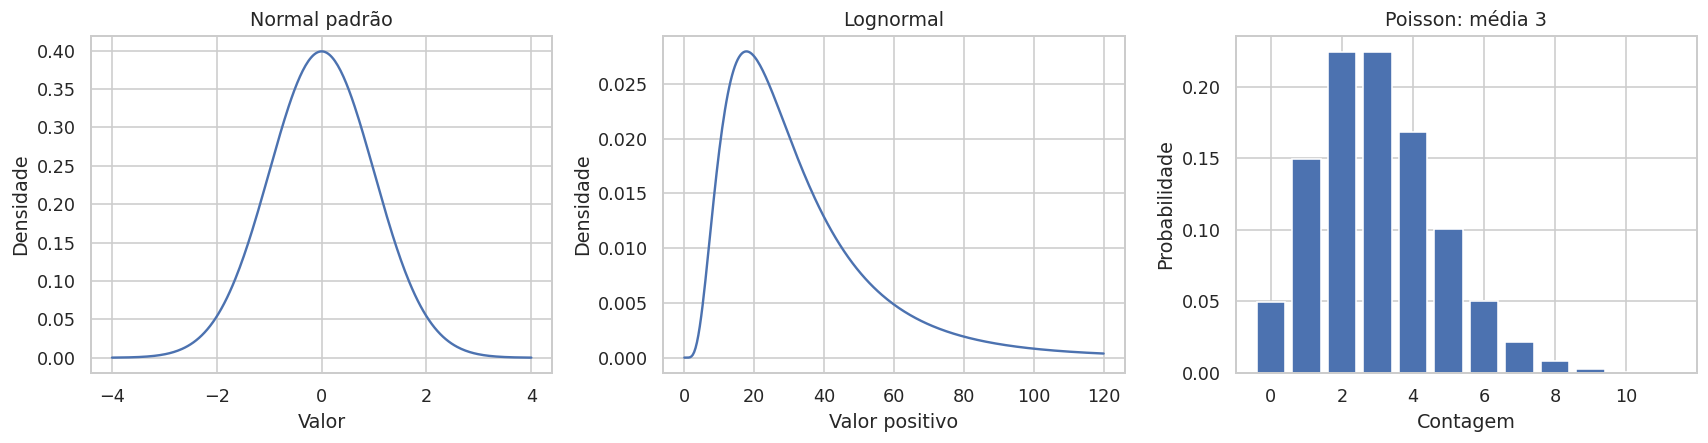

In [15]:
fig, axs = plt.subplots(1,3,figsize=(15,4))
z = np.linspace(-4,4,300);axs[0].plot(z,stats.norm.pdf(z));axs[0].set(title='Normal padrão',xlabel='Valor',ylabel='Densidade')
zpos=np.linspace(0.01,120,300);axs[1].plot(zpos,stats.lognorm.pdf(zpos,s=0.65,scale=np.exp(3.3)))
axs[1].set(title='Lognormal',xlabel='Valor positivo',ylabel='Densidade')
k=np.arange(0,12);axs[2].bar(k,stats.poisson.pmf(k,mu=3));axs[2].set(title='Poisson: média 3',xlabel='Contagem',ylabel='Probabilidade')
plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

Densidade não é probabilidade pontual. Para variáveis contínuas, a probabilidade de um intervalo corresponde à área sob a curva. Em variáveis discretas, cada barra representa a probabilidade da contagem correspondente.

## 17. Avaliar normalidade com gráficos e Shapiro-Wilk

**Pergunta:** a distribuição analisada é compatível com uma forma normal para o uso pretendido? O gráfico Q-Q compara quantis amostrais com quantis de uma normal. Desvios sistemáticos da reta sugerem assimetria ou caudas diferentes. Shapiro-Wilk testa uma hipótese nula de normalidade.

p pequeno sugere incompatibilidade com essa hipótese; p grande não prova normalidade. Em amostras grandes, desvios pequenos podem ser detectados; em pequenas, desvios relevantes podem passar despercebidos. A escolha do método não deve ser automatizada apenas como “Shapiro aprovou, usar teste paramétrico; reprovou, usar não paramétrico”.

**Quando usar:** como diagnóstico junto ao desenho, gráfico, tamanho amostral, extremos e robustez do procedimento. **O que se busca descobrir:** se uma aproximação normal é plausível onde realmente importa. No teste pareado, interessam as diferenças; em regressão, pressupostos clássicos referem-se aos erros condicionais. Não é necessário que todos os preditores ou toda a base agregada sejam normais.

Para testes com restrições de tamanho ou advertências da implementação, consultar a documentação. Não testar centenas de colunas e tratar cada resultado como diagnóstico isolado sem considerar multiplicidade.

Shapiro-Wilk: Normal simulada | estatística = 0.9896 | p = 0.50316
Não há evidência suficiente para rejeitar a hipótese nula no nível definido.
Shapiro-Wilk: Latência assimétrica | estatística = 0.8906 | p = 6.6874e-08
Há evidência contra a hipótese nula no nível definido.


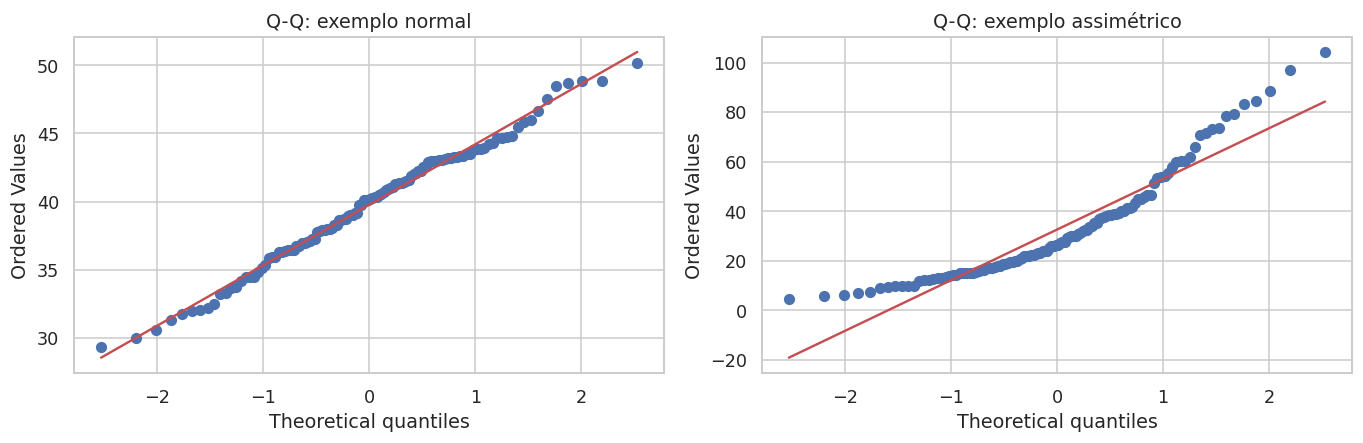

In [16]:
normal_exemplo = np.random.default_rng(31).normal(40,5,120)
assimetrico_exemplo = latencia_cauda[:120]
fig, axs = plt.subplots(1,2,figsize=(12,4))
stats.probplot(normal_exemplo,dist='norm',plot=axs[0]);axs[0].set_title('Q-Q: exemplo normal')
stats.probplot(assimetrico_exemplo,dist='norm',plot=axs[1]);axs[1].set_title('Q-Q: exemplo assimétrico')
plt.tight_layout();plt.show()
for nome,v in [('Normal simulada',normal_exemplo),('Latência assimétrica',assimetrico_exemplo)]:
    resultado_teste('Shapiro-Wilk: '+nome,stats.shapiro(v))

**Interpretação do exemplo e decisão seguinte**

Os exemplos foram gerados com mecanismos conhecidos. Em dados reais, a origem não é conhecida. Mesmo que Shapiro rejeite normalidade, média, mediana e desvio continuam válidos como descrições; a decisão inferencial depende do procedimento e da pergunta.

## 18. Transformações logarítmicas e Yeo-Johnson

Transformações podem reduzir assimetria, estabilizar variância ou tornar uma relação mais simples. Logaritmo exige valores positivos e converte efeitos multiplicativos em diferenças aditivas. Uma diferença no log corresponde a uma razão na escala original. Yeo-Johnson admite zero e valores negativos, ajustando um parâmetro a partir dos dados.

**Quando usar:** quando há justificativa para a nova escala ou evidência de inadequação na modelagem. **O que se busca descobrir:** se uma representação alternativa descreve melhor o fenômeno. **Erro a evitar:** transformar até obter um p-valor de normalidade desejado sem documentar a busca. Normalidade não é um objetivo universal.

Em previsão ou atribuição de novos equipamentos, parâmetros da transformação devem ser ajustados no treinamento e depois aplicados aos demais dados. Transformar log e aplicar exponencial à média do log produz uma média geométrica, não a média aritmética original. Voltar previsões à escala original pode exigir correção de viés.

Média aritmética: 33.542 ms
Média geométrica: 27.092 ms
Parâmetro Yeo-Johnson: [-0.046615]


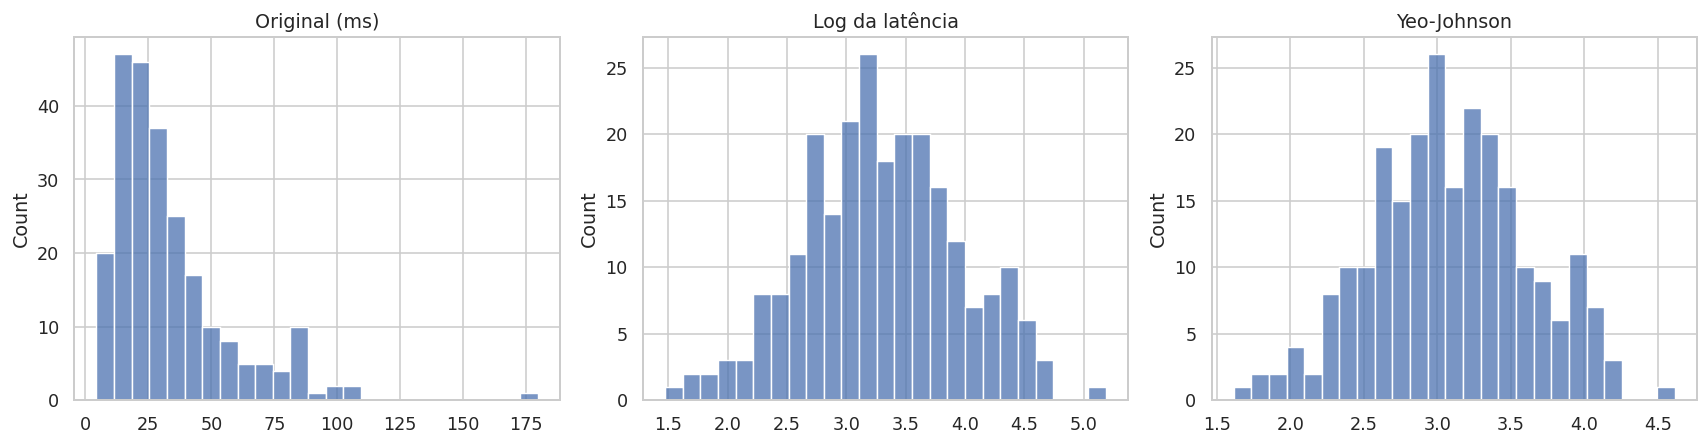

In [17]:
log_latencia = np.log(latencia_cauda)
yj = PowerTransformer(method='yeo-johnson',standardize=False)
latencia_yj = yj.fit_transform(latencia_cauda.reshape(-1,1)).ravel()
fig, axs = plt.subplots(1,3,figsize=(15,4))
for ax,v,titulo in zip(axs,[latencia_cauda,log_latencia,latencia_yj],['Original (ms)','Log da latência','Yeo-Johnson']):
    sns.histplot(v,bins=25,ax=ax);ax.set_title(titulo)
plt.tight_layout();plt.show()
print('Média aritmética:',round(latencia_cauda.mean(),3),'ms')
print('Média geométrica:',round(np.exp(log_latencia.mean()),3),'ms')
print('Parâmetro Yeo-Johnson:',yj.lambdas_)

**Interpretação do exemplo e decisão seguinte**

Os gráficos têm escalas diferentes. Comparar forma sem esquecer significado. Se a pergunta é diferença absoluta de milissegundos, um teste na escala log responde a uma pergunta diferente, mais próxima de comparação relativa.

## 19. Amostragem, erro padrão e teorema central do limite

A distribuição dos valores individuais e a distribuição de uma estimativa são objetos diferentes. Para observações independentes com variância finita, o erro padrão da média é estimado por $s/\sqrt{n}$. Ele tende a diminuir com amostras maiores, mesmo que o desvio padrão individual permaneça semelhante.

O teorema central do limite descreve condições em que a distribuição da média padronizada se aproxima da normal. Ele não transforma os dados originais em normais e não estabelece um tamanho universal, como “n maior que 30 resolve tudo”. Assimetria extrema, dependência e caudas muito pesadas podem exigir cuidados adicionais.

**O que se busca descobrir:** como a estimativa varia entre amostras e por que precisão aumenta com informação independente. **Quando usar:** interpretar intervalos e planejar amostragem. A simulação utiliza uma população lognormal de variância finita e sorteios independentes. Para dados temporais ou agrupados por máquina, esta simulação não representa a dependência real.

Desvio individual: 7.343 ms
Erro padrão da média: 0.387 ms


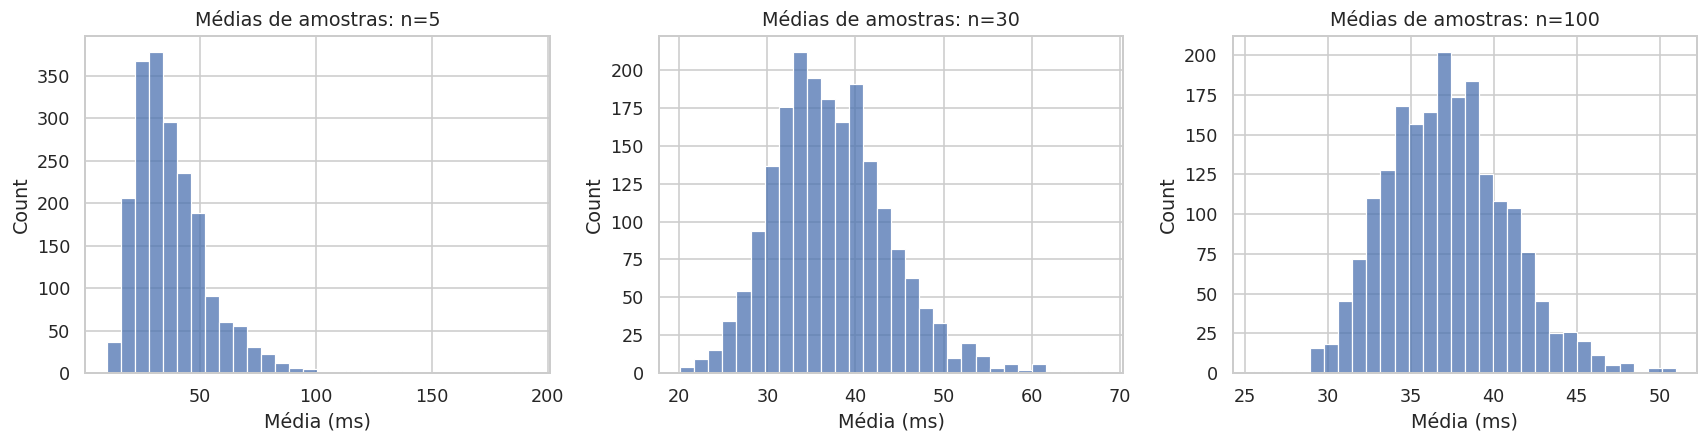

In [18]:
rclt=np.random.default_rng(51)
populacao=rclt.lognormal(mean=3.3,sigma=0.8,size=100000)
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,tamanho in zip(axs,[5,30,100]):
    medias=rclt.choice(populacao,size=(2000,tamanho),replace=True).mean(axis=1)
    sns.histplot(medias,bins=30,ax=ax);ax.set(title=f'Médias de amostras: n={tamanho}',xlabel='Média (ms)')
plt.tight_layout();plt.show()
print('Desvio individual:',round(x.std(ddof=1),3),'ms')
print('Erro padrão da média:',round(x.std(ddof=1)/np.sqrt(len(x)),3),'ms')

**Interpretação do exemplo e decisão seguinte**

A distribuição das médias fica mais concentrada com n maior. Não interpretar o erro padrão como dispersão das latências individuais. Aumentar leituras da mesma unidade não substitui aumentar unidades independentes.

## 20. Intervalo de confiança para a média

**Pergunta:** qual intervalo é compatível com a média populacional sob o procedimento adotado? Um intervalo t utiliza média, erro padrão e quantil da distribuição t. É exato sob observações independentes normais e pode ser aproximado em outras situações quando a distribuição da média é bem comportada.

Um IC de 95% possui interpretação de cobertura do procedimento em repetidas amostragens, sob os pressupostos. Não significa que 95% dos dispositivos estão dentro do intervalo. Também não significa, na interpretação frequentista, que há 95% de probabilidade de o parâmetro fixo estar naquele intervalo específico.

**O que se busca descobrir:** precisão da média estimada. **Quando usar:** estimativas com unidade e magnitude relevantes. **Limite:** um intervalo estreito pode ser sistematicamente errado se houver amostragem enviesada. Dependência entre observações exige cálculo de incerteza apropriado ao desenho.

,firmware,n,media_ms,ic_inf,ic_sup
0,A,121,36.257,35.020,37.494
1,B,132,32.759,31.570,33.949
2,C,107,29.248,27.979,30.517


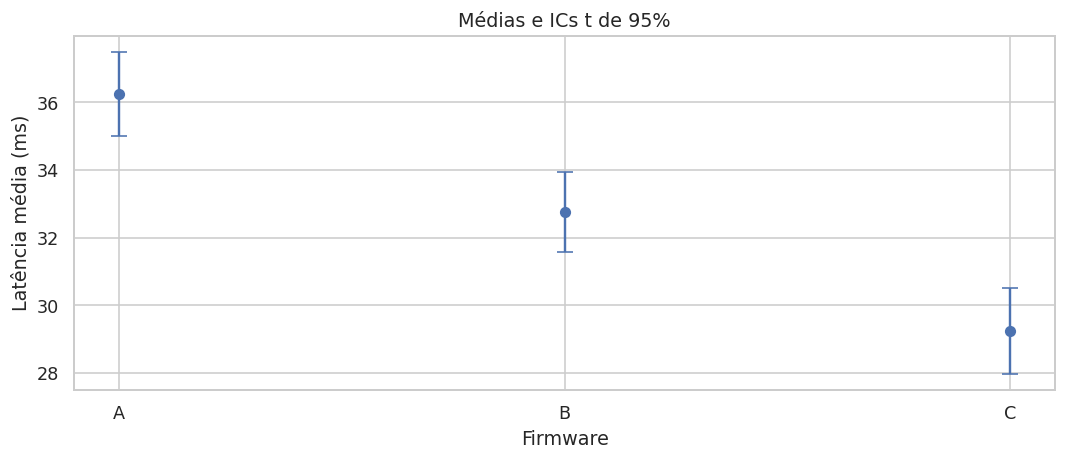

In [19]:
def ic_media(v,confianca=0.95):
    v=np.asarray(v,dtype=float);n=len(v);ep=stats.sem(v)
    margem=stats.t.ppf((1+confianca)/2,df=n-1)*ep
    return float(v.mean()),float(v.mean()-margem),float(v.mean()+margem)
tabela_ic=[]
for grupo,g in dados.groupby('firmware'):
    media,inf,sup=ic_media(g['latencia_ms'])
    tabela_ic.append({'firmware':grupo,'n':len(g),'media_ms':media,'ic_inf':inf,'ic_sup':sup})
tabela_ic=pd.DataFrame(tabela_ic);display(tabela_ic.round(3))
fig,ax=plt.subplots()
ax.errorbar(tabela_ic['firmware'],tabela_ic['media_ms'],
            yerr=[tabela_ic['media_ms']-tabela_ic['ic_inf'],tabela_ic['ic_sup']-tabela_ic['media_ms']],fmt='o',capsize=5)
ax.set(title='Médias e ICs t de 95%',xlabel='Firmware',ylabel='Latência média (ms)');plt.show()

**Interpretação do exemplo e decisão seguinte**

Sobreposição de ICs individuais não constitui um teste formal da diferença. Para comparar A e B, estimar diretamente a diferença e seu intervalo. A interpretação deve informar que há mistura de cargas e que a precisão não elimina variações entre dispositivos.

## 21. Bootstrap para média, mediana e diferenças

Bootstrap reamostra unidades observadas com reposição para aproximar a variabilidade de uma estatística. É útil quando uma fórmula simples não está disponível ou quando se deseja estimar incerteza da mediana, quantil ou diferença. Não é um mecanismo que resolve qualquer problema de amostragem.

O exemplo usa intervalo percentil: os quantis da distribuição bootstrap delimitam o IC aproximado. Há outras opções, como BCa, com vantagens e restrições próprias. Para caudas, amostras pequenas ou estatísticas problemáticas, a cobertura pode ser inadequada. A quantidade de reamostragens reduz ruído da simulação, mas não cria informação nova.

**O que se busca descobrir:** como a estatística mudaria sob reamostragem semelhante. **Pressuposto:** unidades independentes e amostra razoavelmente representativa. Para placas pareadas, reamostrar pares inteiros; para máquinas com leituras repetidas, reamostrar máquinas ou utilizar uma estrutura adequada; para séries temporais, considerar blocos.

Mediana observada: 26.139 ms
IC percentil aproximado: [24.086 30.011] ms


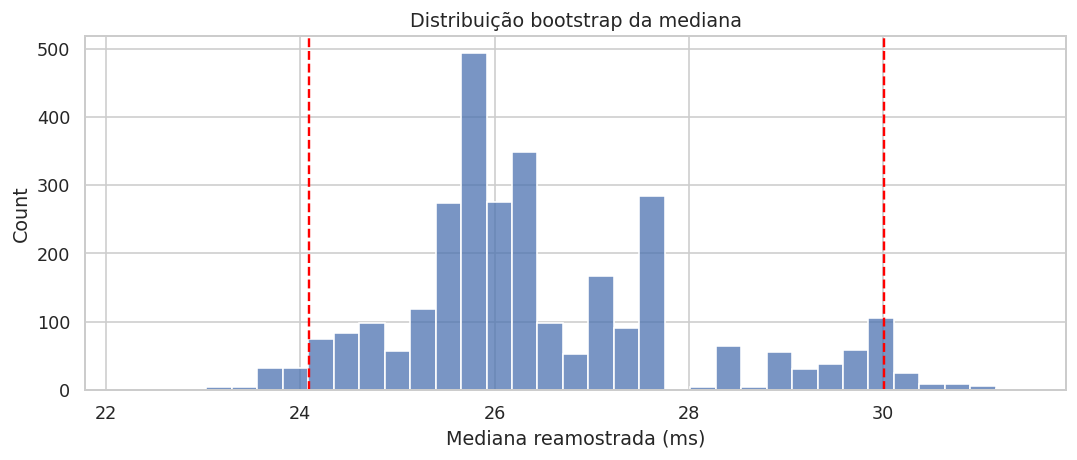

In [20]:
def bootstrap_estatistica(v,funcao=np.median,b=3000,semente=11):
    v=np.asarray(v);r=np.random.default_rng(semente)
    amostras=r.choice(v,size=(b,len(v)),replace=True)
    valores=np.array([funcao(a) for a in amostras])
    return valores,np.quantile(valores,[0.025,0.975])
boot_mediana,ic_mediana=bootstrap_estatistica(latencia_cauda)
print('Mediana observada:',round(np.median(latencia_cauda),3),'ms')
print('IC percentil aproximado:',np.round(ic_mediana,3),'ms')
fig,ax=plt.subplots();sns.histplot(boot_mediana,bins=35,ax=ax)
for limite in ic_mediana:ax.axvline(limite,color='red',linestyle='--')
ax.set(title='Distribuição bootstrap da mediana',xlabel='Mediana reamostrada (ms)');plt.show()
registrar('Bootstrap mediana',estimativa=float(np.median(latencia_cauda)),ic_inf=float(ic_mediana[0]),ic_sup=float(ic_mediana[1]))

**Interpretação do exemplo e decisão seguinte**

A distribuição mostrada é da estimativa, não das latências individuais. Um IC bootstrap não autoriza generalizar dados de conveniência para uma população diferente. O desenho e a unidade de reamostragem continuam centrais.

## 22. Proporções, eventos raros e intervalo de Wilson

**Pergunta:** qual é a frequência de violação de SLA e sua incerteza? Proporção é número de eventos dividido pelo número de oportunidades. Sempre apresentar numerador e denominador. Dez falhas em 20 tentativas representam uma situação diferente de dez falhas em 20 mil.

O intervalo normal simples pode funcionar mal com amostras pequenas ou proporções perto de zero e um. Wilson é uma alternativa útil para um modelo binomial de tentativas independentes com probabilidade constante. Um resultado sem falhas observadas não comprova risco populacional zero.

**O que se busca descobrir:** probabilidade de evento e precisão. **Quando usar:** falha de transmissão, aprovação de testes, violação de limite. **Limite:** eventos dentro do mesmo dispositivo ou período podem ser dependentes; a fórmula binomial simples não reconhece essa estrutura.

Exemplo de 0 falhas em 20 tentativas, IC Wilson: (0.0, 0.1611251580528194)


,firmware,eventos,n,proporcao,ic_inf,ic_sup
0,A,18,121,0.1488,0.0962,0.2229
1,B,9,132,0.0682,0.0363,0.1245
2,C,14,107,0.1308,0.0796,0.2077


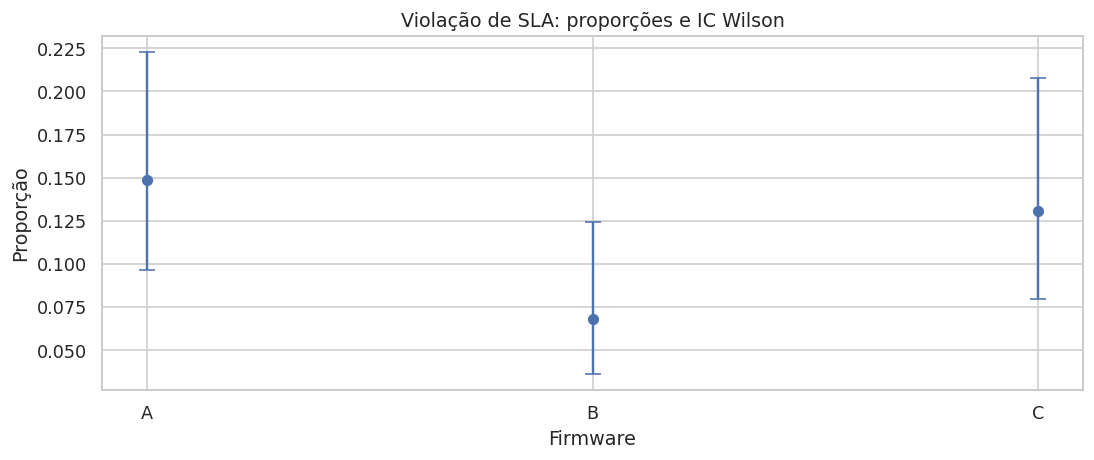

In [21]:
proporcoes=[]
for nome,g in dados.groupby('firmware'):
    eventos=int(g['violacao_sla'].sum());total=len(g)
    inf,sup=proportion_confint(eventos,total,alpha=0.05,method='wilson')
    proporcoes.append({'firmware':nome,'eventos':eventos,'n':total,'proporcao':eventos/total,'ic_inf':inf,'ic_sup':sup})
proporcoes=pd.DataFrame(proporcoes);display(proporcoes.round(4))
print('Exemplo de 0 falhas em 20 tentativas, IC Wilson:',proportion_confint(0,20,method='wilson'))
fig,ax=plt.subplots();ax.errorbar(proporcoes['firmware'],proporcoes['proporcao'],
 yerr=[proporcoes['proporcao']-proporcoes['ic_inf'],proporcoes['ic_sup']-proporcoes['proporcao']],fmt='o',capsize=5)
ax.set(title='Violação de SLA: proporções e IC Wilson',ylabel='Proporção',xlabel='Firmware');plt.show()

**Interpretação do exemplo e decisão seguinte**

Taxas diferentes podem refletir incerteza ou composição da carga. Para comparação direta, utilizar diferença de proporções e um teste ou modelo adequado. Distinguir proporção por dispositivo de taxa por tempo de exposição.

## 23. Hipóteses, p-valor, significância e relevância prática

Uma hipótese nula expressa uma referência, como diferença média igual a zero. Uma hipótese alternativa define o tipo de discrepância investigada. O p-valor é a probabilidade, supondo a hipótese nula e o modelo, de obter uma estatística tão ou mais extrema que a observada conforme o procedimento.

Ele não é a probabilidade de a hipótese nula ser verdadeira, nem o tamanho do efeito, nem a chance de replicação. O nível alfa deve ser definido antes da análise confirmatória. p ≥ alfa significa evidência insuficiente para rejeitar, não igualdade comprovada. p < alfa também não significa importância de engenharia.

**O que se busca descobrir:** compatibilidade dos dados com uma hipótese específica. **Quando usar:** quando existe uma pergunta inferencial planejada e um desenho válido. **Erro a evitar:** procurar entre dezenas de testes aquele que fornece p pequeno. Apresentar estimativa, IC, tamanho amostral, teste, pressupostos e contexto.

O exemplo ilustra que uma diferença muito pequena pode ser detectável em uma amostra enorme. O procedimento é uma simulação de conceito, não justificativa para descartar p-valores nem para escolher tamanhos de amostra após olhar o resultado.

In [22]:
rsig=np.random.default_rng(63)
a_peq=rsig.normal(40,5,25);b_peq=rsig.normal(40.2,5,25)
a_gr=rsig.normal(40,5,50000);b_gr=rsig.normal(40.2,5,50000)
for nome,a,b in [('Amostra pequena',a_peq,b_peq),('Amostra grande',a_gr,b_gr)]:
    teste_sig=stats.ttest_ind(a,b,equal_var=False)
    print(nome,'| diferença B−A:',round(b.mean()-a.mean(),4),'ms | p:',f'{teste_sig.pvalue:.5g}')
print('O limite de relevância prática precisa ser definido pelo problema, não pelo p-valor.')

Amostra pequena | diferença B−A: -1.3664 ms | p: 0.32873
Amostra grande | diferença B−A: 0.3065 ms | p: 3.4913e-22
O limite de relevância prática precisa ser definido pelo problema, não pelo p-valor.


**Interpretação do exemplo e decisão seguinte**

Os resultados dependem do sorteio. Uma diferença de 0,2 ms pode ser irrelevante ou relevante, dependendo da decisão. Uma amostra pequena pode não detectar um efeito que importa; isso não comprova ausência de efeito.

## 24. Verificar variâncias com Levene e Brown-Forsythe

**Pergunta:** a dispersão difere entre grupos? Levene compara desvios absolutos em relação a um centro. A versão com mediana, frequentemente chamada Brown-Forsythe, é menos sensível a assimetria e extremos do que usar a média. A hipótese nula estabelece igualdade de variâncias.

**Quando usar:** investigar estabilidade ou apoiar diagnóstico de modelos que pressupõem variância comum. **O que se busca descobrir:** se uma condição produz respostas mais variáveis, mesmo que as médias sejam semelhantes.

Não é necessário executar Levene como uma barreira automática para escolher entre teste t clássico e Welch. Welch pode ser adotado previamente para comparar médias independentes sem exigir variância igual. Um p grande em Levene não prova igualdade, e usar um pré-teste para decidir outro teste pode alterar propriedades do procedimento combinado.

Bartlett é outra opção, mas é sensível à falta de normalidade. A escolha deve considerar desenho e objetivo, não somente a disponibilidade de uma função.

Levene centrado na mediana | estatística = 0.115 | p = 0.89142
Não há evidência suficiente para rejeitar a hipótese nula no nível definido.


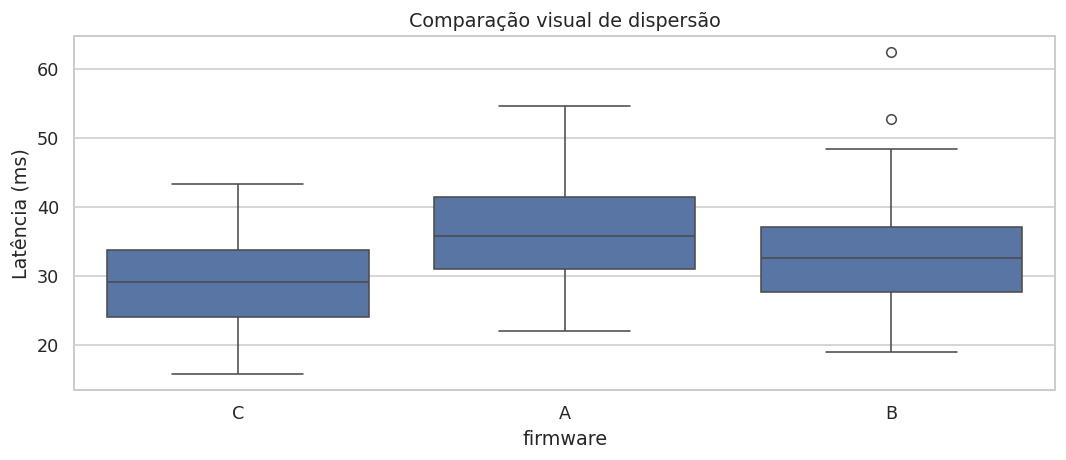

In [23]:
grupos_latencia={nome:g['latencia_ms'].to_numpy() for nome,g in dados.groupby('firmware')}
resultado_teste('Levene centrado na mediana',stats.levene(*grupos_latencia.values(),center='median'))
fig,ax=plt.subplots();sns.boxplot(data=dados,x='firmware',y='latencia_ms',ax=ax)
ax.set(title='Comparação visual de dispersão',ylabel='Latência (ms)');plt.show()

**Interpretação do exemplo e decisão seguinte**

A estatística global investiga variâncias, não médias. Se a dispersão for operacionalmente importante, descrevê-la em unidades e investigar sua origem. Um firmware pode ser rápido em média e instável na cauda.

## 25. Teste t de uma amostra contra uma referência

**Pergunta:** a média da população difere de um valor de referência? O teste t de uma amostra compara uma média amostral com um valor definido. Ele pressupõe unidades independentes e uma distribuição da média adequada, sendo exato sob normalidade dos valores.

O exemplo compara uma amostra didática de consumo com 10 W, usando alternativa bilateral. A referência precisa vir de especificação ou hipótese, não ser escolhida depois de observar a média. Se a pergunta for “consumo abaixo do limite”, uma alternativa unilateral pode fazer sentido, desde que definida antecipadamente.

**O que se busca descobrir:** evidência de desvio da média, acompanhada da magnitude. **Limite:** teste de média não demonstra que todos os dispositivos respeitam um limite. Para requisitos individuais, analisar quantis, proporções de violação ou intervalos de tolerância apropriados.

In [24]:
rref=np.random.default_rng(91)
consumo_referencia=rref.normal(10.4,0.9,40)
res=stats.ttest_1samp(consumo_referencia,popmean=10)
resultado_teste('Teste t de uma amostra',res)
print('Média e IC:',np.round(ic_media(consumo_referencia),4),'W')
print('Diferença observada da referência:',round(consumo_referencia.mean()-10,4),'W')

Teste t de uma amostra | estatística = 7.0165 | p = 2.0344e-08
Há evidência contra a hipótese nula no nível definido.
Média e IC: [10.7127 10.5072 10.9181] W
Diferença observada da referência: 0.7127 W


**Interpretação do exemplo e decisão seguinte**

Mesmo se a média não diferir de 10 W, alguns dispositivos podem consumir mais. Um limite de segurança ou capacidade individual exige outra pergunta e outro tipo de avaliação.

## 26. Welch para comparar médias de dois grupos independentes

**Pergunta:** qual é a diferença média de latência entre A e B? Welch compara duas médias sem pressupor variâncias iguais, ajustando os graus de liberdade. Requer grupos independentes e uma aproximação adequada para a distribuição das médias; extremos severos e amostras pequenas precisam de atenção.

A diferença será definida como A − B. Sinal positivo significa A mais lento. O erro padrão é $\sqrt{s_A^2/n_A+s_B^2/n_B}$. O IC de Welch informa a faixa compatível com a diferença sob o procedimento. O teste t clássico com variância combinada é uma opção quando variância comum é justificável, mas não será a escolha padrão aqui.

**O que se busca descobrir:** magnitude, direção e incerteza da diferença média. **Quando usar:** equipamentos distintos alocados a duas condições. **Erro a evitar:** aplicar este teste a duas medições das mesmas placas, ignorando pareamento. O resultado também não se refere automaticamente à diferença de mediana ou de p99.

In [25]:
a=grupos_latencia['A'];b=grupos_latencia['B']
res_welch=stats.ttest_ind(a,b,equal_var=False)
resultado_teste('Welch A versus B',res_welch)
var_a,var_b=np.var(a,ddof=1),np.var(b,ddof=1)
ep=np.sqrt(var_a/len(a)+var_b/len(b))
gl=(var_a/len(a)+var_b/len(b))**2/((var_a/len(a))**2/(len(a)-1)+(var_b/len(b))**2/(len(b)-1))
dif=a.mean()-b.mean();margem=stats.t.ppf(0.975,gl)*ep
print('Diferença A−B:',round(dif,3),'ms | IC 95%:',np.round([dif-margem,dif+margem],3))
registrar('Diferença média A−B',estimativa=float(dif),ic_inf=float(dif-margem),ic_sup=float(dif+margem))

Welch A versus B | estatística = 4.0346 | p = 7.2786e-05
Há evidência contra a hipótese nula no nível definido.
Diferença A−B: 3.498 ms | IC 95%: [1.79  5.205]


**Interpretação do exemplo e decisão seguinte**

Comparar o intervalo com uma diferença mínima de importância prática. A atribuição de firmware foi aleatória na simulação, mas cargas ainda variam e a análise ajustada pode aumentar precisão. Em um estudo observacional real, independência não basta para concluir causalidade.

## 27. Tamanho de efeito: diferença absoluta e Hedges g

Um teste descreve evidência contra uma hipótese; um tamanho de efeito descreve magnitude. A diferença absoluta em milissegundos costuma ser a medida mais diretamente útil à engenharia. Uma diferença padronizada divide a diferença média por uma medida de dispersão, permitindo comparar escalas sob condições adequadas.

Cohen d com desvio combinado pressupõe que esse denominador seja uma referência interpretável. Hedges g aplica uma correção para o viés em pequenas amostras. Com variâncias muito diferentes, a padronização exige cuidado e pode ser preferível outra referência, como desvio do grupo controle, além da diferença original.

**O que se busca descobrir:** se a magnitude é importante e como se compara à variabilidade. **Erro a evitar:** classificar qualquer g como pequeno, médio ou grande usando cortes universais. Esses rótulos não substituem custos, requisitos e contexto. Uma diferença padronizada pequena pode importar em sistemas de alto volume.

In [26]:
s_combinado=np.sqrt(((len(a)-1)*var_a+(len(b)-1)*var_b)/(len(a)+len(b)-2))
d_cohen=(a.mean()-b.mean())/s_combinado
correcao_j=1-3/(4*(len(a)+len(b))-9)
g_hedges=correcao_j*d_cohen
print('Diferença absoluta A−B:',round(dif,3),'ms')
print('Cohen d:',round(d_cohen,4),'| Hedges g aproximado:',round(g_hedges,4))
print('Sempre interpretar a unidade original e a escolha do denominador.')

Diferença absoluta A−B: 3.498 ms
Cohen d: 0.5077 | Hedges g aproximado: 0.5061
Sempre interpretar a unidade original e a escolha do denominador.


**Interpretação do exemplo e decisão seguinte**

A fórmula de J é uma aproximação comum. O sinal depende da ordem dos grupos. A unidade original facilita decidir se a mudança justifica uma atualização de firmware; a medida padronizada facilita comparação entre estudos semelhantes.

## 28. Mann-Whitney para grupos independentes

Mann-Whitney utiliza a ordenação relativa das observações. A hipótese nula usual considera distribuições iguais para grupos independentes. O teste não é universalmente um teste de igualdade de medianas. Essa interpretação requer estruturas comparáveis, como distribuições com formas semelhantes e uma diferença de localização.

**Quando usar:** dados ordinais, comparação baseada em postos ou uma pergunta sobre tendência de valores de um grupo serem maiores. **O que se busca descobrir:** diferença distributiva capturada pela ordenação. Pressupõe independência e tratamento adequado de empates. Não é “sem pressupostos”.

A probabilidade de superioridade pode ser estimada por U/(nA nB), contando meio peso para empates. Ela representa a tendência de uma observação de A superar uma de B, conforme a orientação de U. Não informa a diferença em milissegundos. Descrever ambas as distribuições é necessário, especialmente se dispersões diferirem.

Mann-Whitney A versus B | estatística = 10349.0 | p = 4.8409e-05
Há evidência contra a hipótese nula no nível definido.
P estimada(A>B), com meio peso para empates: 0.6479
Medianas A e B: 35.752 32.563 ms


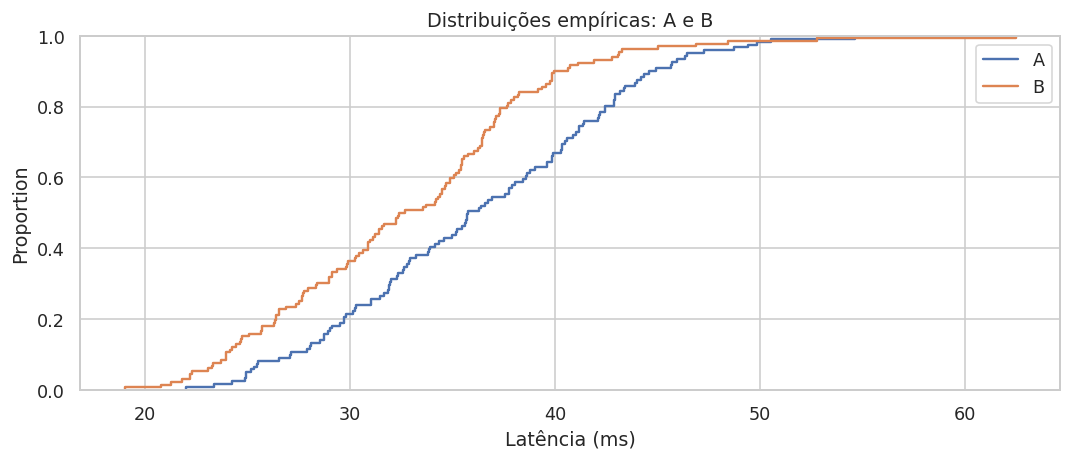

In [27]:
res_mw=stats.mannwhitneyu(a,b,alternative='two-sided',method='auto')
resultado_teste('Mann-Whitney A versus B',res_mw)
prob_superioridade=float(res_mw.statistic/(len(a)*len(b)))
print('P estimada(A>B), com meio peso para empates:',round(prob_superioridade,4))
print('Medianas A e B:',round(np.median(a),3),round(np.median(b),3),'ms')
fig,ax=plt.subplots();sns.ecdfplot(a,label='A',ax=ax);sns.ecdfplot(b,label='B',ax=ax)
ax.set(title='Distribuições empíricas: A e B',xlabel='Latência (ms)');ax.legend();plt.show()

**Interpretação do exemplo e decisão seguinte**

Uma diferença nas curvas pode refletir centro, dispersão ou caudas. Não traduzir automaticamente um p pequeno em “medianas diferentes”. Declarar a hipótese e a medida de efeito que o procedimento realmente investiga.

## 29. Teste de permutação e hipótese de intercambiabilidade

Permutação reorganiza rótulos para construir uma distribuição da estatística sob uma hipótese nula adequada. Em um experimento aleatorizado, permutar conforme a atribuição do tratamento pode reproduzir a referência da randomização. Em grupos independentes, a permutação simples exige intercambiabilidade sob a hipótese nula.

O exemplo gera dois grupos com a mesma forma e variância, variando um deslocamento. Usa diferença média como estatística e 5 mil reordenações. A aproximação tem variabilidade Monte Carlo; fixar uma semente melhora reproduzibilidade, sem transformar a aproximação em exata.

**O que se busca descobrir:** se a diferença observada é extrema frente à referência da permutação. **Limite:** permutar rótulos livremente não resolve heterocedasticidade para testar apenas igualdade de médias, nem dependência, nem desenho pareado. Nessas situações, a estatística e o esquema de permutação precisam respeitar a estrutura.

Permutação: diferença média | estatística = 1.2809 | p = 0.22156
Não há evidência suficiente para rejeitar a hipótese nula no nível definido.


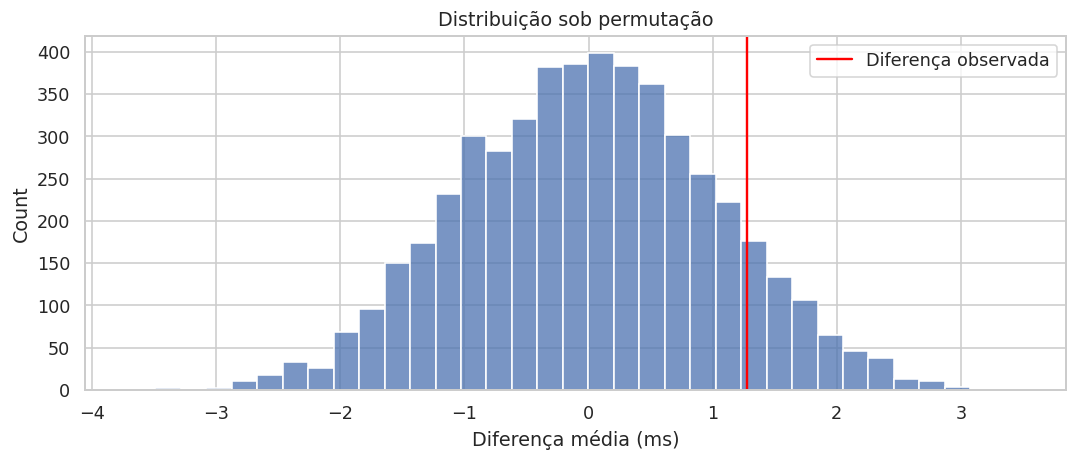

In [28]:
rperm=np.random.default_rng(77)
p1=rperm.normal(30,4,35);p2=rperm.normal(28,4,35)
def diferenca_media(u,v):return np.mean(u)-np.mean(v)
res_perm=stats.permutation_test((p1,p2),diferenca_media,permutation_type='independent',
                              vectorized=False,n_resamples=5000,alternative='two-sided',random_state=77)
resultado_teste('Permutação: diferença média',res_perm)
fig,ax=plt.subplots();sns.histplot(res_perm.null_distribution,bins=35,ax=ax)
ax.axvline(res_perm.statistic,color='red',label='Diferença observada')
ax.set(title='Distribuição sob permutação',xlabel='Diferença média (ms)');ax.legend();plt.show()

**Interpretação do exemplo e decisão seguinte**

A estatística continua sendo uma diferença de médias. A forma de obter o p-valor mudou. Não aplicar a mesma permutação livre às colunas A e B da base pareada, pois isso destruiria a correspondência entre placas.

## 30. Teste t pareado e gráfico das mudanças individuais

**Pergunta:** a atualização altera a latência nas mesmas placas? O teste t pareado trabalha com diferenças dentro de cada par. Cada placa serve como sua própria referência, reduzindo o efeito de diferenças persistentes entre equipamentos. O pressuposto de normalidade para o resultado exato diz respeito às diferenças, não a cada coluna isoladamente.

**Quando usar:** antes/depois ou duas condições no mesmo equipamento, preservando correspondência. **O que se busca descobrir:** mudança média individual e sua incerteza. **Limite:** ordem de execução, aquecimento, desgaste e aprendizado podem se confundir com o efeito da atualização. Randomizar a ordem ou controlar o protocolo ajuda a separar esses mecanismos.

A diferença será A − B; positiva significa que B reduziu o tempo. Aplicar um teste independente a esses dados descartaria o pareamento. Um IC da diferença média é mais informativo do que apresentar somente p.

Teste t pareado A−B | estatística = 6.6554 | p = 2.7262e-08
Há evidência contra a hipótese nula no nível definido.
Diferença média e IC 95%: [2.828 1.973 3.683] ms


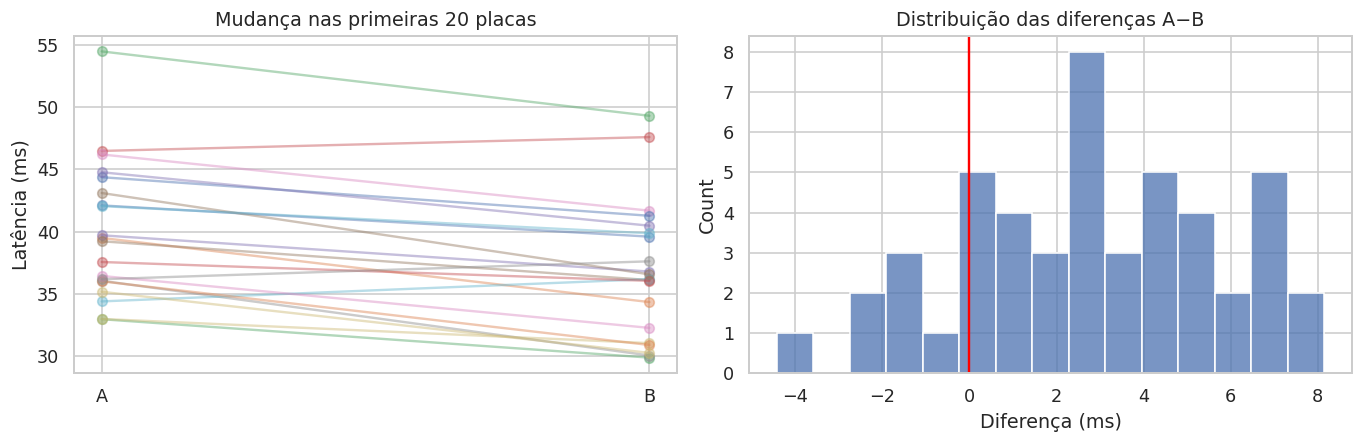

In [29]:
diferencas=pareados['A']-pareados['B']
res_par=stats.ttest_rel(pareados['A'],pareados['B'])
resultado_teste('Teste t pareado A−B',res_par)
print('Diferença média e IC 95%:',np.round(ic_media(diferencas),3),'ms')
fig,axs=plt.subplots(1,2,figsize=(12,4))
for _,linha in pareados.iloc[:20].iterrows():axs[0].plot(['A','B'],[linha['A'],linha['B']],alpha=0.45,marker='o')
axs[0].set(title='Mudança nas primeiras 20 placas',ylabel='Latência (ms)')
sns.histplot(diferencas,bins=15,ax=axs[1]);axs[1].axvline(0,color='red')
axs[1].set(title='Distribuição das diferenças A−B',xlabel='Diferença (ms)')
plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

O gráfico mostra que o efeito não precisa ser igual em todas as placas. A média das diferenças descreve uma tendência, enquanto a distribuição das diferenças mostra heterogeneidade da resposta.

## 31. Wilcoxon pareado e teste dos sinais

Wilcoxon de postos sinalizados utiliza sinais e magnitudes ordenadas das diferenças pareadas. Sua interpretação usual de deslocamento exige simetria da distribuição das diferenças. Zeros e empates precisam de tratamento compatível com a implementação. Ele não é um substituto sem pressupostos para qualquer situação em que Shapiro rejeitou.

O teste dos sinais utiliza apenas quantas diferenças são positivas ou negativas, descartando zeros. Sob uma hipótese de probabilidade igual de cada sinal e unidades independentes, usa uma distribuição binomial. Ele faz menos exigências sobre magnitudes, mas perde informação e pode ter menor poder. Com distribuições contínuas, pode investigar uma mediana de diferença igual a zero sob condições adequadas.

**O que se busca descobrir:** mudança pareada por postos ou direção, conforme o método. **Quando usar:** dados ordinais, diferenças com estrutura incompatível com a inferência de média ou uma pergunta explícita sobre direção. **Erro a evitar:** interpretar todos esses testes como se investigassem exatamente a mesma média.

In [30]:
res_wil=stats.wilcoxon(diferencas,alternative='two-sided',zero_method='wilcox')
resultado_teste('Wilcoxon pareado',res_wil)
nao_zero=diferencas[diferencas!=0]
positivas=int((nao_zero>0).sum())
res_sinais=stats.binomtest(positivas,n=len(nao_zero),p=0.5,alternative='two-sided')
resultado_teste('Teste dos sinais',res_sinais)
print('Diferenças positivas:',positivas,'de',len(nao_zero),'pares não nulos.')
print('Mediana da diferença:',round(diferencas.median(),3),'ms')

Wilcoxon pareado | estatística = 108.0 | p = 6.9076e-08
Há evidência contra a hipótese nula no nível definido.
Teste dos sinais | estatística = 0.8333 | p = 3.3053e-06
Há evidência contra a hipótese nula no nível definido.
Diferenças positivas: 40 de 48 pares não nulos.
Mediana da diferença: 2.973 ms


**Interpretação do exemplo e decisão seguinte**

As conclusões podem concordar neste exemplo, mas os parâmetros e pressupostos diferem. Ao escrever o resultado, nomear a medida: mudança média, deslocamento por postos ou predominância de um sinal.

## 32. ANOVA clássica para três ou mais grupos

ANOVA de um fator testa a hipótese de que todas as médias populacionais são iguais. Compara variabilidade entre grupos com variabilidade dentro dos grupos. A análise clássica pressupõe unidades independentes, erros aproximadamente normais dentro das condições para a inferência exata e variância comum.

O exemplo independente usa latências simuladas de três algoritmos com dispersão semelhante. O teste global não identifica quais pares diferem. Se houver evidência global e contrastes relevantes, uma análise planejada ou pós-teste adequado pode investigar diferenças específicas.

**O que se busca descobrir:** se o conjunto de médias é compatível com uma igualdade global. **Quando usar:** três ou mais condições independentes quando o modelo clássico é adequado. **Erro a evitar:** executar testes t para todos os pares sem controle de multiplicidade. Uma diferença global também não informa automaticamente relevância prática ou homogeneidade dentro dos grupos.

ANOVA clássica: algoritmos | estatística = 34.0903 | p = 1.1588e-12
Há evidência contra a hipótese nula no nível definido.
Eta quadrado descritivo: 0.3406


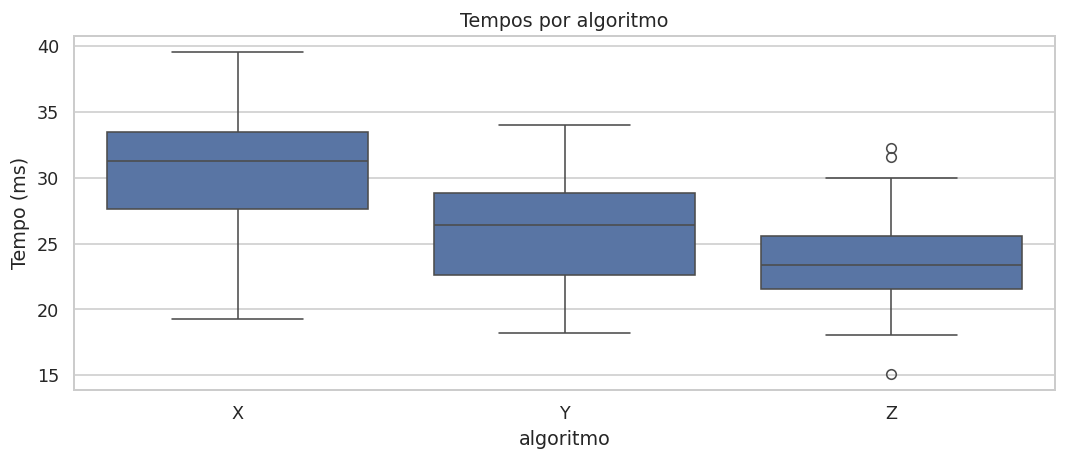

In [31]:
ranova=np.random.default_rng(102)
algoritmos=pd.DataFrame({'algoritmo':np.repeat(['X','Y','Z'],45),
 'tempo_ms':np.concatenate([ranova.normal(mu,4,45) for mu in [30,27,24]])})
amostras_alg=[g['tempo_ms'].to_numpy() for _,g in algoritmos.groupby('algoritmo')]
res_anova=stats.f_oneway(*amostras_alg)
resultado_teste('ANOVA clássica: algoritmos',res_anova)
media_global=algoritmos['tempo_ms'].mean()
sq_entre=sum(len(v)*(v.mean()-media_global)**2 for v in amostras_alg)
sq_total=((algoritmos['tempo_ms']-media_global)**2).sum()
print('Eta quadrado descritivo:',round(float(sq_entre/sq_total),4))
fig,ax=plt.subplots();sns.boxplot(data=algoritmos,x='algoritmo',y='tempo_ms',ax=ax)
ax.set(title='Tempos por algoritmo',ylabel='Tempo (ms)');plt.show()

**Interpretação do exemplo e decisão seguinte**

Eta quadrado resume a fração de variabilidade amostral associada ao agrupamento no modelo. É uma medida descritiva e pode ter viés. Não identifica os pares nem demonstra que o fator explique causalmente essa fração em outro estudo.

## 33. ANOVA de Welch quando variâncias não são comuns

Welch ANOVA compara médias de três ou mais grupos independentes sem assumir igualdade de variâncias. Ajusta ponderações e graus de liberdade. É uma alternativa útil quando dispersões ou tamanhos diferem, desde que a distribuição das estimativas seja adequadamente comportada.

O exemplo aplica o método aos firmwares da base principal. Não é necessário rejeitar Levene antes de utilizá-lo: pode ser definido como procedimento principal. A análise continua focada em médias, não em medianas.

**O que se busca descobrir:** evidência global sobre médias sob heterocedasticidade. **Limite:** Welch não resolve dependência nem todo problema causado por extremos. O teste global não aponta quais grupos diferem. Para comparações posteriores, utilizar contrastes compatíveis, como pares Welch com correção de Holm, ou Games-Howell em uma implementação apropriada.

A escolha do procedimento pós-teste deve acompanhar a inferência global e o desenho. Não utilizar Tukey com variância comum automaticamente após uma ANOVA de Welch.

In [32]:
res_wanova=anova_oneway(list(grupos_latencia.values()),use_var='unequal',welch_correction=True)
resultado_teste('ANOVA de Welch: firmware',res_wanova)
print('Graus de liberdade:',res_wanova.df)
display(dados.groupby('firmware')['latencia_ms'].agg(['count','mean','std']))

ANOVA de Welch: firmware | estatística = 30.6229 | p = 1.5178e-12
Há evidência contra a hipótese nula no nível definido.
Graus de liberdade: (2.0, np.float64(235.02249392984697))


,count,mean,std
firmware,,,
A,121,36.256943,6.870114
B,132,32.759393,6.907229
C,107,29.248217,6.622318


**Interpretação do exemplo e decisão seguinte**

Um resultado global pode coexistir com pares sem evidência suficiente após correção. A comparação por pares deve ser declarada e acompanhada por diferenças em milissegundos.

## 34. Pós-testes e controle de comparações múltiplas

Ao executar vários testes, cresce a chance de um falso positivo na família. Holm controla a probabilidade de ao menos um falso positivo na família sob condições amplas e costuma ser menos conservador que Bonferroni. Benjamini-Hochberg controla a taxa esperada de falsas descobertas sob condições de dependência apropriadas, sendo útil em exploração de muitos sinais.

Tukey HSD foi elaborado para comparações de todos os pares dentro de um modelo com variância comum. Será aplicado à base de algoritmos, coerente com a ANOVA clássica. Para os firmwares, serão feitos testes Welch por pares e correção de Holm. Os ICs simples não ajustados não devem ser apresentados como intervalos simultâneos controlados por Holm.

**O que se busca descobrir:** quais comparações sustentam evidência após considerar a busca múltipla. **Erro a evitar:** usar a correção somente nos testes que inicialmente deram p pequeno. A família precisa incluir todas as comparações pertinentes e ser definida pelo objetivo.

In [33]:
print('Tukey na base com desenho clássico:')
print(pairwise_tukeyhsd(algoritmos['tempo_ms'],algoritmos['algoritmo'],alpha=0.05))
pares=[]
for g1,g2 in combinations(grupos_latencia,2):
    v1,v2=grupos_latencia[g1],grupos_latencia[g2]
    r=stats.ttest_ind(v1,v2,equal_var=False)
    pares.append({'par':f'{g1}−{g2}','dif_media_ms':v1.mean()-v2.mean(),'p_bruto':r.pvalue})
pares=pd.DataFrame(pares)
rejeita,p_corr,_,_=multipletests(pares['p_bruto'],alpha=0.05,method='holm')
pares['p_holm']=p_corr;pares['rejeita_5pct']=rejeita
display(pares.round(5))
# Demonstração independente da distinção entre controle de família e FDR.
p_demo=np.array([0.001,0.012,0.030,0.045,0.12,0.4])
display(pd.DataFrame({'p_bruto':p_demo,'p_holm':multipletests(p_demo,method='holm')[1],
                     'p_bh':multipletests(p_demo,method='fdr_bh')[1]}))

Tukey na base com desenho clássico:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     X      Y   -4.594    0.0 -6.6745 -2.5135   True
     X      Z  -7.1511    0.0 -9.2316 -5.0706   True
     Y      Z  -2.5571 0.0116 -4.6376 -0.4766   True
----------------------------------------------------


,par,dif_media_ms,p_bruto,p_holm,rejeita_5pct
0,A−B,3.49755,0.00007,0.00015,True
1,A−C,7.00873,0.00000,0.00000,True
2,B−C,3.51118,0.00009,0.00015,True


,p_bruto,p_holm,p_bh
0,0.001,0.006,0.0060
1,0.012,0.060,0.0360
2,0.030,0.120,0.0600
3,0.045,0.135,0.0675
4,0.120,0.240,0.1440
5,0.400,0.400,0.4000


**Interpretação do exemplo e decisão seguinte**

Não comparar valores corrigidos sem registrar a família e o método. BH não fornece a probabilidade de um resultado individual ser falso. A escolha entre controle da família e FDR depende do custo e da natureza da investigação.

## 35. Kruskal-Wallis para grupos independentes por postos

Kruskal-Wallis generaliza a comparação por postos para três ou mais grupos independentes. A hipótese nula é formulada em termos de distribuições iguais. Interpretar como comparação de medianas exige condições de forma e dispersão que tornem uma mudança de localização uma explicação adequada.

**Quando usar:** respostas ordinais ou comparação distributiva por postos entre grupos independentes. **O que se busca descobrir:** se pelo menos um grupo apresenta uma distribuição de postos incompatível com a referência global. **Pressupostos:** independência, escala ordenável e condições da aproximação da distribuição da estatística. Empates exigem correção.

O exemplo usa os mesmos firmwares, mas responde a uma pergunta distinta da ANOVA de médias. A concordância entre métodos pode fortalecer uma leitura descritiva, porém executar vários métodos e selecionar o mais favorável não constitui um plano inferencial válido. Para pós-testes, Dunn é uma opção; comparações Mann-Whitney por pares com Holm são outra família claramente definida, mas não devem ser chamadas de Dunn.

In [34]:
res_kw=stats.kruskal(*grupos_latencia.values())
resultado_teste('Kruskal-Wallis: firmware',res_kw)
pares_postos=[]
for g1,g2 in combinations(grupos_latencia,2):
    r=stats.mannwhitneyu(grupos_latencia[g1],grupos_latencia[g2],alternative='two-sided')
    pares_postos.append({'par':f'{g1}−{g2}','p_bruto':r.pvalue})
pares_postos=pd.DataFrame(pares_postos)
pares_postos['p_holm']=multipletests(pares_postos['p_bruto'],method='holm')[1]
display(pares_postos)
print('Comparações exploratórias por pares: Mann-Whitney com Holm, não teste de Dunn.')

Kruskal-Wallis: firmware | estatística = 48.7562 | p = 2.5866e-11
Há evidência contra a hipótese nula no nível definido.
Comparações exploratórias por pares: Mann-Whitney com Holm, não teste de Dunn.


,par,p_bruto,p_holm
0,A−B,4.840892e-05,9.681785e-05
1,A−C,1.849266e-11,5.547798e-11
2,B−C,3.225236e-04,3.225236e-04


**Interpretação do exemplo e decisão seguinte**

Separar a interpretação da localização da interpretação das distribuições. Gráficos ECDF e boxplots ajudam a identificar o que pode estar mudando. Um resultado global não mede quanto tempo foi economizado.

## 36. Três condições nas mesmas placas: ANOVA repetida e Friedman

Quando as mesmas placas são avaliadas em três condições, as medições não são independentes entre condições. ANOVA de medidas repetidas modela diferenças dentro da unidade. Com mais de duas condições, sua inferência clássica envolve esfericidade, relacionada à variância das diferenças entre pares de condições.

A função `AnovaRM` será demonstrada em um desenho balanceado. Sua implementação não fornece todas as correções de esfericidade necessárias em estudos reais. Antes de usar um resultado confirmatório, examinar esse pressuposto e utilizar correções ou um modelo apropriado quando necessário.

Friedman utiliza postos dentro de cada placa e oferece uma análise de blocos para respostas ordenáveis. Também não é sem pressupostos: as placas precisam ser independentes e o pareamento completo deve ser respeitado. Sua hipótese e interpretação não são idênticas às da ANOVA.

**O que se busca descobrir:** diferença entre condições considerando a placa. **Erro a evitar:** aplicar ANOVA independente às 144 linhas como se pertencessem a 144 equipamentos.

In [35]:
ajuste_repetido=AnovaRM(longa,depvar='latencia_ms',subject='placa',within=['firmware']).fit()
print(ajuste_repetido)
res_friedman=stats.friedmanchisquare(pareados['A'],pareados['B'],pareados['C'])
resultado_teste('Friedman: três condições pareadas',res_friedman)
print('Diferenças médias:')
display(pd.Series({'A−B':(pareados['A']-pareados['B']).mean(),
                  'A−C':(pareados['A']-pareados['C']).mean(),
                  'B−C':(pareados['B']-pareados['C']).mean()},name='ms'))

                Anova
         F Value Num DF  Den DF Pr > F
--------------------------------------
firmware 68.9500 2.0000 94.0000 0.0000

Friedman: três condições pareadas | estatística = 55.5417 | p = 8.6952e-13
Há evidência contra a hipótese nula no nível definido.
Diferenças médias:


A−B    2.827845
A−C    5.173338
B−C    2.345493
Name: ms, dtype: float64

**Interpretação do exemplo e decisão seguinte**

A simulação usa erros independentes de dispersão semelhante por condição, mas dados reais podem não seguir essa estrutura. Pós-testes pareados também precisam de controle de multiplicidade. Modelos mistos serão apresentados para estruturas mais flexíveis.

## 37. Comparar duas proporções independentes

**Pergunta:** a frequência de violação de SLA difere entre A e B? Um teste z de duas proporções compara uma diferença de probabilidades sob uma aproximação normal. Requer oportunidades independentes e contagens adequadas de eventos e não eventos. Com contagens pequenas, uma alternativa exata ou outra aproximação pode ser necessária.

**O que se busca descobrir:** se o evento é mais frequente, acompanhado da diferença em pontos percentuais. Um aumento de 10% para 15% é de 5 pontos percentuais e de 50% relativo; são medidas diferentes. Sempre identificar qual está sendo utilizada.

O exemplo usa dispositivos distintos. Se fossem os mesmos equipamentos antes e depois, seria necessário considerar a correspondência, como no teste de McNemar. O denominador e a definição do evento precisam permanecer comparáveis.

In [36]:
ga=dados.loc[dados['firmware']=='A','violacao_sla'];gb=dados.loc[dados['firmware']=='B','violacao_sla']
contagens=np.array([ga.sum(),gb.sum()]);totais=np.array([len(ga),len(gb)])
z,p=proportions_ztest(contagens,totais,alternative='two-sided')
print('Eventos:',contagens,'| Totais:',totais)
print('Diferença A−B:',round(100*(ga.mean()-gb.mean()),3),'pontos percentuais')
print('z:',round(z,4),'| p:',f'{p:.5g}');print(decisao_p(p))
registrar('Teste z de proporções A−B',estatistica=float(z),p=float(p))

Eventos: [18  9] | Totais: [121 132]
Diferença A−B: 8.058 pontos percentuais
z: 2.0736 | p: 0.038117
Há evidência contra a hipótese nula no nível definido.


**Interpretação do exemplo e decisão seguinte**

Uma diferença de taxas pode estar associada à composição da carga. Mesmo em um experimento, o tamanho amostral pode ser insuficiente para eventos raros. Complementar com ICs, contagens e um modelo ajustado quando houver justificativa.

## 38. Qui-quadrado de independência e V de Cramér

**Pergunta:** categoria de carga e violação de SLA estão associadas? O teste qui-quadrado compara contagens observadas com contagens esperadas sob independência. A tabela é de contingência, não uma tabela de médias. As unidades precisam ser independentes e as frequências esperadas devem sustentar a aproximação utilizada.

V de Cramér resume intensidade de associação entre categorias, variando de zero a um na formulação usual. Não informa direção como uma correlação entre números. Resíduos padronizados simples mostram células com contagens acima ou abaixo da referência; são exploratórios e não constituem uma família de testes corrigida.

**O que se busca descobrir:** associação e quais combinações contribuem à diferença. **Limite:** associação não demonstra causalidade. Quando as esperadas são pequenas, considerar Fisher em 2×2 ou métodos exatos/Monte Carlo apropriados para tabelas maiores. Não definir regras universais ignorando dimensões e desenho.

Menor esperada: 11.958 | χ²: 24.7434 | gl: 2 | p: 4.2369e-06
V de Cramér: 0.2622
Há evidência contra a hipótese nula no nível definido.


violacao_sla,0,1
carga,,
baixa,103,2
média,128,13
alta,88,26


violacao_sla,0,1
carga,,
baixa,93.041667,11.958333
média,124.941667,16.058333
alta,101.016667,12.983333


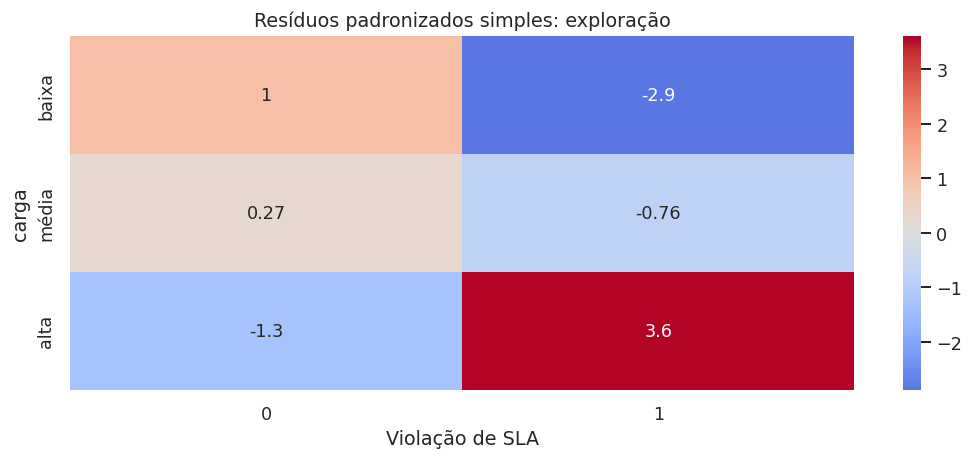

In [37]:
contingencia=pd.crosstab(dados['carga'],dados['violacao_sla'])
chi2,p_chi,gl_chi,esperadas=stats.chi2_contingency(contingencia,correction=False)
v_cramer=np.sqrt(chi2/(contingencia.to_numpy().sum()*min(contingencia.shape[0]-1,contingencia.shape[1]-1)))
display(contingencia)
display(pd.DataFrame(esperadas,index=contingencia.index,columns=contingencia.columns))
print('Menor esperada:',round(esperadas.min(),3),'| χ²:',round(chi2,4),'| gl:',gl_chi,'| p:',f'{p_chi:.5g}')
print('V de Cramér:',round(v_cramer,4));print(decisao_p(p_chi))
residuos=(contingencia-esperadas)/np.sqrt(esperadas)
fig,ax=plt.subplots();sns.heatmap(residuos,annot=True,center=0,cmap='coolwarm',ax=ax)
ax.set(title='Resíduos padronizados simples: exploração',xlabel='Violação de SLA');plt.show()
registrar('Qui-quadrado carga×SLA',estatistica=float(chi2),p=float(p_chi),v_cramer=float(v_cramer))

**Interpretação do exemplo e decisão seguinte**

Células positivas têm mais eventos do que o esperado sob independência; negativas têm menos. Essa visualização orienta perguntas e não fornece automaticamente significância individual de cada célula.

## 39. Fisher, risco relativo e odds ratio

Fisher fornece um teste exato condicional para uma tabela 2×2 sob seu modelo de referência, sendo útil com contagens pequenas. O p-valor não mede magnitude. Para magnitude, risco relativo compara probabilidades; odds ratio compara chances, sendo chance p/(1−p).

No exemplo independente, linhas representam firmware antigo e novo; colunas representam falha e sucesso. Risco relativo acima de um significa maior risco na primeira linha. Odds ratio acima de um significa maior chance na primeira linha. Quando eventos não são raros, odds ratio pode divergir bastante do risco relativo e não deve ser chamado de razão de probabilidades.

**O que se busca descobrir:** direção e intensidade de associação binária com incerteza. **Quando usar:** evento com duas categorias de condição. **Cuidado:** a orientação da tabela muda o sinal ou o inverso da medida. Células nulas exigem procedimentos e interpretação específicos; não adicionar valores arbitrariamente sem declarar a regra.

In [38]:
tabela_risco=np.array([[8,32],[2,38]])
res_fisher=stats.fisher_exact(tabela_risco,alternative='two-sided')
print('Linhas: antigo/novo | colunas: falha/sucesso')
print('Fisher: odds ratio amostral =',round(res_fisher.statistic,4),'| p =',f'{res_fisher.pvalue:.5g}')
medidas_risco=Table2x2(tabela_risco,shift_zeros=False)
print('Risco relativo:',round(medidas_risco.riskratio,4),'| IC aproximado:',np.round(medidas_risco.riskratio_confint(),4))
print('Odds ratio:',round(medidas_risco.oddsratio,4),'| IC aproximado:',np.round(medidas_risco.oddsratio_confint(),4))
print('Os ICs exibidos não são intervalos exatos do teste de Fisher.')

Linhas: antigo/novo | colunas: falha/sucesso
Fisher: odds ratio amostral = 4.75 | p = 0.08718
Risco relativo: 4.0 | IC aproximado: [ 0.9049 17.6814]
Odds ratio: 4.75 | IC aproximado: [ 0.9407 23.9848]
Os ICs exibidos não são intervalos exatos do teste de Fisher.


**Interpretação do exemplo e decisão seguinte**

As medidas e seus intervalos complementam o p-valor. Risco e chance são conceitos distintos. A interpretação causal exigiria conhecer atribuição do firmware, comparabilidade das tentativas e demais aspectos do desenho.

## 40. McNemar para eventos binários pareados

**Pergunta:** a frequência de falha muda nas mesmas unidades após uma atualização? McNemar utiliza as discordâncias: unidades que falhavam e passaram a não falhar, e unidades que não falhavam e passaram a falhar. Concordâncias não informam diretamente a diferença entre probabilidades marginais.

**Quando usar:** dois resultados binários das mesmas placas ou tentativas pareadas adequadamente. **O que se busca descobrir:** mudança de proporção respeitando o vínculo entre observações. O exemplo utiliza uma tabela de transições, com linhas “antes” e colunas “depois”.

Com poucas discordâncias, a versão exata usa uma referência binomial. O método não é intercambiável com o teste de duas proporções independentes. Também não controla automaticamente mudanças de protocolo, ordem ou fatores simultâneos.

In [39]:
transicoes=np.array([[30,3],[12,5]])
# Índice 0: sem falha; índice 1: com falha.
res_mc=mcnemar(transicoes,exact=True)
display(pd.DataFrame(transicoes,index=['antes_sem','antes_com'],columns=['depois_sem','depois_com']))
print('Melhoraram:',transicoes[1,0],'| Pioraram:',transicoes[0,1])
print('McNemar exato | estatística:',res_mc.statistic,'| p:',f'{res_mc.pvalue:.5g}')
print(decisao_p(res_mc.pvalue))
print('Falha antes:',transicoes[1,:].sum()/transicoes.sum(),
      '| Falha depois:',transicoes[:,1].sum()/transicoes.sum())

Melhoraram: 12 | Pioraram: 3
McNemar exato | estatística: 3.0 | p: 0.035156
Há evidência contra a hipótese nula no nível definido.
Falha antes: 0.34 | Falha depois: 0.16


,depois_sem,depois_com
antes_sem,30,3
antes_com,12,5


**Interpretação do exemplo e decisão seguinte**

Os 12 que melhoraram e os três que pioraram são o foco da comparação. O total de pares, a tabela de transições e a diferença de proporções devem acompanhar o resultado.

## 41. Comparar distribuições completas com Kolmogorov-Smirnov

O teste de duas amostras de Kolmogorov-Smirnov utiliza a maior distância entre duas ECDFs. Investiga igualdade de distribuições, podendo detectar mudanças de centro, dispersão ou forma. Não é um teste de médias nem um teste específico de medianas.

**Quando usar:** comparar distribuições contínuas independentes, como latências de duas rotas. **O que se busca descobrir:** diferença global na distribuição. A versão clássica pressupõe distribuição contínua; dados discretos e muitos empates exigem cautela e possíveis métodos alternativos.

O teste de uma amostra contra uma distribuição teórica é outro procedimento. Se parâmetros da distribuição foram estimados na mesma amostra, a referência padrão pode não ser válida sem adaptação. Não usar automaticamente `kstest` contra normal com média e desvio estimados como substituto de um teste apropriado de normalidade.

KS de duas amostras: rotas | estatística = 0.1923 | p = 0.01615
Há evidência contra a hipótese nula no nível definido.


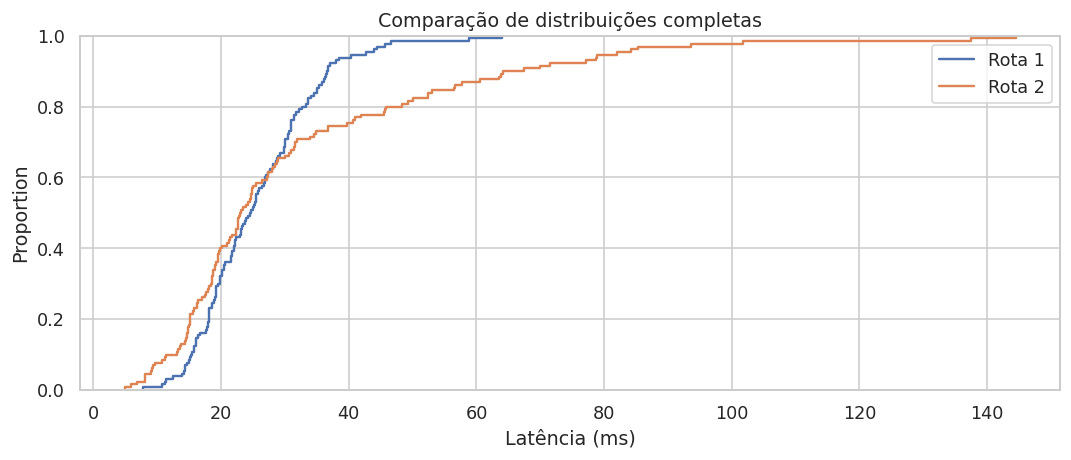

In [40]:
rks=np.random.default_rng(84)
rota1=rks.lognormal(3.2,0.35,130);rota2=rks.lognormal(3.2,0.70,130)
res_ks=stats.ks_2samp(rota1,rota2,alternative='two-sided',method='auto')
resultado_teste('KS de duas amostras: rotas',res_ks)
fig,ax=plt.subplots();sns.ecdfplot(rota1,label='Rota 1',ax=ax);sns.ecdfplot(rota2,label='Rota 2',ax=ax)
ax.set(title='Comparação de distribuições completas',xlabel='Latência (ms)');ax.legend();plt.show()

**Interpretação do exemplo e decisão seguinte**

Uma mudança na dispersão pode produzir evidência mesmo sem uma pergunta sobre média. Reportar a distância D e examinar em que região as curvas diferem. Distância de Wasserstein pode complementar a leitura na unidade original.

## 42. Pearson, covariância e associação linear

Covariância mede variação conjunta e depende das unidades. Correlação de Pearson padroniza a covariância e varia entre −1 e 1, medindo associação linear. Seu sinal indica direção; sua magnitude não descreve qualquer relação não linear possível.

**Quando usar:** quantificar uma relação aproximadamente linear entre duas variáveis quantitativas. **O que se busca descobrir:** se consumo cresce de modo linear com CPU e quão consistente é essa associação. A estimativa r pode ser calculada sem normalidade. A inferência clássica do teste de correlação requer condições adicionais, incluindo independência e um modelo adequado, frequentemente normalidade bivariada para o teste exato.

Uma correlação não identifica causalidade, pode ser influenciada por extremos e pode refletir mistura de grupos ou variáveis omitidas. $r^2$ corresponde à fração de variabilidade explicada numa regressão linear simples com intercepto, mas não é uma porcentagem causal geral. Sempre olhar o gráfico antes de interpretar o coeficiente.

Pearson CPU×consumo | estatística = 0.9665 | p = 1.9221e-213
Há evidência contra a hipótese nula no nível definido.
Covariância: 50.85163755701813


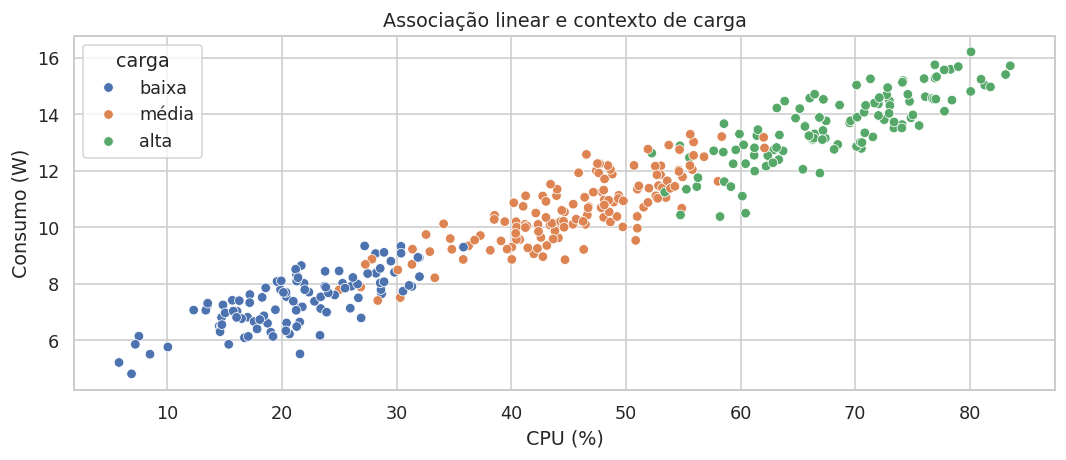

In [41]:
res_pearson=stats.pearsonr(dados['cpu_pct'],dados['consumo_w'])
resultado_teste('Pearson CPU×consumo',res_pearson)
print('Covariância:',dados[['cpu_pct','consumo_w']].cov().iloc[0,1])
fig,ax=plt.subplots();sns.scatterplot(data=dados,x='cpu_pct',y='consumo_w',hue='carga',ax=ax)
ax.set(title='Associação linear e contexto de carga',xlabel='CPU (%)',ylabel='Consumo (W)');plt.show()

**Interpretação do exemplo e decisão seguinte**

A associação foi incorporada à simulação. Em um estudo real, temperatura, arquitetura e carga poderiam alterar a relação. O coeficiente não informa sozinho quantos watts mudam por ponto percentual de CPU; isso será investigado com regressão.

## 43. Spearman e Kendall para relações monotônicas

Spearman aplica a ideia de correlação aos postos, captando associação monotônica: uma variável tende a aumentar quando a outra aumenta, sem exigir uma reta. Kendall utiliza concordâncias e discordâncias entre pares; tau-b considera empates.

**Quando usar:** escalas ordinais, relações monotônicas não lineares ou situações em que a comparação por ordenação faz sentido. **O que se busca descobrir:** consistência da direção na ordenação. **Pressupostos para inferência:** unidades independentes e referência estatística adequada; muitos empates, amostras pequenas e dependência exigem atenção.

Esses métodos não detectam toda relação não linear. Uma curva em U pode ter associação forte e correlações próximas de zero. Eles também não tornam outliers irrelevantes nem justificam causalidade. A escolha entre Pearson e postos deve acompanhar a pergunta, não uma regra automática baseada em Shapiro.

Pearson monotônico | estatística = 0.9305 | p = 2.0258e-66
Há evidência contra a hipótese nula no nível definido.
Spearman monotônico | estatística = 0.9911 | p = 2.163e-131
Há evidência contra a hipótese nula no nível definido.
Kendall monotônico | estatística = 0.9363 | p = 7.9165e-65
Há evidência contra a hipótese nula no nível definido.
Exemplo em U: Pearson = -0.0038 | Spearman = -0.0006


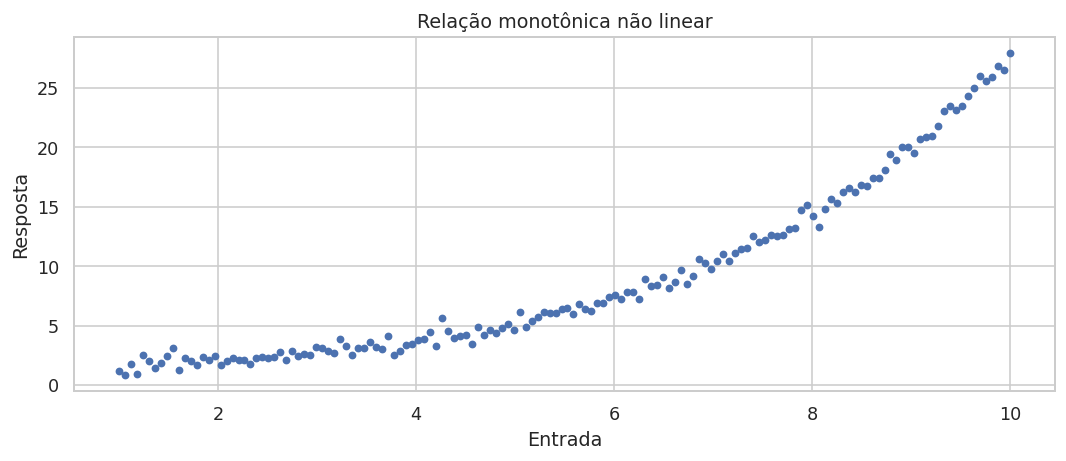

In [42]:
rmon=np.random.default_rng(18)
u=np.linspace(1,10,150);v=np.exp(u/3)+rmon.normal(0,0.5,len(u))
for nome,res in [('Pearson',stats.pearsonr(u,v)),('Spearman',stats.spearmanr(u,v)),('Kendall',stats.kendalltau(u,v))]:
    resultado_teste(nome+' monotônico',res)
fig,ax=plt.subplots();ax.scatter(u,v,s=15);ax.set(title='Relação monotônica não linear',xlabel='Entrada',ylabel='Resposta');plt.show()
u2=np.linspace(-3,3,150);v2=u2**2+rmon.normal(0,0.2,len(u2))
print('Exemplo em U: Pearson =',round(stats.pearsonr(u2,v2).statistic,4),
      '| Spearman =',round(stats.spearmanr(u2,v2).statistic,4))

**Interpretação do exemplo e decisão seguinte**

No caso em U, coeficientes baixos não representam ausência de relação. O gráfico revela a estrutura que o coeficiente escolhido não resume. Utilizar modelagem não linear ou informação mútua exploratória quando a pergunta justificar.

## 44. Matriz de correlações, redundância e associação condicionada

Uma matriz organiza correlações entre várias variáveis. Ela ajuda a detectar redundância antes de regressão ou PCA. Sua diagonal é um; o gráfico não transforma correlações em relações causais. A busca em muitos pares também exige distinguir exploração de inferência confirmatória.

Uma correlação parcial pode ser obtida removendo linearmente o efeito de uma variável de ambas as respostas e correlacionando os resíduos. O exemplo investiga temperatura e latência após ajuste linear por CPU. A correlação parcial depende do conjunto de ajuste e do modelo; não elimina confundimento não medido e não estabelece causalidade.

**O que se busca descobrir:** quais atributos compartilham informação e quais relações permanecem no modelo ajustado. **Erro a evitar:** retirar atributos apenas porque r ultrapassou um corte arbitrário. A decisão depende de interpretação, objetivo e estabilidade.

Associação bruta temperatura×latência: 0.738
Correlação parcial linear, controlando CPU: -0.1275


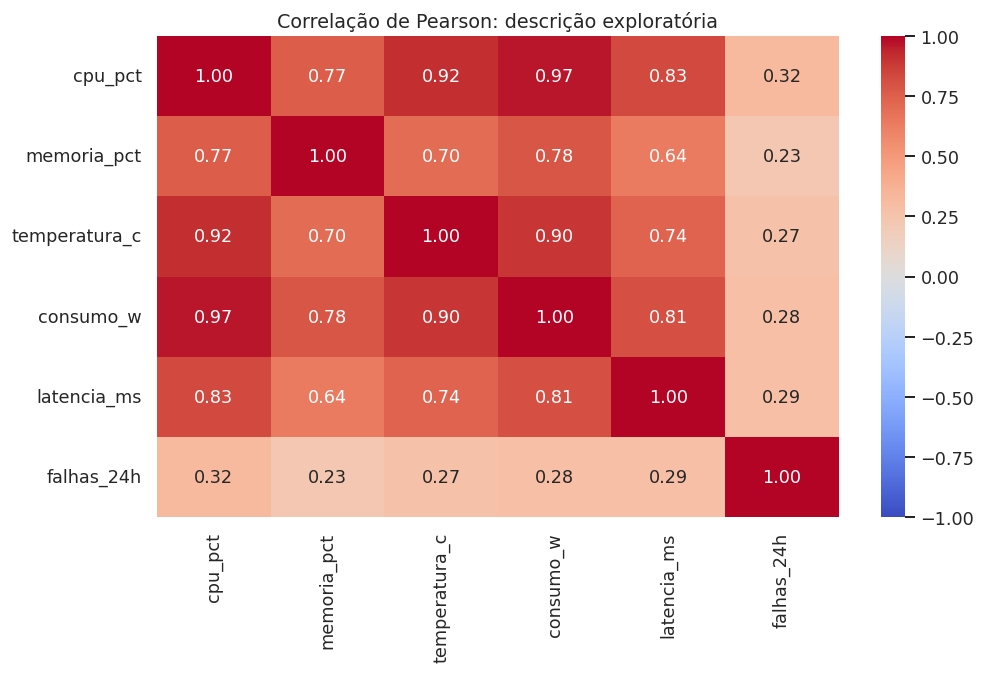

In [43]:
numericas=['cpu_pct','memoria_pct','temperatura_c','consumo_w','latencia_ms','falhas_24h']
fig,ax=plt.subplots(figsize=(9,6));sns.heatmap(dados[numericas].corr(),annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1,ax=ax)
ax.set_title('Correlação de Pearson: descrição exploratória');plt.tight_layout();plt.show()
controle=sm.add_constant(dados[['cpu_pct']])
res_temp=sm.OLS(dados['temperatura_c'],controle).fit().resid
res_lat=sm.OLS(dados['latencia_ms'],controle).fit().resid
print('Associação bruta temperatura×latência:',round(stats.pearsonr(dados['temperatura_c'],dados['latencia_ms']).statistic,4))
print('Correlação parcial linear, controlando CPU:',round(stats.pearsonr(res_temp,res_lat).statistic,4))

**Interpretação do exemplo e decisão seguinte**

A leitura parcial aqui é descritiva; o p-valor usual de Pearson aplicado aos resíduos não está sendo usado como teste formal de correlação parcial. Selecionar controles exige raciocínio de desenho e conhecimento do sistema.

## 45. Regressão linear simples: associação em unidades do problema

Regressão simples modela a média condicional: $E[Y|X]=\beta_0+\beta_1X$. O coeficiente angular informa a mudança média prevista em Y por unidade de X no modelo. O intercepto é a resposta prevista em X = 0, que pode estar fora da região observada e não ter significado físico útil.

**Pergunta:** quanto o consumo médio muda por ponto percentual de CPU? **O que se busca descobrir:** magnitude e direção de uma associação linear, precisão e adequação do ajuste. **Quando usar:** resposta quantitativa com relação aproximadamente linear e objetivo bem definido.

Para interpretação inferencial clássica, considerar independência, média condicional bem especificada, variância dos erros e ausência de confundimento relevante para qualquer interpretação causal. Normalidade dos erros é uma condição para algumas inferências exatas, não uma exigência de normalidade de X. Resíduos são aproximações observadas dos erros.

R² descreve ajuste no conjunto analisado e não demonstra capacidade preditiva futura. Coeficiente significativo não comprova efeito causal. Extrapolar além das CPUs observadas pode produzir resultados sem suporte.

                            OLS Regression Results                            
Dep. Variable:              consumo_w   R-squared:                       0.934
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     5070.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):          1.92e-213
Time:                        13:25:06   Log-Likelihood:                -375.97
No. Observations:                 360   AIC:                             755.9
Df Residuals:                     358   BIC:                             763.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.5887      0.092     49.861      0.0

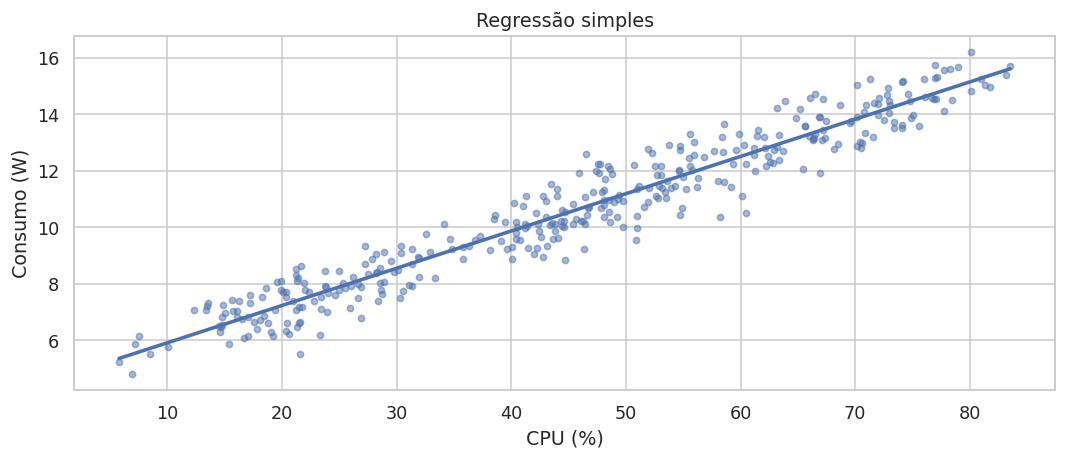

In [44]:
modelo_simples=smf.ols('consumo_w ~ cpu_pct',data=dados).fit()
print(modelo_simples.summary())
coef_cpu=modelo_simples.params['cpu_pct'];ic_cpu=modelo_simples.conf_int().loc['cpu_pct']
print(f'No modelo, +1 ponto percentual de CPU associa-se a {coef_cpu:.4f} W de consumo médio.')
print('IC 95% do coeficiente:',ic_cpu.round(4).tolist())
fig,ax=plt.subplots();sns.regplot(data=dados,x='cpu_pct',y='consumo_w',ci=None,scatter_kws={'s':15,'alpha':0.5},ax=ax)
ax.set(title='Regressão simples',xlabel='CPU (%)',ylabel='Consumo (W)');plt.show()

**Interpretação do exemplo e decisão seguinte**

O resumo inclui estimativas, erros padrão, testes e R². Começar pela equação e pelas unidades, não por uma leitura de estrelas de significância. O modelo simples pode incorporar uma relação de memória com CPU que será separada no ajuste múltiplo.

## 46. Regressão múltipla, categorias e ANCOVA

Regressão múltipla relaciona uma resposta a vários preditores. Cada coeficiente quantitativo descreve uma mudança condicional mantendo os demais termos fixos no modelo. `C(firmware)` cria contrastes para categorias em relação a uma referência; isso não equivale a codificar A=1, B=2, C=3 e impor uma distância numérica artificial.

O exemplo de ANCOVA combina um fator categórico com covariáveis contínuas para comparar latência de firmware ajustando CPU e memória. Essa leitura depende da forma do modelo e do desenho. Se a associação com CPU varia entre firmwares, será necessário considerar interação.

**O que se busca descobrir:** diferenças condicionais e associação de variáveis após ajuste. **Quando usar:** separar informação de vários preditores ou aumentar precisão com covariáveis adequadas. **Erro a evitar:** adicionar todas as colunas sem critério, inclusive consequências do tratamento, identificadores ou atributos redundantes. Um modelo ajustado não elimina automaticamente vieses de seleção e variáveis não medidas.

In [45]:
modelo_mult=smf.ols('latencia_ms ~ cpu_pct + memoria_pct + C(firmware)',data=dados).fit()
print(modelo_mult.summary())
tabela_coef=pd.DataFrame({'coeficiente':modelo_mult.params,'p':modelo_mult.pvalues,
                         'ic_inf':modelo_mult.conf_int()[0],'ic_sup':modelo_mult.conf_int()[1]})
display(tabela_coef)
print('Categoria de referência do firmware: A, conforme os termos apresentados no modelo.')

                            OLS Regression Results                            
Dep. Variable:            latencia_ms   R-squared:                       0.777
Model:                            OLS   Adj. R-squared:                  0.774
Method:                 Least Squares   F-statistic:                     309.2
Date:                Fri, 09 Oct 2026   Prob (F-statistic):          2.94e-114
Time:                        13:25:06   Log-Likelihood:                -957.95
No. Observations:                 360   AIC:                             1926.
Df Residuals:                     355   BIC:                             1945.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           21.5475      0.698  

,coeficiente,p,ic_inf,ic_sup
Intercept,21.547459,1.217347e-102,20.175683,22.919236
C(firmware)[T.B],-2.411837,8.274411e-08,-3.278130,-1.545545
C(firmware)[T.C],-5.391312,1.672610e-26,-6.307388,-4.475235
cpu_pct,0.294975,9.646722e-61,0.266183,0.323766
memoria_pct,0.009742,6.861220e-01,-0.037630,0.057114


**Interpretação do exemplo e decisão seguinte**

Um coeficiente negativo de B em relação a A indica menor latência condicional no modelo. Não confundir esse valor com a diferença bruta global. O ajuste deve ser apresentado com a fórmula e as unidades das covariáveis.

## 47. Diagnosticar resíduos, heterocedasticidade e erros padrão HC3

Um diagnóstico procura estruturas que o modelo não representou. Resíduos versus ajustados podem mostrar curvatura ou dispersão crescente. Q-Q ajuda a investigar caudas. Breusch-Pagan testa uma forma de heterocedasticidade, associando a variabilidade dos resíduos aos preditores.

Erros padrão robustos HC3 permitem inferência assintótica mais resistente a heterocedasticidade em observações independentes, com ajuste de alavancagem. Eles não corrigem uma relação média mal especificada, endogeneidade ou dependência. Para dados agrupados, uma covariância robusta por grupo ou um modelo adequado pode ser necessária.

**O que se busca descobrir:** se estimativas e incerteza são compatíveis com o modelo adotado. **Quando usar:** em toda regressão que sustentará interpretação. **Erro a evitar:** considerar normalidade de resíduos como o único diagnóstico. Forma, variância, independência e influência também importam.

Breusch-Pagan | LM: 2.2028 | p LM: 0.69851


,coef,EP_clássico,EP_HC3
Intercept,21.547459,0.697513,0.553154
C(firmware)[T.B],-2.411837,0.440487,0.441200
C(firmware)[T.C],-5.391312,0.465801,0.380372
cpu_pct,0.294975,0.014640,0.013835
memoria_pct,0.009742,0.024087,0.018434


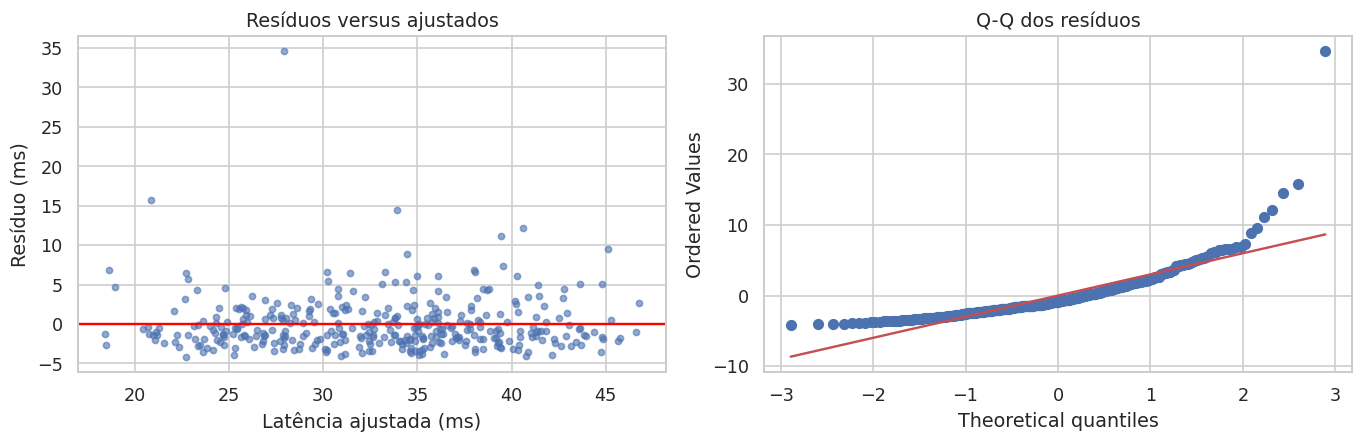

In [46]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(modelo_mult.fittedvalues,modelo_mult.resid,s=15,alpha=0.6);axs[0].axhline(0,color='red')
axs[0].set(title='Resíduos versus ajustados',xlabel='Latência ajustada (ms)',ylabel='Resíduo (ms)')
stats.probplot(modelo_mult.resid,dist='norm',plot=axs[1]);axs[1].set_title('Q-Q dos resíduos')
plt.tight_layout();plt.show()
bp=het_breuschpagan(modelo_mult.resid,modelo_mult.model.exog)
print('Breusch-Pagan | LM:',round(bp[0],4),'| p LM:',f'{bp[1]:.5g}')
modelo_hc3=modelo_mult.get_robustcov_results(cov_type='HC3')
display(pd.DataFrame({'coef':modelo_mult.params,'EP_clássico':modelo_mult.bse,
                     'EP_HC3':modelo_hc3.bse},index=modelo_mult.params.index))

**Interpretação do exemplo e decisão seguinte**

Os coeficientes OLS não mudam quando apenas a matriz de covariância muda. Mudam erros padrão e inferência. Se o gráfico mostrar relação não linear, considerar reformular a média, não apenas trocar os erros padrão.

## 48. Multicolinearidade, VIF, alavancagem e influência

Multicolinearidade ocorre quando preditores compartilham informação. Ela pode aumentar incerteza e tornar coeficientes individuais instáveis, mesmo quando o ajuste global é alto. VIF quantifica quanto a variância de um coeficiente é inflada em relação a uma referência sem aquela dependência linear. Não existe um corte universal que resolva qualquer modelo.

Alavancagem identifica posições incomuns no espaço dos preditores. Um ponto com resíduo grande não é necessariamente de alta alavancagem. Distância de Cook combina características para indicar influência sobre o ajuste. Um valor elevado é sinal de investigação, não ordem de exclusão.

**O que se busca descobrir:** redundância e dependência das conclusões de observações específicas. **Quando usar:** regressão e preparação de atributos. **Erro a evitar:** apagar pontos influentes reais sem análise de sensibilidade. Considerar simplificação fundamentada, reformulação ou coleta adicional conforme a pergunta.

,termo,VIF
0,Intercept,1.000000
1,C(firmware)[T.B],1.334099
2,C(firmware)[T.C],1.341893
3,cpu_pct,2.437335
4,memoria_pct,2.415810


,dispositivo,alavancagem,cook,residuo_studentizado
7,D007,0.009513,0.190599,9.961067
72,D072,0.016845,0.071152,4.556758
282,D282,0.013904,0.034801,3.512989
103,D103,0.009509,0.033432,4.172744
335,D335,0.019348,0.029964,2.755678
83,D083,0.012007,0.025115,3.214409
148,D148,0.012648,0.016704,2.553382
172,D172,0.018831,0.015215,1.990978


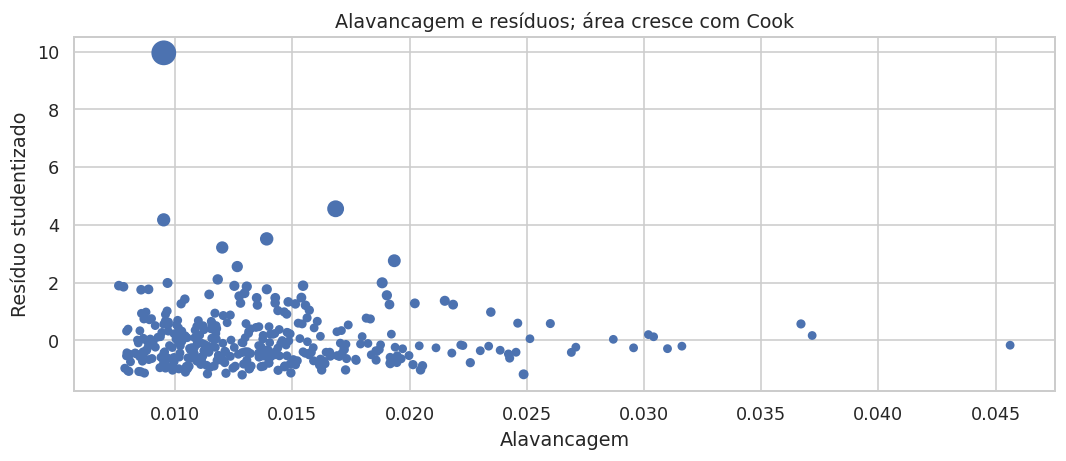

In [47]:
matriz_exog=modelo_mult.model.exog
vif=pd.DataFrame({'termo':modelo_mult.model.exog_names,
                 'VIF':[variance_inflation_factor(matriz_exog,i) for i in range(matriz_exog.shape[1])]})
display(vif)
influencia=modelo_mult.get_influence()
diagnostico=pd.DataFrame({'dispositivo':dados['dispositivo'],
    'alavancagem':influencia.hat_matrix_diag,'cook':influencia.cooks_distance[0],
    'residuo_studentizado':influencia.resid_studentized_internal})
display(diagnostico.sort_values('cook',ascending=False).head(8))
fig,ax=plt.subplots();ax.scatter(diagnostico['alavancagem'],diagnostico['residuo_studentizado'],s=20+1000*diagnostico['cook'])
ax.set(title='Alavancagem e resíduos; área cresce com Cook',xlabel='Alavancagem',ylabel='Resíduo studentizado');plt.show()

**Interpretação do exemplo e decisão seguinte**

Não interpretar VIF do intercepto como diagnóstico substantivo de uma variável. Os pontos destacados devem ser rastreados ao equipamento e ao protocolo. Em modelos com interações, centralizar variáveis pode facilitar interpretação sem eliminar dependência estrutural.

## 49. Interações e ANOVA fatorial: o efeito depende do contexto

Interação significa que a associação de um fator varia conforme outro. O termo `cpu_pct * C(firmware)` inclui os efeitos principais e a interação. Nesse caso, o coeficiente principal do firmware é interpretado na CPU de referência definida pelo modelo, não como diferença constante em toda a faixa.

Um desenho fatorial avalia combinações de fatores. O exemplo será independente e balanceado, com dois firmwares e dois níveis de carga, incluindo uma diferença maior sob carga alta. A análise mostra por que uma média única de tratamento pode esconder comportamento condicionado.

**O que se busca descobrir:** se a melhoria depende da condição de trabalho. **Quando usar:** benchmark com fatores cruzados, como compilador e otimização, firmware e carga. **Pressupostos:** unidades independentes, modelo adequado e condições da inferência. **Erro a evitar:** interpretar efeitos principais isolados quando uma interação relevante está presente.

,sum_sq,df,F,PR(>F)
C(firmware),779.862111,1.0,85.878200,3.806171e-16
C(carga),2819.416597,1.0,310.473376,6.403792e-37
C(firmware):C(carga),316.824851,1.0,34.888665,2.654715e-08
Residual,1235.019448,136.0,NaN,NaN


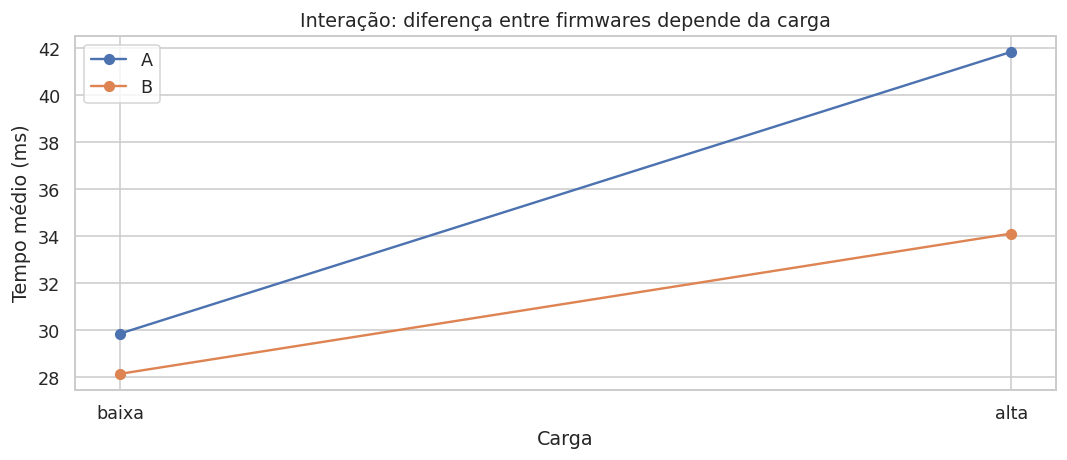

In [48]:
rfat=np.random.default_rng(112)
linhas_fat=[]
for fw in ['A','B']:
    for cg in ['baixa','alta']:
        mu=30+(12 if cg=='alta' else 0)-(2 if fw=='B' else 0)-(6 if fw=='B' and cg=='alta' else 0)
        for valor in rfat.normal(mu,3,35):linhas_fat.append({'firmware':fw,'carga':cg,'tempo_ms':valor})
fatorial=pd.DataFrame(linhas_fat)
modelo_fat=smf.ols('tempo_ms ~ C(firmware)*C(carga)',data=fatorial).fit()
display(sm.stats.anova_lm(modelo_fat,typ=2))
fig,ax=plt.subplots()
for fw,g in fatorial.groupby('firmware'):
    medias=g.groupby('carga')['tempo_ms'].mean().reindex(['baixa','alta'])
    ax.plot(medias.index,medias.values,marker='o',label=fw)
ax.set(title='Interação: diferença entre firmwares depende da carga',xlabel='Carga',ylabel='Tempo médio (ms)');ax.legend();plt.show()

**Interpretação do exemplo e decisão seguinte**

Linhas não paralelas sugerem interação, mas o gráfico amostral não é sozinho um teste. A interpretação substantiva deve apresentar a diferença dentro de cada condição. Para estudos não balanceados ou com interações, o tipo de soma de quadrados e os contrastes exigem atenção.

## 50. Intervalo da média prevista versus intervalo de observação

Uma regressão pode produzir intervalo para a média condicional e intervalo para uma observação individual. O primeiro descreve incerteza da média estimada; o segundo inclui também variabilidade residual e costuma ser mais largo.

**Pergunta:** em uma CPU de 60%, qual consumo médio o modelo estima e que faixa pode ser esperada para um novo dispositivo? São duas perguntas distintas. Um IC estreito da média não significa que cada equipamento terá consumo próximo do valor central.

**Quando usar:** comunicar previsão estatística ou estimativas condicionais. **Limite:** os intervalos dependem do modelo, da distribuição e da variância assumidas. Não são intervalos de tolerância da população nem garantias físicas. O exemplo usa o modelo simples clássico e restringe as entradas à faixa observada.

,cpu_pct,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,30,8.549565,0.046445,8.458226,8.640903,7.190523,9.908606
1,60,12.510454,0.045096,12.421767,12.599141,11.151588,13.869320
2,80,15.151047,0.073414,15.006670,15.295424,13.787414,16.514681


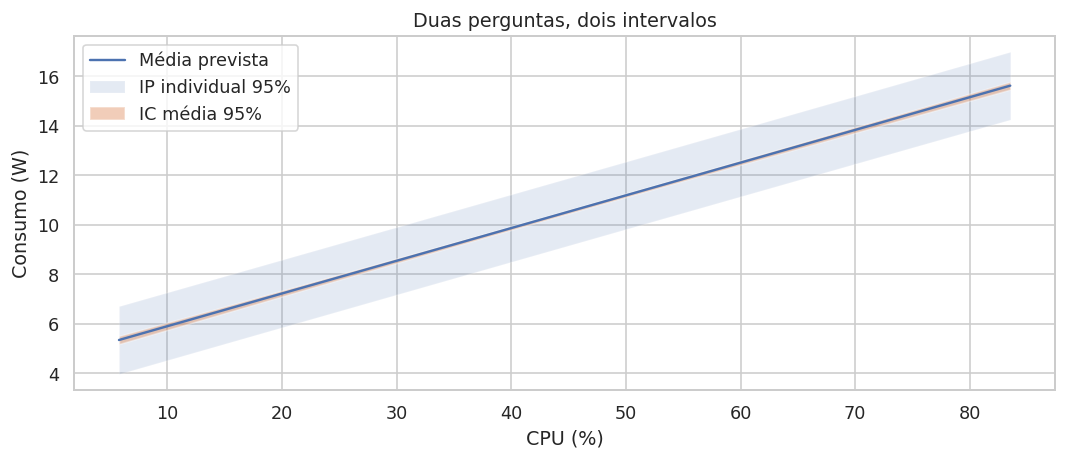

In [49]:
novos=pd.DataFrame({'cpu_pct':[30,60,80]})
intervalos_pred=modelo_simples.get_prediction(novos).summary_frame(alpha=0.05)
display(pd.concat([novos,intervalos_pred],axis=1))
grade=pd.DataFrame({'cpu_pct':np.linspace(dados['cpu_pct'].min(),dados['cpu_pct'].max(),100)})
pred_grade=modelo_simples.get_prediction(grade).summary_frame()
fig,ax=plt.subplots();ax.plot(grade['cpu_pct'],pred_grade['mean'],label='Média prevista')
ax.fill_between(grade['cpu_pct'],pred_grade['obs_ci_lower'],pred_grade['obs_ci_upper'],alpha=0.15,label='IP individual 95%')
ax.fill_between(grade['cpu_pct'],pred_grade['mean_ci_lower'],pred_grade['mean_ci_upper'],alpha=0.4,label='IC média 95%')
ax.set(title='Duas perguntas, dois intervalos',xlabel='CPU (%)',ylabel='Consumo (W)');ax.legend();plt.show()

**Interpretação do exemplo e decisão seguinte**

A faixa individual é maior porque uma nova observação contém variação além da incerteza do coeficiente. Para decisão sobre pior caso, pode ser necessário modelar quantis ou tolerâncias em vez de uma média.

## 51. Regressão robusta e regressão quantílica

Regressão robusta reduz a influência de certos resíduos grandes por uma função de perda diferente. A versão Huber preserva comportamento aproximadamente quadrático perto do centro e limita influência de resíduos maiores. Isso não transforma um ponto real em erro, nem corrige seleção ou confundimento.

Regressão quantílica modela um quantil condicional, como mediana ou p90, em vez da média. É útil quando a pergunta envolve cauda de latência ou comportamento que muda conforme a região da distribuição. Os coeficientes do quantil não devem ser apresentados como efeitos sobre a média.

**O que se busca descobrir:** estabilidade da relação frente a extremos e diferenças entre centro e cauda. **Quando usar:** dados com caudas ou objetivo focado em quantis. **Limites:** estimar quantis muito altos exige informação suficiente; quantis ajustados separadamente podem se cruzar; ambas as técnicas continuam exigindo especificação e desenho adequados.

In [50]:
robusto=smf.rlm('latencia_ms ~ cpu_pct + C(firmware)',data=dados,M=sm.robust.norms.HuberT()).fit()
quantil50=smf.quantreg('latencia_ms ~ cpu_pct + C(firmware)',data=dados).fit(q=0.50,max_iter=5000)
quantil90=smf.quantreg('latencia_ms ~ cpu_pct + C(firmware)',data=dados).fit(q=0.90,max_iter=5000)
ols_comparavel=smf.ols('latencia_ms ~ cpu_pct + C(firmware)',data=dados).fit()
display(pd.DataFrame({'OLS_média':ols_comparavel.params,'RLM_robusta':robusto.params,
                     'Quantil_50':quantil50.params,'Quantil_90':quantil90.params}))
print('Os modelos estimam alvos diferentes; comparar interpretação antes de comparar números.')

Os modelos estimam alvos diferentes; comparar interpretação antes de comparar números.


,OLS_média,RLM_robusta,Quantil_50,Quantil_90
Intercept,21.717191,21.327004,21.078905,24.233015
C(firmware)[T.B],-2.405453,-2.650119,-2.511774,-2.641760
C(firmware)[T.C],-5.385096,-5.461222,-5.573587,-5.404063
cpu_pct,0.299501,0.300051,0.297359,0.326217


**Interpretação do exemplo e decisão seguinte**

Se o p90 muda mais com CPU que a mediana, a cauda pode piorar de maneira diferente do centro. Se robusta e OLS divergem, investigar influência e objetivo. Não escolher um modelo apenas porque fornece um efeito mais favorável.

## 52. Regressão logística para uma resposta binária

Logística modela a probabilidade de um evento por meio do logaritmo das chances: $\log[p/(1-p)]=\beta_0+\beta_1X_1+\ldots$. A função inversa mantém probabilidades entre zero e um. Exponenciar um coeficiente produz uma odds ratio condicional por unidade ou contraste.

**Pergunta:** como a probabilidade de violação de SLA se associa à CPU e ao firmware? **O que se busca descobrir:** associações condicionais e probabilidades estimadas. **Quando usar:** resposta binária e unidades independentes; dependência exige extensão apropriada.

Pressupostos e diagnósticos incluem forma adequada no logit, quantidade de eventos, ausência de separação problemática e especificação. Odds ratio não é risco relativo. A alteração de probabilidade depende do ponto de partida e dos demais atributos, não sendo uma variação percentual fixa para qualquer observação.

O ajuste neste notebook tem finalidade inferencial e descritiva. Rendimento em classificação exigiria validação separada, calibração e escolha de limiar conforme custos. Não chamar o ajuste no mesmo conjunto de desempenho preditivo validado.

                 Generalized Linear Model Regression Results                  
Dep. Variable:           violacao_sla   No. Observations:                  360
Model:                            GLM   Df Residuals:                      356
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -112.63
Date:                Fri, 09 Oct 2026   Deviance:                       225.27
Time:                        13:25:07   Pearson chi2:                     340.
No. Iterations:                     6   Pseudo R-squ. (CS):            0.08002
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -4.3248      0.675  

,OR,IC_inf_OR,IC_sup_OR
Intercept,0.013236,0.003528,0.049651
C(firmware)[T.B],0.474203,0.198987,1.130063
C(firmware)[T.C],1.053220,0.477218,2.324458
cpu_pct,1.048682,1.027439,1.070364


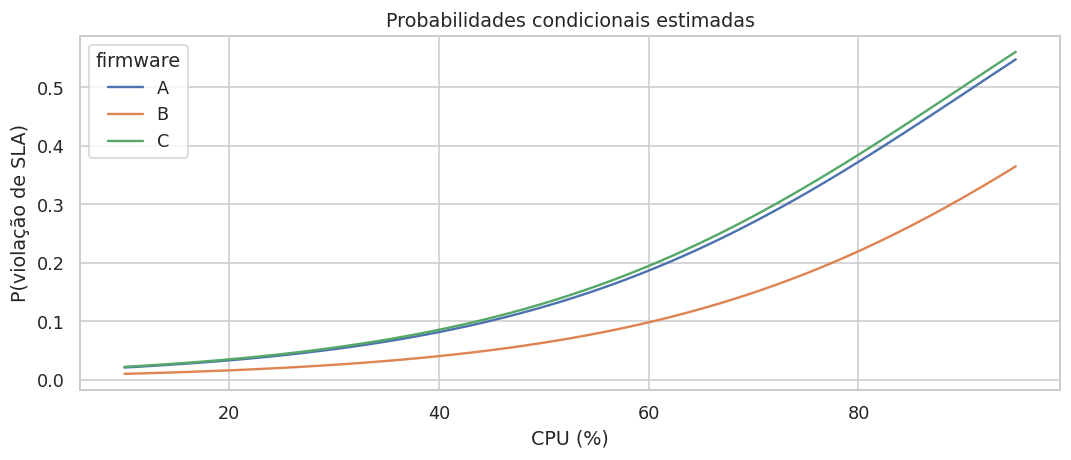

In [51]:
logistico=smf.glm('violacao_sla ~ cpu_pct + C(firmware)',data=dados,family=sm.families.Binomial()).fit()
print(logistico.summary())
ic_log=logistico.conf_int()
display(pd.DataFrame({'OR':np.exp(logistico.params),'IC_inf_OR':np.exp(ic_log[0]),'IC_sup_OR':np.exp(ic_log[1])}))
grade_log=pd.DataFrame({'cpu_pct':np.tile(np.linspace(10,95,100),3),'firmware':np.repeat(['A','B','C'],100)})
grade_log['probabilidade']=logistico.predict(grade_log)
fig,ax=plt.subplots();sns.lineplot(data=grade_log,x='cpu_pct',y='probabilidade',hue='firmware',ax=ax)
ax.set(title='Probabilidades condicionais estimadas',xlabel='CPU (%)',ylabel='P(violação de SLA)');plt.show()

**Interpretação do exemplo e decisão seguinte**

O IC de uma OR que inclui um indica compatibilidade com ausência de associação naquele contraste sob o modelo. O gráfico mostra diferenças de probabilidade em CPUs específicas, que costumam ser mais fáceis de interpretar operacionalmente.

## 53. Poisson, exposição e sobredispersão em contagens

Contagens de falhas são inteiros não negativos. Regressão Poisson relaciona o log da média condicional aos preditores; exponenciar um coeficiente produz uma razão de médias ou de taxas conforme o modelo. A hipótese Poisson envolve igualdade entre média e variância condicionais, não igualdade da média e variância de toda a amostra misturada.

**Quando usar:** contagem de eventos em oportunidades ou tempos comparáveis. Se exposições diferem, usar offset do log da exposição para modelar taxas. Uma máquina observada durante 48 horas não deve ser comparada diretamente com uma observada durante uma hora sem considerar o denominador.

**O que se busca descobrir:** associação com frequência esperada de falhas. Sobredispersão pode indicar heterogeneidade, dependência, excesso de zeros ou especificação inadequada. Binomial negativa adiciona dispersão, mas não resolve qualquer mecanismo. Seu parâmetro pode ser estimado em uma implementação apropriada; o exemplo demonstrativo de GLM abaixo fixa alfa, portanto não é uma seleção final validada.

In [52]:
poisson=smf.glm('falhas_24h ~ cpu_pct + C(firmware)',data=dados,family=sm.families.Poisson()).fit()
print(poisson.summary())
print('Dispersão de Pearson aproximada:',round(poisson.pearson_chi2/poisson.df_resid,4))
display(np.exp(poisson.params).to_frame('razão_condicional'))
# Exemplo separado: exposições diferentes, com offset correto.
rexp=np.random.default_rng(120);exp_h=rexp.uniform(4,48,160);cg_exp=rexp.uniform(10,90,160)
y_exp=rexp.poisson(exp_h*np.exp(-3+0.018*cg_exp))
base_exp=pd.DataFrame({'falhas':y_exp,'cpu':cg_exp,'horas':exp_h})
poisson_exp=smf.glm('falhas ~ cpu',data=base_exp,family=sm.families.Poisson(),offset=np.log(base_exp['horas'])).fit()
print('Coeficientes com exposição:',poisson_exp.params.round(4).to_dict())
neg_bin=smf.glm('falhas_24h ~ cpu_pct + C(firmware)',data=dados,
               family=sm.families.NegativeBinomial(alpha=0.5)).fit()
print('Binomial negativa demonstrativa: alfa fixado em 0,5, não estimado.')

                 Generalized Linear Model Regression Results                  
Dep. Variable:             falhas_24h   No. Observations:                  360
Model:                            GLM   Df Residuals:                      356
Model Family:                 Poisson   Df Model:                            3
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -568.67
Date:                Fri, 09 Oct 2026   Deviance:                       413.37
Time:                        13:25:08   Pearson chi2:                     365.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1172
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.0225      0.132  

,razão_condicional
Intercept,0.977741
C(firmware)[T.B],0.866882
C(firmware)[T.C],0.837157
cpu_pct,1.013222


**Interpretação do exemplo e decisão seguinte**

Não usar variância global maior que média como único diagnóstico: mistura de cargas pode produzir esse padrão mesmo com Poisson condicional correto. Investigar resíduos, exposição e mecanismo antes de escolher uma extensão.

## 54. Modelos mistos para medições repetidas e hierarquia

Um modelo misto combina efeitos fixos com efeitos aleatórios associados a unidades ou grupos. Um intercepto aleatório por placa representa níveis individuais diferentes, enquanto o efeito fixo do firmware estima uma mudança média no modelo.

**Quando usar:** várias medições da mesma placa, dispositivos em laboratórios ou outras estruturas hierárquicas. **O que se busca descobrir:** associação de condição preservando dependência e variabilidade entre unidades. A estrutura de efeitos aleatórios deve refletir o desenho; intercepto aleatório não é suficiente para qualquer série longitudinal.

Modelos mistos possuem pressupostos sobre erros, efeitos aleatórios e relação média. Poucos grupos podem tornar a estimação instável. Avisos de convergência, variância na fronteira ou ajuste singular exigem investigação. Não utilizar o método apenas para fazer desaparecer um p-valor problemático de um teste simples.

In [53]:
misto=smf.mixedlm('latencia_ms ~ C(firmware)',data=longa,groups=longa['placa']).fit(reml=True)
print(misto.summary())
print('Convergência informada:',misto.converged)
print('Variância do intercepto entre placas:',float(misto.cov_re.iloc[0,0]))
print('Variância residual:',float(misto.scale))

           Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  latencia_ms
No. Observations:  144      Method:              REML       
No. Groups:        48       Scale:               4.6714     
Min. group size:   3        Log-Likelihood:      -376.1442  
Max. group size:   3        Converged:           Yes        
Mean group size:   3.0                                      
------------------------------------------------------------
                 Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept        40.336    0.715  56.430 0.000 38.935 41.737
C(firmware)[T.B] -2.828    0.441  -6.410 0.000 -3.693 -1.963
C(firmware)[T.C] -5.173    0.441 -11.726 0.000 -6.038 -4.309
Group Var        19.853    2.503                            

Convergência informada: True
Variância do intercepto entre placas: 19.853442396211886
Variância residual: 4.671382076249756


**Interpretação do exemplo e decisão seguinte**

A mesma placa contribui com três medições, reconhecidas pelo agrupamento. O modelo permite uma leitura mais flexível que ignorar dependência. Para ordem, tendência no tempo ou efeitos distintos por placa, será necessário considerar termos adicionais.

## 55. MANOVA: comparar um vetor de respostas

MANOVA investiga diferenças no vetor de médias de várias respostas, como consumo e temperatura simultaneamente. Leva em conta associação entre respostas e testa hipóteses multivariadas do modelo. É distinta de executar duas ANOVAs independentes sem plano.

**Quando usar:** uma pergunta realmente multivariada, com respostas relacionadas e um desenho adequado. **O que se busca descobrir:** se os perfis médios conjuntos diferem entre condições. Pressupostos clássicos incluem independência, normalidade multivariada dos erros e estruturas de covariância adequadas. Tamanho amostral precisa sustentar a quantidade de respostas.

O exemplo gera duas respostas correlacionadas em três condições independentes. A tabela apresenta estatísticas como Wilks e Pillai. Não selecionar retrospectivamente a que tem p menor. O teste global não identifica sozinho quais respostas ou contrastes explicam a diferença. Análises posteriores exigem planejamento e multiplicidade.

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0109 2.0000 146.0000 6607.3730 0.0000
         Pillai's trace  0.9891 2.0000 146.0000 6607.3730 0.0000
 Hotelling-Lawley trace 90.5120 2.0000 146.0000 6607.3730 0.0000
    Roy's greatest root 90.5120 2.0000 146.0000 6607.3730 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
           C(grupo)        Value  Num DF  Den DF  F Value Pr > F
----------------------------------------------------------------
             Wilks' lambda 0.6025 4.0000 292.0000 21.0466 0.0000
            Pillai's trace 0.4053 4.0000 294.

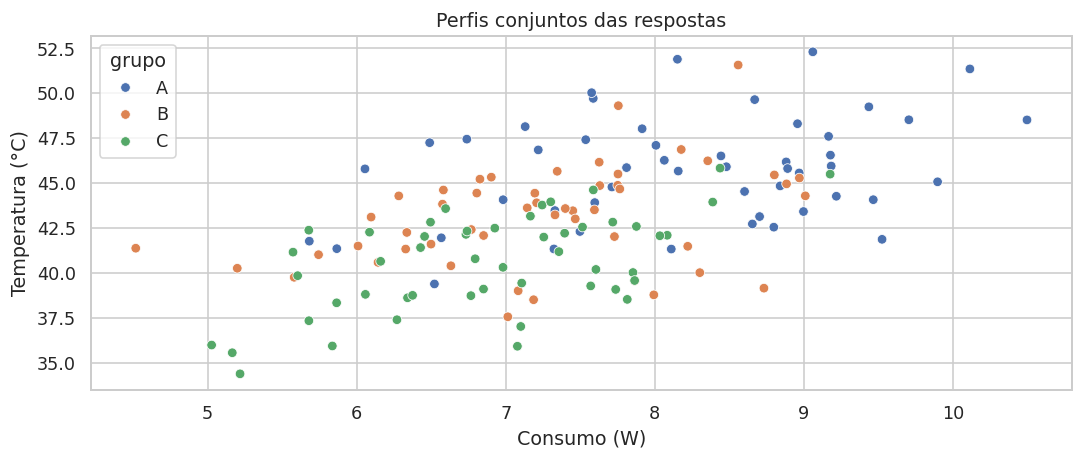

In [54]:
rman=np.random.default_rng(333)
linhas_man=[]
for grupo,desloc in zip(['A','B','C'],[0,1,2]):
    valores=rman.multivariate_normal([8-desloc*0.5,45-desloc*2],[[1,1.2],[1.2,9]],size=50)
    for w,temp in valores:linhas_man.append({'grupo':grupo,'consumo':w,'temperatura':temp})
base_man=pd.DataFrame(linhas_man)
manova=MANOVA.from_formula('consumo + temperatura ~ C(grupo)',data=base_man)
print(manova.mv_test())
fig,ax=plt.subplots();sns.scatterplot(data=base_man,x='consumo',y='temperatura',hue='grupo',ax=ax)
ax.set(title='Perfis conjuntos das respostas',xlabel='Consumo (W)',ylabel='Temperatura (°C)');plt.show()

**Interpretação do exemplo e decisão seguinte**

A pergunta é sobre um vetor de médias, não sobre grupos encontrados por um algoritmo não supervisionado. MANOVA utiliza uma condição conhecida para testar uma hipótese multivariada; agrupamento será tratado posteriormente.

## 56. Poder estatístico, tamanho amostral e equivalência

Poder é a probabilidade de rejeitar uma hipótese nula quando um efeito específico realmente existe, sob o desenho e o procedimento. Planejamento amostral precisa de efeito mínimo relevante, variabilidade, alfa, poder desejado e desenho. O exemplo usa um teste t independente com grupos de tamanho igual como aproximação de planejamento.

Não utilizar “poder observado” calculado a partir do efeito observado como substituto de IC ou para explicar retrospectivamente um p-valor. Ele adiciona pouca informação nessa função. Priorizar planejamento prévio e faixa de efeitos compatíveis.

Equivalência é outra pergunta: se a diferença é suficientemente pequena para um limite de engenharia. Não rejeitar diferença zero não demonstra equivalência. TOST realiza dois testes unilaterais contra limites previamente definidos. Com alfa de 5% em cada unilateral, a relação com o IC usual é de 90%, não 95%.

**O que se busca descobrir:** quantidade de informação necessária e se uma diferença está dentro de margens práticas. **Erro a evitar:** escolher as margens de equivalência depois de olhar o IC para obter o resultado desejado.

In [55]:
from statsmodels.stats.weightstats import ttost_ind
poder=TTestIndPower()
efeito_min=2.0;desvio_planejado=5.0;d_planejado=efeito_min/desvio_planejado
n_grupo=poder.solve_power(effect_size=d_planejado,alpha=0.05,power=0.80,ratio=1,alternative='two-sided')
print('Planejamento ilustrativo: detectar 2 ms com desvio 5 ms requer aproximadamente',int(np.ceil(n_grupo)),'por grupo.')
req=np.random.default_rng(44);eq_a=req.normal(40,2,100);eq_b=req.normal(40.3,2,100)
margem_eq=1.5
p_tost,teste_inf,teste_sup=ttost_ind(eq_a,eq_b,-margem_eq,margem_eq,usevar='unequal')
print('Margens pré-definidas: −1,5 a +1,5 ms | p global TOST:',round(float(p_tost),5))
print('Equivalência sustentada no nível definido?' ,bool(p_tost<0.05))

Planejamento ilustrativo: detectar 2 ms com desvio 5 ms requer aproximadamente 100 por grupo.
Margens pré-definidas: −1,5 a +1,5 ms | p global TOST: 1e-05
Equivalência sustentada no nível definido? True


**Interpretação do exemplo e decisão seguinte**

O cálculo é ilustrativo e deve ser adaptado para Welch, pareamento, eventos raros, dependência e multiplicidade conforme o projeto. Equivalência e ausência de diferença são conclusões distintas; não usar uma como substituto da outra.

## 57. Introdução bayesiana: probabilidade de falha com Beta-Binomial

Na análise bayesiana, uma distribuição a priori representa informação sobre o parâmetro antes dos dados; a verossimilhança conecta parâmetro e observações; a posterior combina ambas. Para tentativas binomiais independentes, uma priori Beta(a,b) resulta em posterior Beta(a+falhas,b+sucessos).

**Pergunta:** que probabilidades de falha são plausíveis após observar 8 falhas em 100 tentativas? O exemplo compara prioris e mostra um intervalo de credibilidade posterior. Diferentemente do IC frequentista, o intervalo de credibilidade admite uma interpretação de probabilidade do parâmetro condicionada ao modelo e à priori.

**O que se busca descobrir:** incerteza do parâmetro e sensibilidade à informação anterior. **Quando usar:** decisões que podem incorporar conhecimento anterior explicitado. **Limite:** uma priori uniforme não é universalmente “sem informação”. Priori, independência e estabilidade da probabilidade precisam ser justificadas. Não comparar métodos como se um eliminasse todas as limitações do outro.

Beta(1,1) | média posterior: 0.0882 | IC credível 95%: [0.0416 0.1501] | P(p>0,10|dados): 0.3094
Beta(2,18) | média posterior: 0.0833 | IC credível 95%: [0.041  0.1387] | P(p>0,10|dados): 0.2375


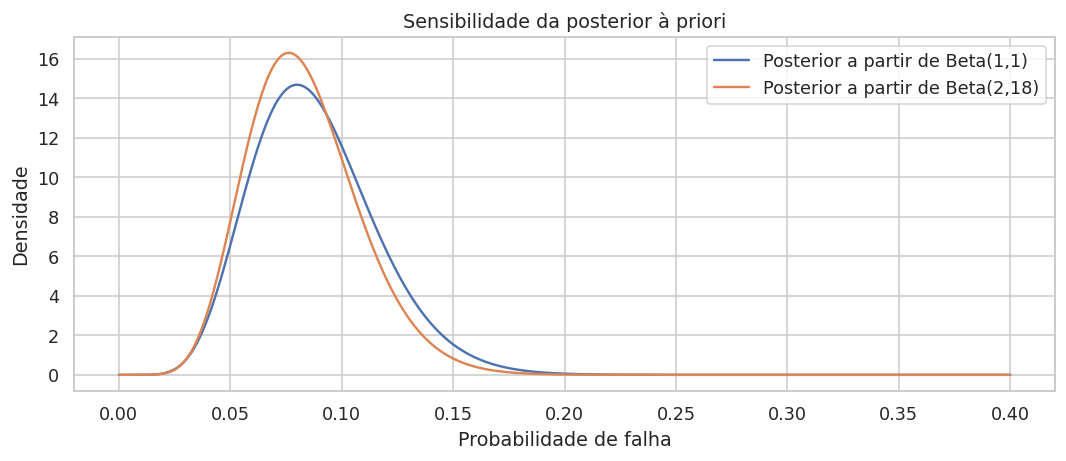

In [56]:
falhas_bayes=8;tentativas_bayes=100
p_grid=np.linspace(0.0001,0.4,500)
fig,ax=plt.subplots()
for nome,aa,bb in [('Beta(1,1)',1,1),('Beta(2,18)',2,18)]:
    ap=aa+falhas_bayes;bp=bb+tentativas_bayes-falhas_bayes
    posterior=stats.beta(ap,bp)
    ax.plot(p_grid,posterior.pdf(p_grid),label='Posterior a partir de '+nome)
    print(nome,'| média posterior:',round(posterior.mean(),4),
          '| IC credível 95%:',np.round(posterior.ppf([0.025,0.975]),4),
          '| P(p>0,10|dados):',round(1-posterior.cdf(0.10),4))
ax.set(title='Sensibilidade da posterior à priori',xlabel='Probabilidade de falha',ylabel='Densidade');ax.legend();plt.show()

**Interpretação do exemplo e decisão seguinte**

A afirmação sobre P(p > 0,10 | dados) depende da priori e do modelo binomial. Ela não representa chance de uma próxima tentativa falhar; a probabilidade preditiva integra a incerteza e pode ser obtida a partir da posterior.

## 58. Dados censurados: por que tempo até falha exige outra análise

Um dispositivo ainda funcionando ao final de um estudo não possui tempo de falha igual ao tempo de acompanhamento. Seu tempo é censurado à direita: sabe-se apenas que excede o tempo observado. Calcular a média ignorando censura pode produzir um resumo inadequado.

Kaplan-Meier estima a função de sobrevivência, a probabilidade de o evento ocorrer depois de um tempo, sob condições como censura não informativa e independência das unidades. Modelos de sobrevivência permitem comparar grupos ou ajustar covariáveis, com pressupostos próprios.

**O que se busca descobrir:** comportamento de duração com informação incompleta. **Quando usar:** tempo até falha, até reinicialização ou até resolução de incidente com acompanhamento encerrado. **Limite:** o exemplo é introdutório; não interpreta desligamentos dependentes do estado como censura inocente. Uma análise de confiabilidade completa exige causas de falha, riscos competitivos, desenho e avaliação do modelo.

Eventos observados: 62 | Censurados: 58


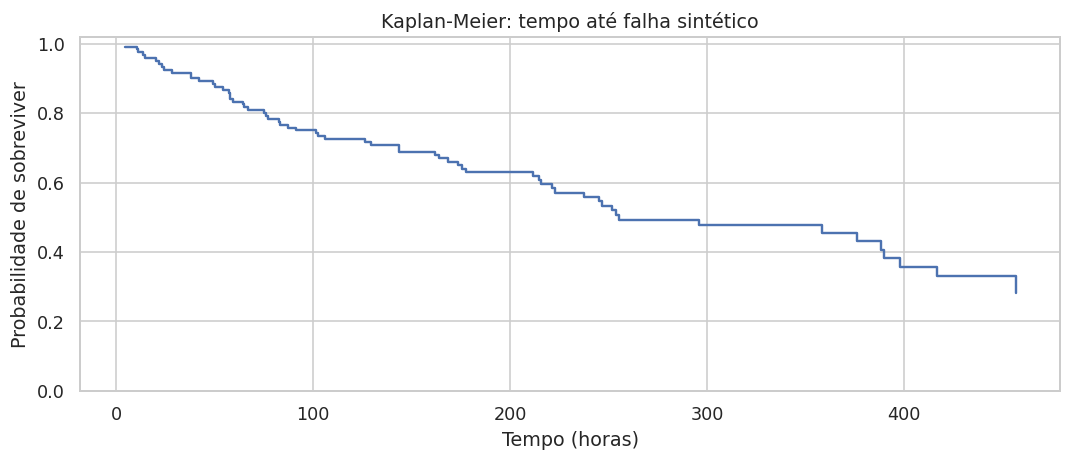

In [57]:
from statsmodels.duration.survfunc import SurvfuncRight
rsur=np.random.default_rng(108)
tempo_falha=rsur.exponential(scale=400,size=120)
acompanhamento=rsur.uniform(100,500,size=120)
tempo_observado=np.minimum(tempo_falha,acompanhamento)
evento=(tempo_falha<=acompanhamento).astype(int)
km=SurvfuncRight(tempo_observado,evento)
fig,ax=plt.subplots();ax.step(km.surv_times,km.surv_prob,where='post')
ax.set(title='Kaplan-Meier: tempo até falha sintético',xlabel='Tempo (horas)',ylabel='Probabilidade de sobreviver',ylim=(0,1.02));plt.show()
print('Eventos observados:',evento.sum(),'| Censurados:',len(evento)-evento.sum())

**Interpretação do exemplo e decisão seguinte**

A curva muda nos tempos de eventos e não trata censurados como falhas. A frequência dos censurados e o mecanismo de encerramento devem ser descritos. Não usar a média de tempos observados como vida média sem uma análise apropriada.

## 59. Escrever resultados sem extrapolar os dados

Um resultado estatístico precisa unir pergunta, desenho, estimativa, unidade, incerteza e limites. “p menor que 0,05” não é uma conclusão de engenharia. “A média foi menor” também não informa magnitude ou precisão.

**Modelo de redação:** foram comparados dispositivos independentes sob um protocolo definido; a diferença média A − B foi de determinado número de ms, com IC e teste especificados; a interpretação prática depende de um limite definido; a conclusão aplica-se ao desenho e à população sustentados pela coleta.

Resultados de dados sintéticos são demonstrações de método. Não devem ser apresentados como evidência de vantagem de um firmware real. Em dados observacionais, escrever “associado a” quando não houver justificativa causal. Para teste sem evidência, escrever que os dados não forneceram evidência suficiente, em vez de afirmar igualdade.

**O que se busca descobrir:** uma forma de comunicar que preserve a pergunta e a incerteza. **Erro a evitar:** generalizar para outras arquiteturas, períodos ou usuários sem validação. Na próxima parte, grupos serão descobertos por algoritmos, não definidos previamente; a interpretação exigirá cuidados adicionais.

In [58]:
texto=(f'Na base sintética, foram comparadas {len(a)} unidades do firmware A e {len(b)} do B. '
       f'A diferença média A−B foi {dif:.2f} ms, com IC de 95% de {dif-margem:.2f} a {dif+margem:.2f} ms. '
       f'O teste de Welch apresentou p={res_welch.pvalue:.4g}. '
       'A interpretação requer a diferença mínima relevante e as condições do experimento; '
       'este exemplo não constitui evidência sobre dispositivos reais.')
print(texto)

Na base sintética, foram comparadas 121 unidades do firmware A e 132 do B. A diferença média A−B foi 3.50 ms, com IC de 95% de 1.79 a 5.20 ms. O teste de Welch apresentou p=7.279e-05. A interpretação requer a diferença mínima relevante e as condições do experimento; este exemplo não constitui evidência sobre dispositivos reais.


**Interpretação do exemplo e decisão seguinte**

O parágrafo identifica base sintética, unidade, direção da diferença, IC e teste. Completar com protocolo, seleção das unidades e análise de pressupostos em um relatório real. Não ocultar limitações porque um resultado parece convincente.

# Parte final: técnicas não supervisionadas

As técnicas seguintes não recebem um alvo que indique a resposta correta para cada equipamento. Elas procuram estrutura a partir de atributos e critérios de semelhança. O resultado não é automaticamente uma classificação verdadeira de dispositivos: depende da seleção de variáveis, escala, distância, algoritmo e parâmetros.

Cada técnica segue o mesmo padrão das análises estatísticas: pergunta, motivo de uso, mecanismo, pressupostos ou escolhas, código, gráfico e interpretação. As bases de exemplo são separadas das comparações inferenciais anteriores para evitar confundir um fator conhecido com um grupo descoberto.

## 60. Aprendizado não supervisionado: o que pode ser descoberto

Redução de dimensionalidade procura representações compactas ou estruturas latentes. Agrupamento divide observações por semelhança. Estimação de densidade descreve regiões frequentes e raras. Detecção de anomalias atribui escores de discrepância. Regras de associação investigam coocorrências em transações.

**O que se busca descobrir:** perfis de utilização, redundância de sensores, padrões em logs ou equipamentos incomuns. **Quando usar:** não há um alvo conhecido, ou a exploração de estrutura é a própria pergunta. Sem alvo não significa sem objetivo. É necessário definir para que os grupos ou componentes serão usados.

Um algoritmo pode produzir grupos mesmo sem grupos naturais. K-means sempre particiona quando recebe k. Um gráfico com ilhas também não comprova classes reais. Validação deve combinar geometria, estabilidade, domínio e utilidade. Métricas internas não equivalem a acurácia.

Agrupamento e inferência não devem ser misturados sem cuidado: descobrir grupos em uma variável e depois testar que esses grupos diferem na mesma variável reutiliza a informação. Uma avaliação confirmatória exige desenho independente ou métodos que tratem a seleção.

## 61. Construir perfis de servidores sem fornecer seus rótulos

A nova base contém 450 perfis independentes de servidores. Cada linha é um resumo de uma janela definida: utilização de CPU e memória, volume de entrada/saída, tráfego e temperatura. A comparação depende de janelas com significado compatível. Taxas e totais de durações distintas não devem ser misturados sem ajuste.

A simulação possui três perfis latentes e alguns equipamentos incomuns. A origem latente fica armazenada apenas para uma verificação pedagógica posterior e **não entra na seleção de atributos nem no ajuste**. Em dados reais, essa origem normalmente não existe.

**O que se busca descobrir:** segmentos operacionais a partir de métricas. **Erro a evitar:** incluir o identificador, o firmware ou um rótulo que já define artificialmente o grupo, sem justificar como isso corresponde ao objetivo. Incluir contexto categórico pode ser legítimo em outros desenhos, mas requer uma representação e uma distância apropriadas.

In [59]:
rperf=np.random.default_rng(222)
centros=np.array([[22,35,30,15,38],[68,48,60,35,62],[35,82,180,130,48]],dtype=float)
ruidos=np.array([7,8,20,15,3],dtype=float)
origem_simulada=np.repeat(np.arange(3),150)
valores_perf=np.vstack([rperf.normal(c,ruidos,size=(150,5)) for c in centros])
valores_perf=np.maximum(valores_perf,0.1)
# Equipamentos com combinação incomum, preservados na exploração.
valores_perf[[12,163,322,340],:]+=np.array([25,5,220,200,10])
valores_perf[:,:2]=np.minimum(valores_perf[:,:2],99)
atributos=['cpu_pct','memoria_pct','io_mb_s','rede_mb_s','temperatura_c']
perfis=pd.DataFrame(valores_perf,columns=atributos)
perfis.insert(0,'servidor',[f'S{i:03d}' for i in range(len(perfis))])
X=perfis[atributos].copy()
display(perfis.head());display(X.describe().round(2))
print('Somente atributos numéricos definidos entram no ajuste:',atributos)
perfis.to_csv(saida/'perfis_servidores.csv',index=False)

Somente atributos numéricos definidos entram no ajuste: ['cpu_pct', 'memoria_pct', 'io_mb_s', 'rede_mb_s', 'temperatura_c']


,servidor,cpu_pct,memoria_pct,io_mb_s,rede_mb_s,temperatura_c
0,S000,21.783030,42.388513,51.685556,0.100000,38.536724
1,S001,19.101966,27.074450,50.051639,1.305641,35.345301
2,S002,25.017302,27.380854,59.854687,3.152795,33.639790
3,S003,11.078828,55.806317,55.223133,0.100000,36.671366
4,S004,33.330583,27.315271,0.318956,8.982894,41.473574


,cpu_pct,memoria_pct,io_mb_s,rede_mb_s,temperatura_c
count,450.00,450.00,450.00,450.00,450.00
mean,42.33,55.01,92.59,62.46,49.28
std,20.59,20.87,72.14,56.41,10.37
min,1.34,13.95,0.10,0.10,31.39
25%,25.37,39.60,35.16,19.44,40.01
50%,36.92,48.78,64.69,36.21,47.89
75%,63.71,75.39,169.26,122.27,59.70
max,99.00,99.00,420.17,326.41,69.94


**Interpretação do exemplo e decisão seguinte**

A variável `origem_simulada` será usada somente para mostrar o sentido de uma avaliação externa em simulação. A seleção de k, as distâncias e as transformações não utilizarão essa variável.

## 62. Distâncias, escala e por que padronizar

Distância euclidiana soma diferenças quadráticas por atributo. Uma variável de grande escala pode dominar o cálculo. Nesse exemplo, MB/s pode ter valores maiores que percentuais, mesmo sem ser mais importante para o objetivo.

`StandardScaler` subtrai a média e divide pelo desvio padrão de cada atributo. `RobustScaler` usa mediana e escala interquartil, reduzindo sensibilidade a extremos na transformação. `MinMaxScaler` reescala pela faixa observada e pode ser muito influenciado por extremos. Nenhuma opção torna os dados normais por definição.

**O que se busca descobrir:** se semelhança está sendo determinada pelo fenômeno ou apenas pelas unidades. **Quando usar:** muitos métodos de distância e PCA. **Limite:** dar variância unitária atribui importância comparável por atributo, o que precisa ser justificado. Atributos redundantes podem contar a mesma informação várias vezes. Para inferir grupos de novos dados, ajustar a transformação no conjunto de referência, não em todo o conjunto futuro.

,par,original,padronizada
0,S000×S150,86.081166,3.481286
1,S000×S300,223.152529,4.002939


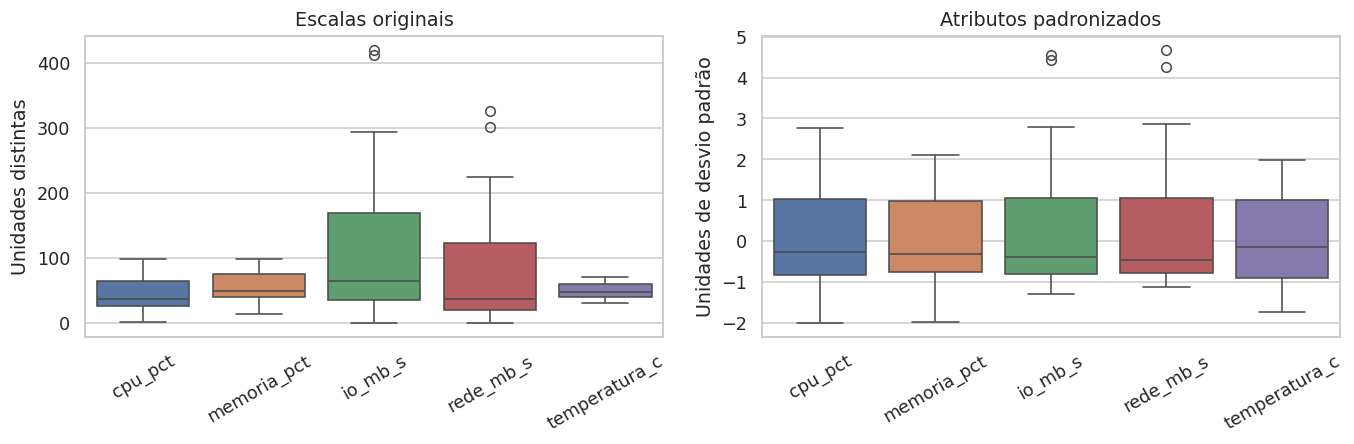

In [60]:
padronizador=StandardScaler()
Z=padronizador.fit_transform(X)
robustizador=RobustScaler();Z_robusto=robustizador.fit_transform(X)
distancias=pd.DataFrame({'par':['S000×S150','S000×S300'],
 'original':[np.linalg.norm(X.iloc[0]-X.iloc[j]) for j in [150,300]],
 'padronizada':[np.linalg.norm(Z[0]-Z[j]) for j in [150,300]]})
display(distancias)
fig,axs=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=X,ax=axs[0]);axs[0].set(title='Escalas originais',ylabel='Unidades distintas');axs[0].tick_params(axis='x',rotation=30)
sns.boxplot(data=pd.DataFrame(Z,columns=atributos),ax=axs[1]);axs[1].set(title='Atributos padronizados',ylabel='Unidades de desvio padrão');axs[1].tick_params(axis='x',rotation=30)
plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

A transformação mudou a geometria, não corrigiu os servidores. Comparar soluções com e sem escalonamento pode ser uma análise de sensibilidade. Não escolher a escala apenas porque produz um gráfico mais separado.

## 63. Escolher atributos e uma noção de semelhança

Euclidiana combina diferenças contínuas. Manhattan soma diferenças absolutas e pode ser apropriada para algumas estruturas. Cosseno compara orientação de vetores, sendo útil quando a composição do perfil importa mais que seu tamanho, como em textos. Jaccard compara presença/ausência de eventos, desconsiderando ausências conjuntas.

**O que se busca descobrir:** que significa dois equipamentos serem parecidos. Essa definição deve vir do objetivo. A distância pode determinar os grupos tanto quanto o algoritmo. Variáveis categóricas nominais não devem receber números arbitrários e entrar numa Euclidiana como se distância entre códigos fosse física.

Em dados mistos, considerar métodos compatíveis, como distância de Gower e algoritmos que aceitem distâncias pré-calculadas, ou modelos específicos como k-prototypes em uma implementação adequada. One-hot com numéricas escalonadas pode funcionar em alguns problemas, mas exige controle dos pesos e não é uma solução universal.

Dados composicionais, como parcelas que somam exatamente 100%, possuem geometria restrita e podem exigir razões logarítmicas. CPU e memória aqui são utilizações independentes que não precisam somar 100%, portanto não formam uma composição única.

In [61]:
amostra_z=Z[:6]
for metrica in ['euclidean','cityblock','cosine']:
    print('Métrica:',metrica)
    display(pd.DataFrame(squareform(pdist(amostra_z,metric=metrica))).round(3))
print('Distâncias diferentes representam perguntas diferentes sobre semelhança.')

Métrica: euclidean
Métrica: cityblock
Métrica: cosine
Distâncias diferentes representam perguntas diferentes sobre semelhança.


,0,1,2,3,4,5
0,0.000,0.808,0.885,0.849,1.205,0.967
1,0.808,0.000,0.360,1.440,1.151,1.085
2,0.885,0.360,0.000,1.553,1.196,0.922
3,0.849,1.440,1.553,0.000,1.964,1.581
4,1.205,1.151,1.196,1.964,0.000,1.302
5,0.967,1.085,0.922,1.581,1.302,0.000


,0,1,2,3,4,5
0,0.000,1.217,1.518,1.393,2.439,1.944
1,1.217,0.000,0.636,1.989,2.122,2.256
2,1.518,0.636,0.000,2.452,2.094,1.949
3,1.393,1.989,2.452,0.000,3.832,2.990
4,2.439,2.122,2.094,3.832,0.000,2.441
5,1.944,2.256,1.949,2.990,2.441,0.000


,0,1,2,3,4,5
0,0.000,0.036,0.058,0.068,0.154,0.123
1,0.036,0.000,0.010,0.173,0.109,0.045
2,0.058,0.010,0.000,0.211,0.125,0.020
3,0.068,0.173,0.211,0.000,0.373,0.274
4,0.154,0.109,0.125,0.373,0.000,0.179
5,0.123,0.045,0.020,0.274,0.179,0.000


**Interpretação do exemplo e decisão seguinte**

Mesmo após padronizar, a escolha de distância permanece uma decisão substantiva. Métodos não aceitam todas as métricas indistintamente: K-means está associado à geometria euclidiana quadrática; Ward exige uma estrutura euclidiana.

## 64. PCA: reduzir redundância com combinações lineares

PCA encontra direções ortogonais de maior variância. A primeira componente captura a maior variabilidade possível em uma combinação linear; as seguintes capturam variabilidade restante e são ortogonais. Os escores representam os equipamentos no novo sistema de coordenadas.

**Pergunta:** as cinco métricas podem ser resumidas em poucas direções? **O que se busca descobrir:** redundância e contrastes entre atributos. **Quando usar:** visualização, compressão e preparação de uma representação compacta. **Escolhas:** centralização, escala e quantidade de componentes. Variáveis de grande dispersão dominam se não houver padronização.

PCA não recebe rótulos, não maximiza separação entre grupos e não descobre causalidade. Variância elevada pode ser ruído ou um contraste sem utilidade. Uma componente não é um equipamento nem uma nova medição física direta. Seu significado depende dos pesos e dos atributos incluídos.

Variância acumulada em duas componentes: 0.9328


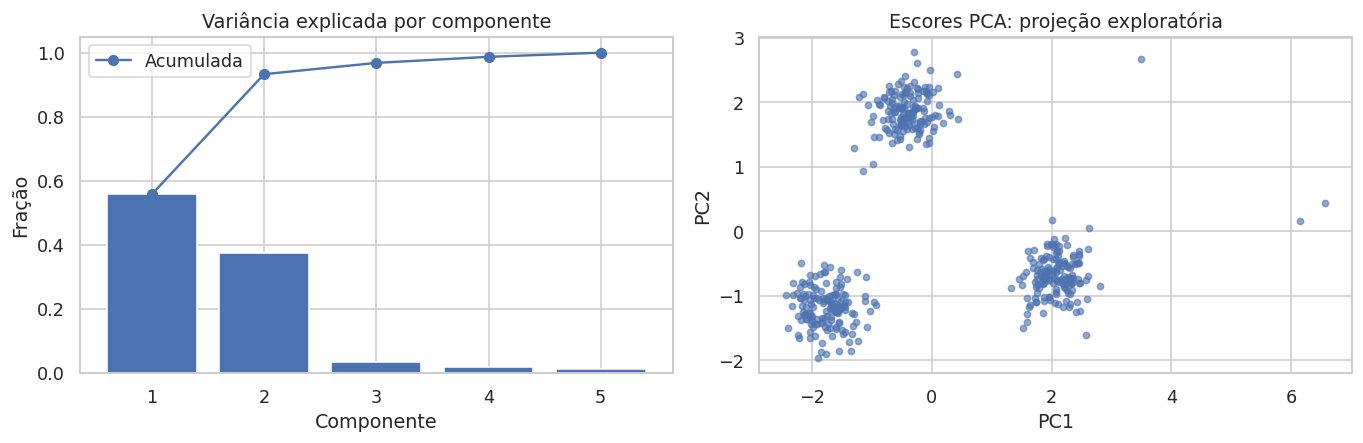

In [62]:
pca=PCA(n_components=len(atributos))
componentes=pca.fit_transform(Z)
var_exp=pca.explained_variance_ratio_
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].bar(np.arange(1,len(atributos)+1),var_exp);axs[0].plot(np.arange(1,len(atributos)+1),np.cumsum(var_exp),'o-',label='Acumulada')
axs[0].set(title='Variância explicada por componente',xlabel='Componente',ylabel='Fração');axs[0].legend()
axs[1].scatter(componentes[:,0],componentes[:,1],s=15,alpha=0.6)
axs[1].set(title='Escores PCA: projeção exploratória',xlabel='PC1',ylabel='PC2')
plt.tight_layout();plt.show()
print('Variância acumulada em duas componentes:',round(float(var_exp[:2].sum()),4))

**Interpretação do exemplo e decisão seguinte**

As distâncias no gráfico utilizam somente duas direções. Dois pontos próximos nessa projeção podem estar separados nas dimensões omitidas. Uma aparente ilha precisa de validação antes de ser chamada de grupo real.

## 65. Interpretar pesos, número de componentes e reconstrução

Os pesos em `components_` definem a combinação linear de atributos padronizados. Pesos de mesmo sinal indicam contribuição na mesma direção; sinais opostos definem contrastes. O sinal inteiro de uma componente pode ser invertido sem alterar o PCA, portanto positivo e negativo não possuem valor intrínseco.

A escolha do número de componentes pode usar variância acumulada, erro de reconstrução e objetivo de uso. Um corte de 90% é uma regra ilustrativa, não um padrão universal. Comprimir demais pode remover um padrão raro importante para falhas. Compressão boa em média não significa preservação da cauda.

**O que se busca descobrir:** significado da representação e quantidade de informação perdida. **Quando usar:** antes de usar PCA em agrupamento ou monitoramento. **Cuidado:** pesos das combinações não são automaticamente correlações entre variável e componente. Essas correlações podem ser calculadas separadamente.

Componentes para atingir 90% nesta base: 2
Erro quadrático médio de reconstrução padronizada: 0.06721


,PC1,PC2,PC3,PC4,PC5
cpu_pct,0.0845,0.7044,-0.1817,-0.6790,0.0510
memoria_pct,0.5609,-0.0555,0.8003,-0.2035,-0.0199
io_mb_s,0.5759,-0.0959,-0.3611,0.1227,0.7167
rede_mb_s,0.5682,-0.1392,-0.4278,-0.0109,-0.6889
temperatura_c,0.1541,0.6871,0.1139,0.6946,-0.0935


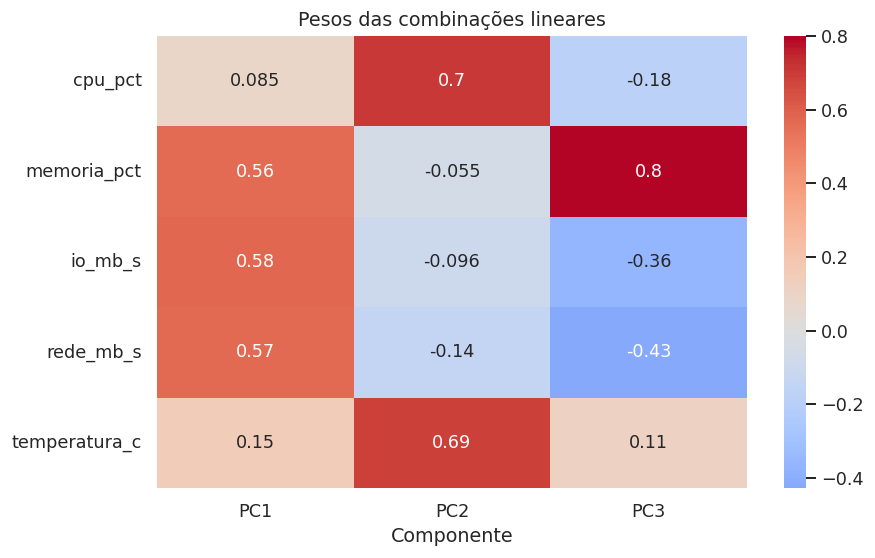

In [63]:
pesos=pd.DataFrame(pca.components_.T,index=atributos,columns=[f'PC{i+1}' for i in range(len(atributos))])
display(pesos.round(4))
k_pca=int(np.searchsorted(np.cumsum(var_exp),0.90)+1)
print('Componentes para atingir 90% nesta base:',k_pca)
pca_compacto=PCA(n_components=k_pca);escores_compactos=pca_compacto.fit_transform(Z)
Z_recon=pca_compacto.inverse_transform(escores_compactos)
print('Erro quadrático médio de reconstrução padronizada:',round(float(np.mean((Z-Z_recon)**2)),5))
fig,ax=plt.subplots(figsize=(8,5));sns.heatmap(pesos.iloc[:,:3],annot=True,cmap='coolwarm',center=0,ax=ax)
ax.set(title='Pesos das combinações lineares',xlabel='Componente');plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

Verificar quais atributos formam os contrastes. Se uma direção combina IO e rede, ela pode representar intensidade de transferência; esse nome é uma interpretação a validar, não uma conclusão automaticamente emitida pelo PCA.

## 66. Análise fatorial: modelar fatores latentes e variância específica

Análise fatorial modela covariâncias por poucos fatores latentes e uma parte específica por variável. PCA é uma decomposição de variância total; análise fatorial usa um modelo para estrutura compartilhada e variância específica. São objetivos próximos, mas não idênticos.

**Quando usar:** existe uma hipótese de que sensores ou indicadores compartilham fatores não observados, como atividade computacional ou intensidade de IO. **O que se busca descobrir:** padrões de covariação coerentes com um modelo latente. A quantidade de fatores, a rotação e a adequação da estrutura precisam ser avaliadas.

O exemplo utiliza dois fatores e rotação varimax para facilitar a leitura. Fatores podem ser invertidos e permutados. Não chamar uma combinação estatística de mecanismo físico sem validação. Em aplicações com questionários ou mensuração, a análise de validade exige teoria, qualidade das variáveis, tamanho amostral e outros diagnósticos.

,Fator1,Fator2
cpu_pct,-0.0184,0.9273
memoria_pct,0.8803,0.0880
io_mb_s,0.9704,0.0343
rede_mb_s,0.9619,-0.0264
temperatura_c,0.0905,0.9667


,variância_específica
cpu_pct,0.139367
memoria_pct,0.217369
io_mb_s,0.057166
rede_mb_s,0.074154
temperatura_c,0.057729


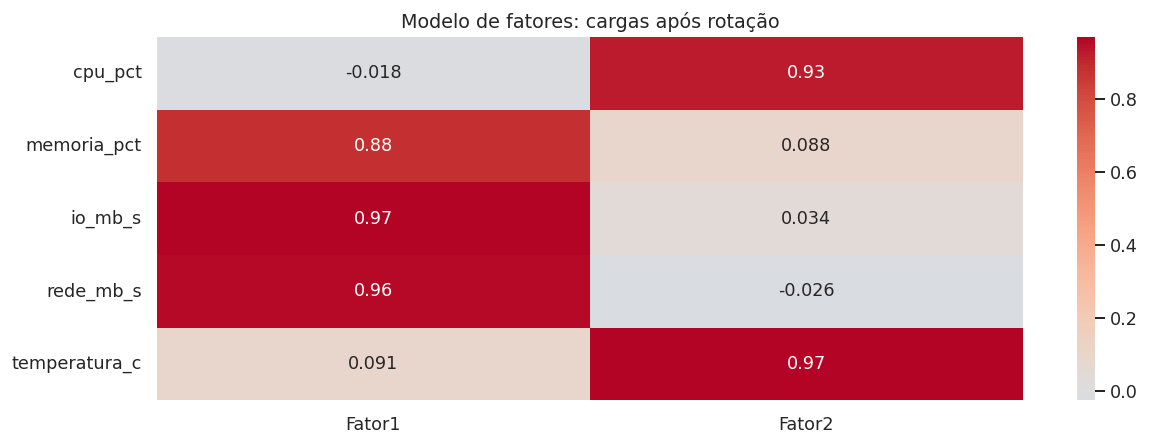

In [64]:
fatorial_latente=FactorAnalysis(n_components=2,rotation='varimax',random_state=42)
escores_fatores=fatorial_latente.fit_transform(Z)
cargas_fatores=pd.DataFrame(fatorial_latente.components_.T,index=atributos,columns=['Fator1','Fator2'])
display(cargas_fatores.round(4))
display(pd.Series(fatorial_latente.noise_variance_,index=atributos,name='variância_específica').to_frame())
fig,ax=plt.subplots();sns.heatmap(cargas_fatores,annot=True,cmap='coolwarm',center=0,ax=ax)
ax.set_title('Modelo de fatores: cargas após rotação');plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

A interpretação depende da correlação entre indicadores e da representação adotada. A fatoração não comprova que existam exatamente dois mecanismos físicos independentes. Comparar adequação e estabilidade antes de atribuir nomes definitivos.

## 67. SVD truncada e uma aplicação a logs textuais

SVD decompõe uma matriz em direções e valores singulares. A versão truncada mantém poucas direções e é útil para matrizes esparsas. Em textos, TF-IDF atribui pesos às palavras de acordo com presença e frequência na coleção; SVD truncada produz uma representação compacta de padrões de coocorrência.

Ao contrário do PCA usual, `TruncatedSVD` não exige centralizar a matriz esparsa. Por isso sua interpretação de variância e direções não deve ser confundida automaticamente com PCA centralizado.

**O que se busca descobrir:** padrões de vocabulário que ajudam a organizar mensagens. **Quando usar:** logs ou documentos representados por vetores esparsos. **Limites:** escolha de idioma, tokenização, termos, quantidade de documentos e dimensões afeta a representação. Uma base de poucas mensagens serve apenas para aprender o código, não para validar categorias de incidentes.

Componente 1 | termos de maior peso absoluto: disco, armazenamento, leitura, escrita, erro
Componente 2 | termos de maior peso absoluto: pacote, rede, conexão, perda, timeout
Componente 3 | termos de maior peso absoluto: temperatura, cpu, ventilador, alta, alerta


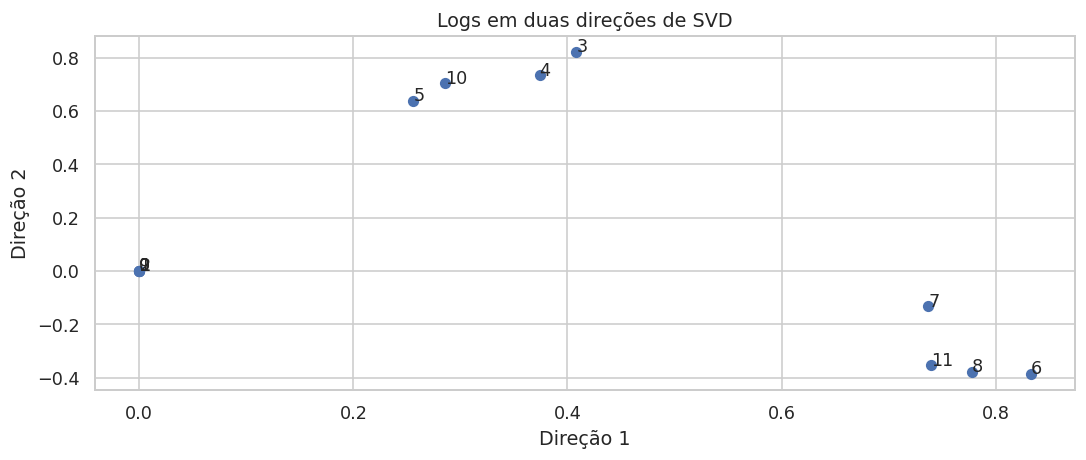

In [65]:
logs=[
 'cpu temperatura alta ventilador alerta', 'cpu aquecimento temperatura limite',
 'ventilador falha temperatura processador', 'rede pacote perda conexão timeout',
 'rede conexão indisponível pacote timeout', 'latência rede perda pacote',
 'disco escrita leitura erro armazenamento', 'disco armazenamento leitura timeout',
 'escrita disco erro leitura bloco', 'cpu utilização processo elevado',
 'rede tráfego conexão pacote', 'armazenamento disco escrita bloco']
vetorizador=TfidfVectorizer()
matriz_texto=vetorizador.fit_transform(logs)
svd=TruncatedSVD(n_components=3,random_state=42)
representacao_logs=svd.fit_transform(matriz_texto)
termos=vetorizador.get_feature_names_out()
for i,comp in enumerate(svd.components_,1):
    top=termos[np.argsort(np.abs(comp))[-5:][::-1]]
    print('Componente',i,'| termos de maior peso absoluto:',', '.join(top))
fig,ax=plt.subplots();ax.scatter(representacao_logs[:,0],representacao_logs[:,1])
for i,(u,v) in enumerate(representacao_logs[:,:2]):ax.annotate(str(i), (u,v))
ax.set(title='Logs em duas direções de SVD',xlabel='Direção 1',ylabel='Direção 2');plt.show()

**Interpretação do exemplo e decisão seguinte**

Palavras destacadas orientam uma leitura, mas não são rótulos verdadeiros. Inspecionar mensagens originais e verificar se termos genéricos, como timeout, atravessam várias causas. O pré-processamento textual faz parte da definição de semelhança.

## 68. NMF: representar dados não negativos por partes

Fatoração de matrizes não negativas aproxima X por W×H com valores não negativos. Cada observação combina componentes com pesos não negativos. Isso pode facilitar representações por partes, como perfis de eventos ou espectros.

**Quando usar:** atributos não negativos cujo mecanismo admite combinações aditivas. **O que se busca descobrir:** componentes recorrentes que compõem os perfis. A escala dos atributos e o número de componentes continuam importantes. NMF não é PCA com restrição simples: resolve outro problema de otimização e seus componentes não precisam ser ortogonais.

Será usado MinMaxScaler para manter valores não negativos e reduzir diferenças de escala. Essa transformação define o problema; em uma aplicação física, outra normalização pode ser mais interpretável. Valores centralizados pelo StandardScaler podem ficar negativos e não são entradas válidas para NMF.

Erro de reconstrução: 1.9128 | Iterações: 498


,cpu_pct,memoria_pct,io_mb_s,rede_mb_s,temperatura_c
Parte1,3.2791,0.0000,0.2411,0.0741,3.9653
Parte2,0.0000,0.8566,1.7313,1.7770,0.4369
Parte3,0.7450,2.3313,0.1084,0.0000,0.4555


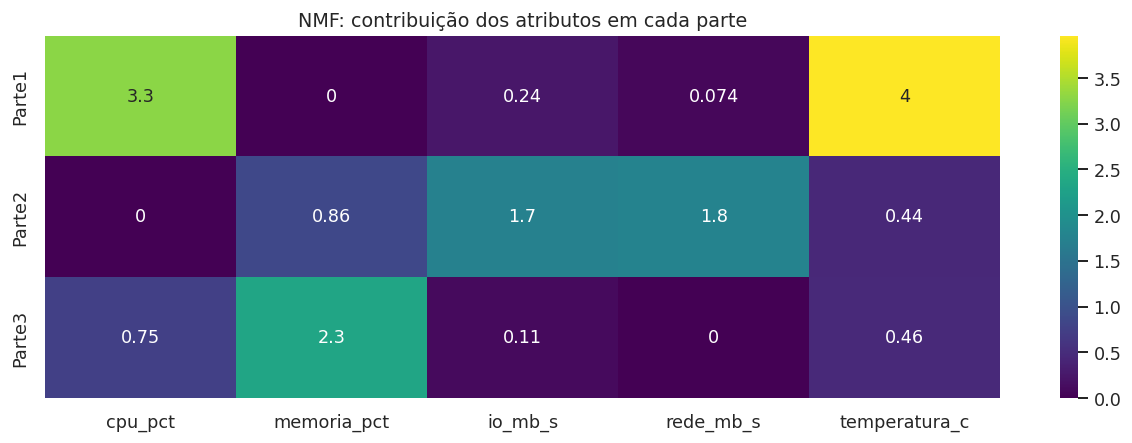

In [66]:
escala_nmf=MinMaxScaler()
X_positivo=escala_nmf.fit_transform(X)
nmf=NMF(n_components=3,init='nndsvda',random_state=42,max_iter=3000)
W_nmf=nmf.fit_transform(X_positivo)
H_nmf=pd.DataFrame(nmf.components_,columns=atributos,index=['Parte1','Parte2','Parte3'])
display(H_nmf.round(4))
print('Erro de reconstrução:',round(nmf.reconstruction_err_,5),'| Iterações:',nmf.n_iter_)
fig,ax=plt.subplots();sns.heatmap(H_nmf,annot=True,cmap='viridis',ax=ax)
ax.set_title('NMF: contribuição dos atributos em cada parte');plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

Uma parte pode enfatizar rede e IO, outra CPU e temperatura. Esses nomes devem ser verificados contra os perfis originais. Soluções podem variar entre inicializações e números de componentes; avaliar estabilidade e utilidade.

## 69. ICA: separar fontes estatisticamente independentes

ICA procura fontes estatisticamente independentes a partir de misturas. Independência é mais forte que ausência de correlação. O método é relevante para separação de sinais e remoção de artefatos quando o modelo de mistura faz sentido.

**O que se busca descobrir:** sinais subjacentes que foram misturados nos sensores. **Quando usar:** fontes aproximadamente independentes e uma mistura compatível com a formulação, frequentemente linear. Identificabilidade envolve condições como fontes não gaussianas, com no máximo uma gaussiana na formulação clássica. Não é uma técnica genérica para encontrar fatores causais em qualquer tabela.

O exemplo mistura três sinais artificiais. A ordem, escala e sinal das fontes recuperadas são ambíguos; uma componente pode aparecer invertida e ainda representar a mesma fonte. **Erro a evitar:** comparar colunas pelo mesmo índice sem alinhar permutação e sinal.

Iterações: 3


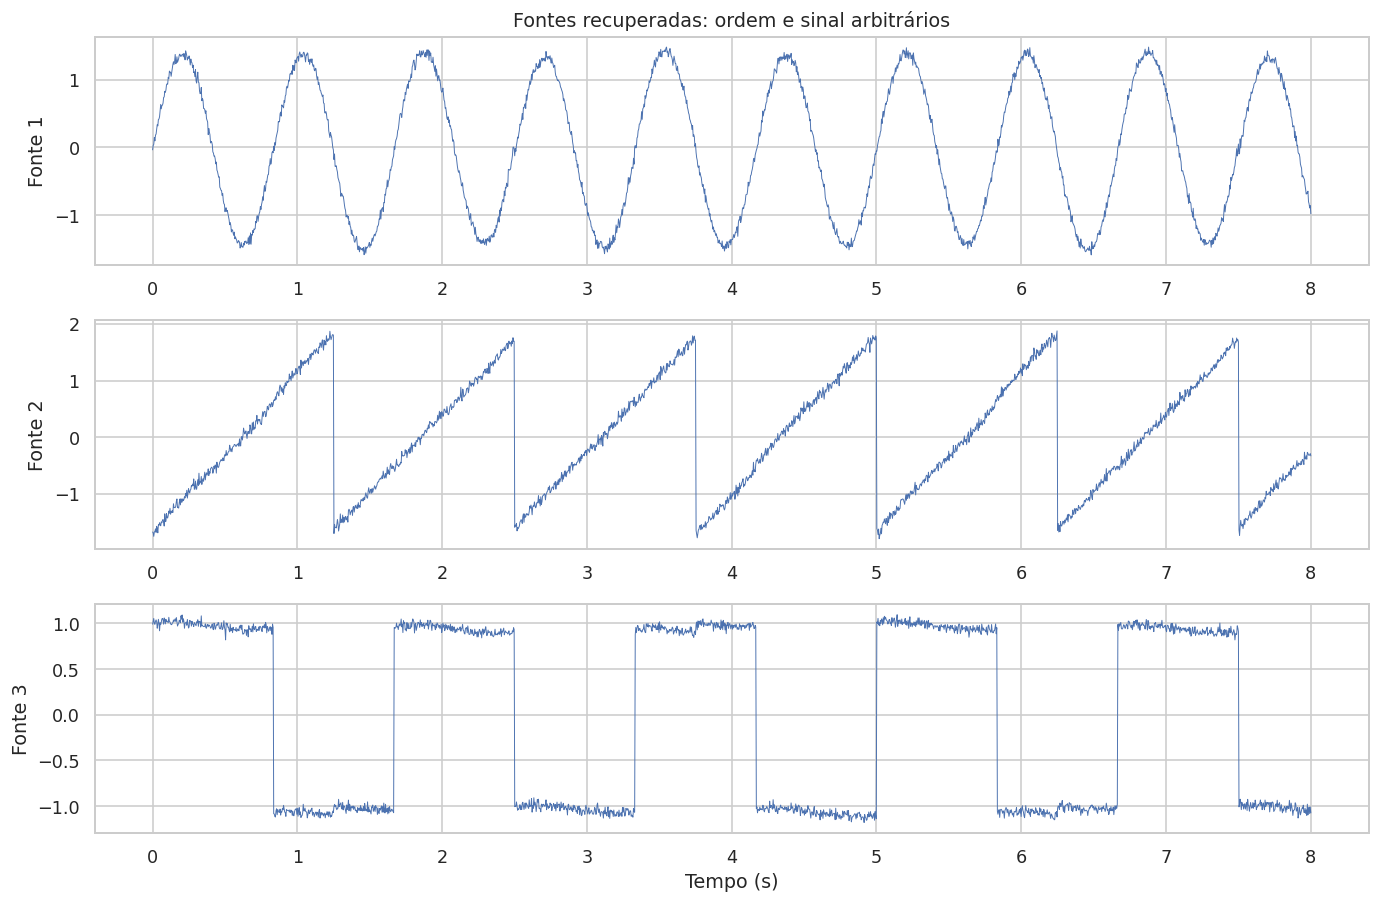

In [67]:
from scipy import signal
rica=np.random.default_rng(404)
t_sinal=np.linspace(0,8,2000)
fontes=np.column_stack([np.sin(2*np.pi*1.2*t_sinal),signal.square(2*np.pi*0.6*t_sinal),signal.sawtooth(2*np.pi*0.8*t_sinal)])
fontes+=rica.normal(0,0.03,fontes.shape)
fontes/=fontes.std(axis=0)
mistura=np.array([[1,0.8,0.5],[0.4,1,0.6],[0.8,0.2,1]])
observado=fontes@mistura.T
ica=FastICA(n_components=3,whiten='unit-variance',random_state=42,max_iter=3000,tol=0.001)
recuperado=ica.fit_transform(observado)
fig,axs=plt.subplots(3,1,figsize=(12,8))
for j in range(3):axs[j].plot(t_sinal,recuperado[:,j],linewidth=0.6);axs[j].set(ylabel=f'Fonte {j+1}')
axs[0].set_title('Fontes recuperadas: ordem e sinal arbitrários');axs[-1].set_xlabel('Tempo (s)')
plt.tight_layout();plt.show()
print('Iterações:',ica.n_iter_)

**Interpretação do exemplo e decisão seguinte**

A recuperação é possível porque o exemplo foi construído para atender ao modelo. Sensores reais podem apresentar mistura não linear, fontes dependentes e ruído complexo. Nesses casos, componentes estatísticas não correspondem diretamente a fontes físicas.

## 70. K-means: perfis em torno de centroides

K-means divide observações em k grupos minimizando a soma de distâncias euclidianas quadráticas aos centroides. Alterna atribuição ao centro mais próximo e atualização dos centros. Iniciações diferentes podem levar a soluções diferentes; `n_init` repete a busca.

**Pergunta:** quais grupos compactos de utilização existem nesta representação? **O que se busca descobrir:** centroides e atribuições de perfis semelhantes. **Quando usar:** uma representação quantitativa em que grupos aproximadamente compactos façam sentido. **Escolhas:** k, atributos, escala e inicializações.

O método não estima automaticamente o número verdadeiro de grupos. É sensível a extremos e pode falhar com formas curvas, densidades distintas ou grupos muito diferentes em tamanho. Um rótulo 0, 1 ou 2 é arbitrário e não possui ordenação de qualidade. Nomes operacionais serão atribuídos depois da inspeção das métricas originais.

Inércia: 284.0529


,cpu_pct,memoria_pct,io_mb_s,rede_mb_s,temperatura_c
0,68.17,48.67,61.88,33.50,61.99
1,36.44,80.62,185.22,136.08,48.03
2,22.49,35.23,28.80,16.31,37.84


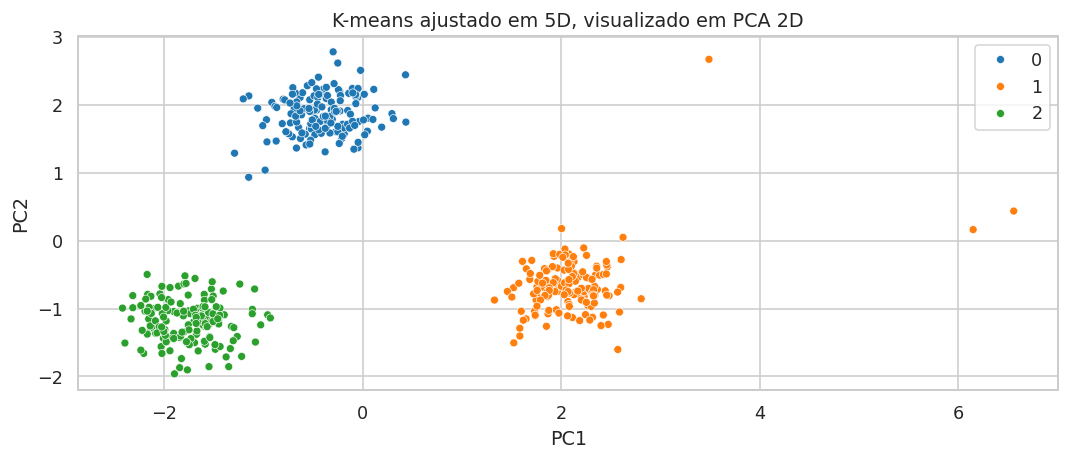

In [68]:
kmeans_inicial=KMeans(n_clusters=3,n_init=20,random_state=42)
rotulos_k3=kmeans_inicial.fit_predict(Z)
centros_originais=pd.DataFrame(padronizador.inverse_transform(kmeans_inicial.cluster_centers_),columns=atributos)
display(centros_originais.round(2))
fig,ax=plt.subplots();sns.scatterplot(x=componentes[:,0],y=componentes[:,1],hue=rotulos_k3,palette='tab10',ax=ax,s=25)
ax.set(title='K-means ajustado em 5D, visualizado em PCA 2D',xlabel='PC1',ylabel='PC2');plt.show()
print('Inércia:',round(kmeans_inicial.inertia_,4))

**Interpretação do exemplo e decisão seguinte**

O ajuste foi realizado nas cinco dimensões padronizadas, não no gráfico de PCA. Interpretar grupos por centroides, dispersões e exemplos originais. A escolha inicial de três serve ao ensino e será confrontada com métricas e estabilidade.

## 71. Escolher k com cotovelo e silhueta

Inércia diminui quando k aumenta, chegando a zero se cada observação for um grupo. Por isso, menor inércia sozinha não escolhe k. O cotovelo procura um ganho marginal que passa a ser menor, mas pode não ser nítido.

Silhueta compara a distância média de uma observação ao seu grupo com a distância a grupos vizinhos. Valores próximos de um sugerem separação na métrica escolhida; perto de zero sugerem fronteira; negativos sugerem atribuição pouco coerente. O índice só é definido com quantidade adequada de grupos e observações.

**O que se busca descobrir:** soluções geométricas candidatas. **Quando usar:** apoiar a escolha de k junto a interpretação e estabilidade. **Limites:** silhueta favorece certas formas e pode penalizar grupos curvos válidos. Uma boa silhueta não comprova utilidade nem classes reais. O exemplo selecionará o maior valor entre k de 2 a 7 como regra exploratória explícita.

k exploratório selecionado: 4


,k,inercia,silhueta
0,2,1110.4131,0.5327
1,3,284.0529,0.7241
2,4,223.4506,0.7321
3,5,207.6766,0.5587
4,6,192.2853,0.3712
5,7,178.9309,0.1889


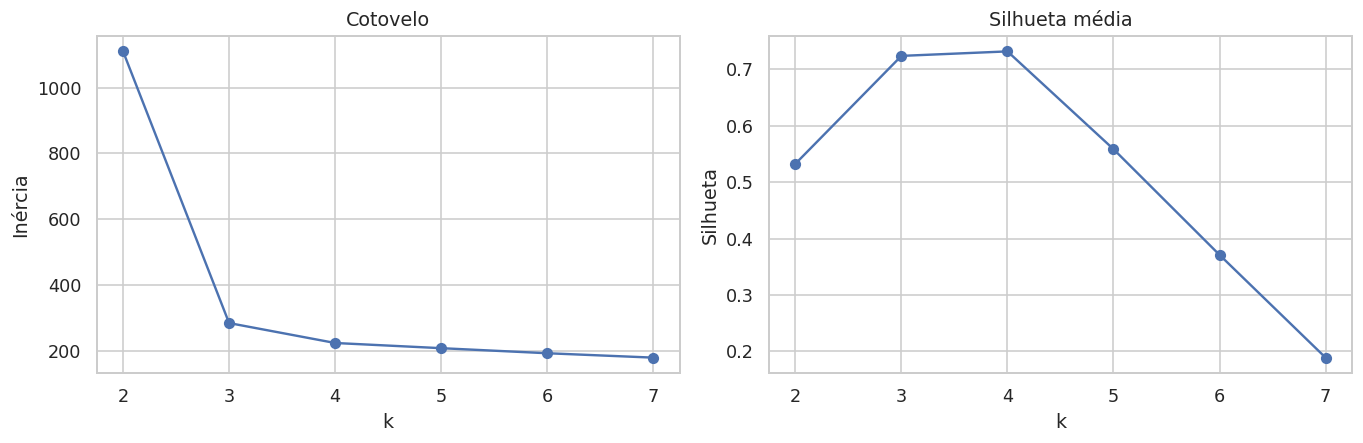

In [69]:
avaliacao_k=[]
for k in range(2,8):
    mod=KMeans(n_clusters=k,n_init=20,random_state=42).fit(Z)
    avaliacao_k.append({'k':k,'inercia':mod.inertia_,'silhueta':silhouette_score(Z,mod.labels_)})
avaliacao_k=pd.DataFrame(avaliacao_k);display(avaliacao_k.round(4))
k_escolhido=int(avaliacao_k.loc[avaliacao_k['silhueta'].idxmax(),'k'])
kmeans=KMeans(n_clusters=k_escolhido,n_init=30,random_state=42).fit(Z)
rotulos_k=kmeans.labels_
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(avaliacao_k['k'],avaliacao_k['inercia'],'o-');axs[0].set(title='Cotovelo',xlabel='k',ylabel='Inércia')
axs[1].plot(avaliacao_k['k'],avaliacao_k['silhueta'],'o-');axs[1].set(title='Silhueta média',xlabel='k',ylabel='Silhueta')
plt.tight_layout();plt.show();print('k exploratório selecionado:',k_escolhido)

**Interpretação do exemplo e decisão seguinte**

O maior índice entre candidatos não é uma descoberta definitiva do número de populações. Registrar a faixa investigada, verificar grupos minúsculos e examinar se pequenas alterações de parâmetros mudam a conclusão.

Nesta simulação há três perfis principais e equipamentos inseridos com combinações incomuns. Uma solução com um grupo adicional pode separar esses equipamentos em vez de descobrir uma quarta atividade operacional. Conferir o tamanho e o perfil de cada grupo antes de interpretar o número escolhido. A origem geradora não participou da escolha de k.

## 72. Interpretar grupos nas unidades originais e em perfis

Um grupo deve ser descrito por quantidade, centro, dispersão e exemplos. O centro não representa todos os integrantes. Um agrupamento de alta rede pode conter dispositivos muito diferentes em temperatura, e isso importa para a decisão.

**O que se busca descobrir:** significado operacional de cada grupo e possível ação. **Quando usar:** imediatamente após ajustar. Nomes como “CPU elevada” ou “IO intenso” são hipóteses interpretativas fundamentadas em atributos, não rótulos fornecidos automaticamente pelo algoritmo.

Comparar grupos nas variáveis usadas para criá-los é descrição esperada do procedimento. Executar ANOVA e afirmar que p pequeno valida a existência dos grupos nessas mesmas variáveis seria circular. Validação externa deve utilizar critérios não utilizados no ajuste ou dados independentes, respeitando a seleção.

O gráfico padronizado permite comparar perfis, mas o relatório final também deve mostrar unidades originais, tamanhos e variabilidade.

Exemplos de servidores do grupo 0:


,n
grupo,
0,149
1,149
2,149
3,3


cpu_pct               memoria_pct               io_mb_s  ...         \
         mean median    std        mean median    std    mean  ...    std   
grupo                                                          ...          
0       68.17  67.47   6.99       48.67  48.02   7.72   61.88  ...  18.56   
1       22.49  22.92   6.66       35.23  35.12   8.08   28.80  ...  19.78   
2       35.61  36.62   7.00       80.71  80.61   8.82  181.39  ...  19.44   
3       77.55  68.13  18.62       76.13  89.42  27.78  375.39  ...  70.40   

      rede_mb_s                temperatura_c               
           mean  median    std          mean median   std  
grupo                                                      
0         33.50   34.39  13.55         61.99  62.02  3.16  
1         16.31   15.65  12.67         37.84  38.02  2.64  
2        133.10  132.86  16.30         47.75  47.78  2.85  
3        284.06  301.83  53.49         62.30  61.70  7.34  

[4 rows x 15 columns]

,servidor,cpu_pct,memoria_pct,io_mb_s,rede_mb_s,temperatura_c,grupo
150,S150,69.175376,52.412606,66.188513,65.654945,62.109241,0
151,S151,80.115647,52.159789,64.727122,10.120144,58.434734,0
152,S152,57.870177,42.053022,59.150624,28.092729,61.840639,0
153,S153,59.952802,56.736398,100.938797,23.959606,59.593939,0
154,S154,64.546882,43.635187,58.588151,22.325797,58.910885,0


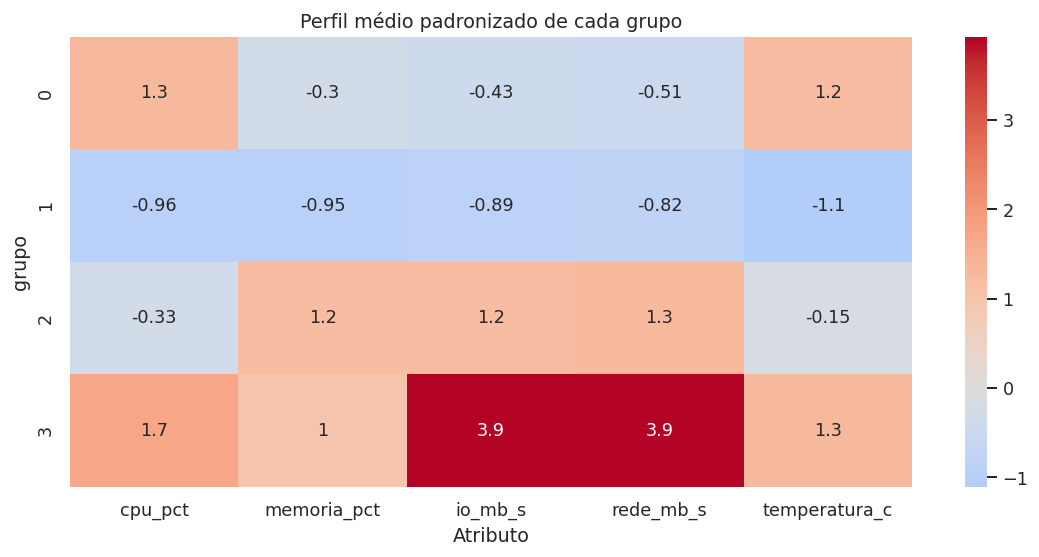

In [70]:
perfis_agrupados=perfis.assign(grupo=rotulos_k)
resumo_clusters=perfis_agrupados.groupby('grupo')[atributos].agg(['mean','median','std'])
display(perfis_agrupados['grupo'].value_counts().sort_index().to_frame('n'))
display(resumo_clusters.round(2))
medias_z=pd.DataFrame(Z,columns=atributos).assign(grupo=rotulos_k).groupby('grupo').mean()
fig,ax=plt.subplots(figsize=(10,5));sns.heatmap(medias_z,annot=True,cmap='coolwarm',center=0,ax=ax)
ax.set(title='Perfil médio padronizado de cada grupo',xlabel='Atributo');plt.tight_layout();plt.show()
print('Exemplos de servidores do grupo 0:')
display(perfis_agrupados.loc[perfis_agrupados['grupo']==0].head())

**Interpretação do exemplo e decisão seguinte**

Nomear cada grupo após olhar seu perfil. Um grupo pequeno pode representar outliers, uma atividade especializada ou uma divisão artificial. Sua existência não determina automaticamente uma política de manutenção.

## 73. MiniBatchKMeans para volume maior de dados

MiniBatchKMeans atualiza centroides usando pequenos lotes, reduzindo custo em bases grandes. Ele aproxima o objetivo de K-means com menor tempo e memória em situações adequadas, podendo produzir uma solução diferente da otimização com toda a base.

**Quando usar:** muitos perfis ou fluxos em que o custo de reprocessar tudo é alto. **O que se busca descobrir:** segmentos semelhantes com restrição computacional. O tamanho do lote e a inicialização afetam o resultado.

O exemplo pequeno serve para mostrar a API e comparar partições. Não demonstra uma vantagem de tempo, pois medir uma única execução curta seria instável. Ajuste incremental também exige controlar escala e mudanças no processo. Se o padronizador mudar, os centroides antigos podem estar em outra representação.

In [71]:
mini_batch=MiniBatchKMeans(n_clusters=k_escolhido,batch_size=64,n_init=10,random_state=42).fit(Z)
print('Inércia MiniBatch:',round(mini_batch.inertia_,4))
print('Concordância ARI com K-means:',round(adjusted_rand_score(rotulos_k,mini_batch.labels_),4))
print('ARI compara partições ignorando nomes arbitrários dos grupos.')

Inércia MiniBatch: 267.8479
Concordância ARI com K-means: 0.8665
ARI compara partições ignorando nomes arbitrários dos grupos.


**Interpretação do exemplo e decisão seguinte**

Uma concordância alta sugere que a aproximação manteve a partição neste exemplo. Ela não substitui avaliar utilidade, estabilidade e comportamento em um volume real de dados.

## 74. Agrupamento hierárquico e dendrograma

Agrupamento aglomerativo começa com observações separadas e combina grupos progressivamente. Um dendrograma mostra a sequência de fusões e suas alturas. Cortar a árvore em uma altura ou em uma quantidade de grupos define uma partição.

Ward procura fusões que aumentem pouco a variabilidade interna em uma geometria euclidiana. Ligação completa usa a maior distância entre elementos de dois grupos; ligação média usa uma média; ligação simples usa a menor e pode formar encadeamentos. Essas escolhas podem produzir árvores diferentes.

**O que se busca descobrir:** uma estrutura de proximidade em vários níveis. **Quando usar:** explorar hierarquia ou quando não se deseja começar por centroides. **Limite:** o dendrograma não é uma árvore causal nem uma taxonomia verdadeira. Outliers, escala e ligação alteram a estrutura. A árvore completa pode ter custo elevado, frequentemente quadrático em memória e tempo conforme a implementação.

O gráfico será truncado para manter legibilidade. Altura de fusão e corte devem ser interpretados em conjunto com perfis e estabilidade, não apenas pela aparência.

ARI entre Ward e K-means: 0.9966
Silhueta Ward: 0.7312


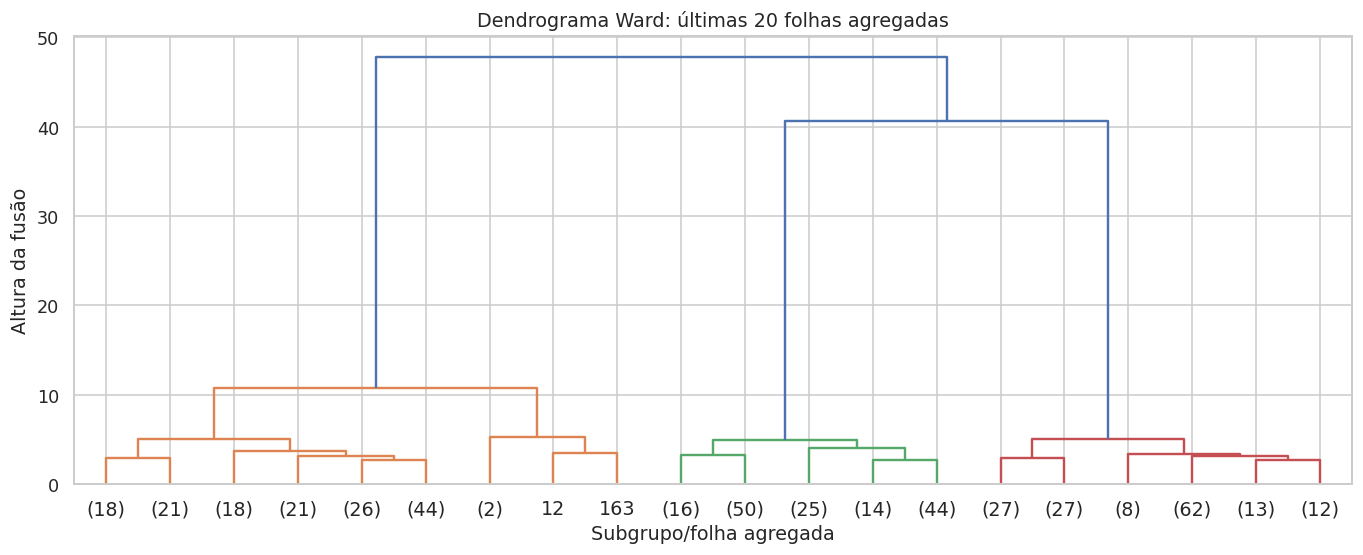

In [72]:
arvore=linkage(Z,method='ward')
fig,ax=plt.subplots(figsize=(12,5));dendrogram(arvore,truncate_mode='lastp',p=20,show_leaf_counts=True,ax=ax)
ax.set(title='Dendrograma Ward: últimas 20 folhas agregadas',xlabel='Subgrupo/folha agregada',ylabel='Altura da fusão');plt.tight_layout();plt.show()
hierarquico=AgglomerativeClustering(n_clusters=k_escolhido,linkage='ward')
rotulos_hier=hierarquico.fit_predict(Z)
print('ARI entre Ward e K-means:',round(adjusted_rand_score(rotulos_k,rotulos_hier),4))
print('Silhueta Ward:',round(silhouette_score(Z,rotulos_hier),4))

**Interpretação do exemplo e decisão seguinte**

Ward e K-means compartilham uma preferência por grupos compactos, mas não seguem o mesmo caminho de otimização. Discordâncias apontam observações de fronteira ou estruturas diferentes, não provam que um método esteja errado.

## 75. DBSCAN: grupos por densidade e pontos de ruído

DBSCAN utiliza vizinhanças para identificar regiões densas. `eps` define o raio na métrica escolhida; `min_samples` define quantidade mínima na vizinhança para um ponto central. Pontos de fronteira podem pertencer a um grupo sem serem centrais. O rótulo −1 indica pontos não atribuídos como grupo pelo procedimento.

**Quando usar:** grupos de formas não convexas e interesse em ruído. **O que se busca descobrir:** regiões conectadas de densidade suficiente. Não exige informar k, mas exige definir escala de densidade. Em altas dimensões, distâncias e parâmetros podem se tornar difíceis de interpretar. Densidades muito diferentes também podem exigir outros métodos.

O exemplo utiliza duas curvas artificiais para comparar com K-means. A base é diferente dos servidores e foi escolhida para mostrar forma geométrica. Ruído do DBSCAN não equivale a falha física: é uma classificação algorítmica dependente dos parâmetros.

Quantidade de grupos DBSCAN: 2 | Ruído: 1


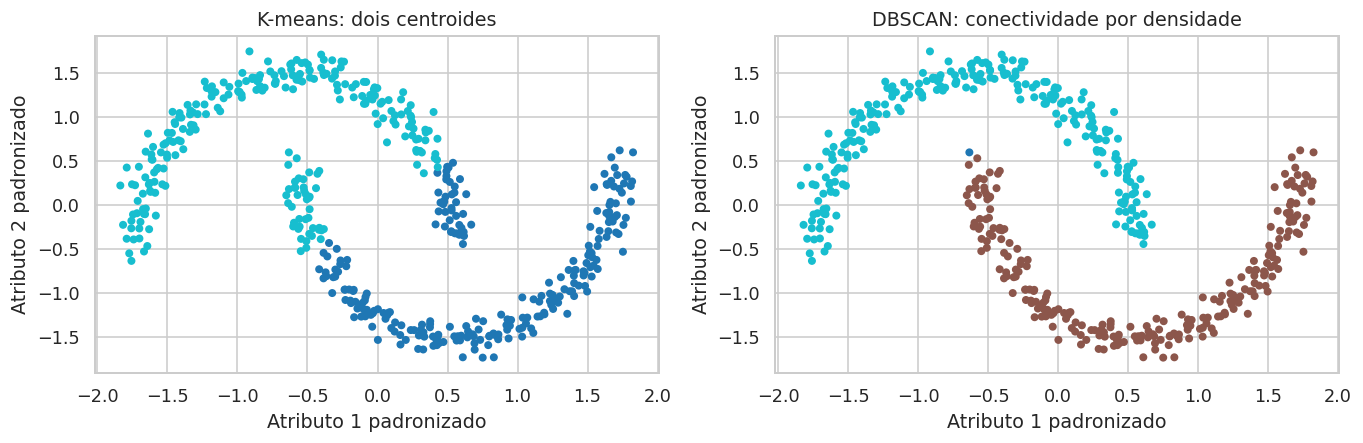

In [73]:
from sklearn.datasets import make_moons
curvas,_=make_moons(n_samples=500,noise=0.055,random_state=42)
curvas_z=StandardScaler().fit_transform(curvas)
rotulos_k_curvas=KMeans(n_clusters=2,n_init=20,random_state=42).fit_predict(curvas_z)
dbscan=DBSCAN(eps=0.23,min_samples=8)
rotulos_db=dbscan.fit_predict(curvas_z)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,rot,titulo in zip(axs,[rotulos_k_curvas,rotulos_db],['K-means: dois centroides','DBSCAN: conectividade por densidade']):
    ax.scatter(curvas_z[:,0],curvas_z[:,1],c=rot,cmap='tab10',s=16)
    ax.set(title=titulo,xlabel='Atributo 1 padronizado',ylabel='Atributo 2 padronizado')
plt.tight_layout();plt.show()
print('Quantidade de grupos DBSCAN:',len(set(rotulos_db)-{-1}),'| Ruído:',int((rotulos_db==-1).sum()))

**Interpretação do exemplo e decisão seguinte**

Um método de forma compacta pode cortar curvas de maneira pouco coerente. DBSCAN pode recuperar conectividade nessa escala, mas mudar eps pode juntar os grupos ou transformar quase tudo em ruído. A aparência precisa ser confrontada com parâmetros.

## 76. Escolher parâmetros de densidade e analisar sensibilidade

Um gráfico de distância ao k-ésimo vizinho mostra escalas de vizinhança na base. Uma mudança de inclinação pode sugerir um eps candidato. A regra não é uma garantia e depende da escala, dimensão e quantidade de dados.

**O que se busca descobrir:** uma faixa de parâmetros plausível e estabilidade da solução. **Quando usar:** antes de interpretar grupos de densidade. Variar eps e min_samples permite identificar se o resultado é robusto ou muito frágil.

Silhueta pode ser calculada nos pontos atribuídos quando houver pelo menos dois grupos válidos, mas excluir ruído muda a população avaliada. Uma solução que ignora muitos pontos pode ter silhueta elevada nos restantes. Por isso, reportar também fração de ruído e tamanhos dos grupos. Silhueta Euclidiana pode ser pouco adequada para grupos curvos como as luas, mesmo quando a divisão faz sentido.

Não comparar uma única métrica entre algoritmos que estão avaliando populações ou representações diferentes como se fosse um ranking universal.

,eps,grupos,fracao_ruido,silhueta_sem_ruido
0,0.15,6,0.030,0.192183
1,0.20,2,0.008,0.394274
2,0.23,2,0.002,0.391305
3,0.30,2,0.000,0.388538
4,0.45,2,0.000,0.388538


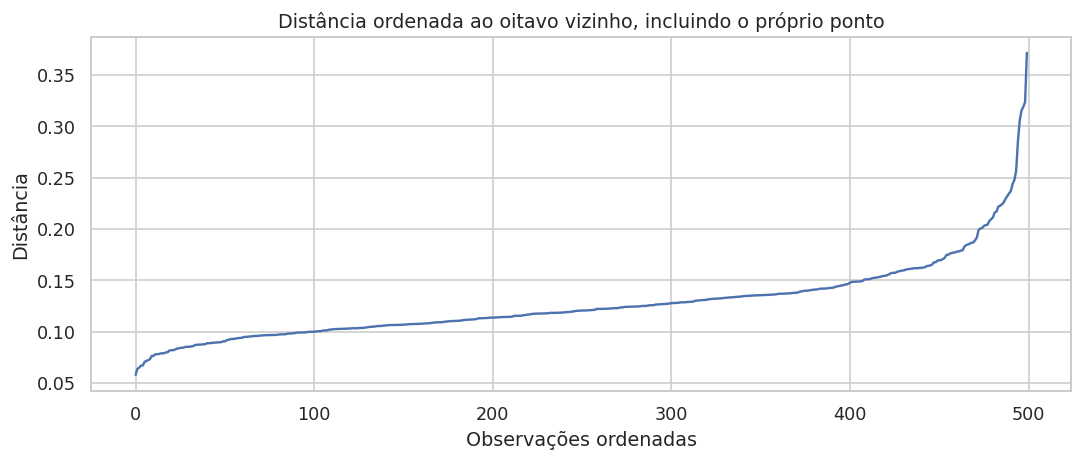

In [74]:
vizinhos=NearestNeighbors(n_neighbors=8).fit(curvas_z)
dist_viz,_=vizinhos.kneighbors(curvas_z)
fig,ax=plt.subplots();ax.plot(np.sort(dist_viz[:,-1]))
ax.set(title='Distância ordenada ao oitavo vizinho, incluindo o próprio ponto',xlabel='Observações ordenadas',ylabel='Distância');plt.show()
sens_db=[]
for eps in [0.15,0.20,0.23,0.30,0.45]:
    rot=DBSCAN(eps=eps,min_samples=8).fit_predict(curvas_z)
    mask=rot!=-1;k=len(set(rot[mask]))
    sil=silhouette_score(curvas_z[mask],rot[mask]) if 1<k<mask.sum() else np.nan
    sens_db.append({'eps':eps,'grupos':k,'fracao_ruido':1-mask.mean(),'silhueta_sem_ruido':sil})
display(pd.DataFrame(sens_db))

**Interpretação do exemplo e decisão seguinte**

A tabela permite reconhecer parâmetros que mudam muito o número de grupos ou o ruído. A quantidade de vizinhos inclui o próprio ponto, coerente com a convenção desta implementação. Não transportar o mesmo eps para dados em outra escala.

## 77. OPTICS e HDBSCAN para estrutura de densidade

OPTICS organiza observações por acessibilidade de densidade e oferece uma representação de alcance. Regiões de menor alcance podem indicar grupos; a extração depende de parâmetros como `xi` ou um raio. Ele ajuda quando uma única escala de densidade é insuficiente.

HDBSCAN constrói uma hierarquia baseada em densidade e extrai grupos estáveis conforme seu critério. `min_cluster_size` controla tamanho mínimo de grupo; `min_samples` controla conservadorismo de densidade. A implementação utilizada é a disponível no scikit-learn; diferenças de convenção com outros pacotes precisam ser verificadas.

**O que se busca descobrir:** grupos que persistem em escalas de densidade, com pontos não atribuídos. **Quando usar:** densidades variáveis ou exploração de estrutura de alcance. **Limites:** escala, atributos e parâmetros continuam relevantes. A probabilidade de pertencimento de HDBSCAN é uma medida da estrutura do algoritmo, não uma probabilidade clínica ou física de categoria verdadeira.

OPTICS: grupos = 3 | ruído = 347
HDBSCAN: grupos = 2 | ruído = 0


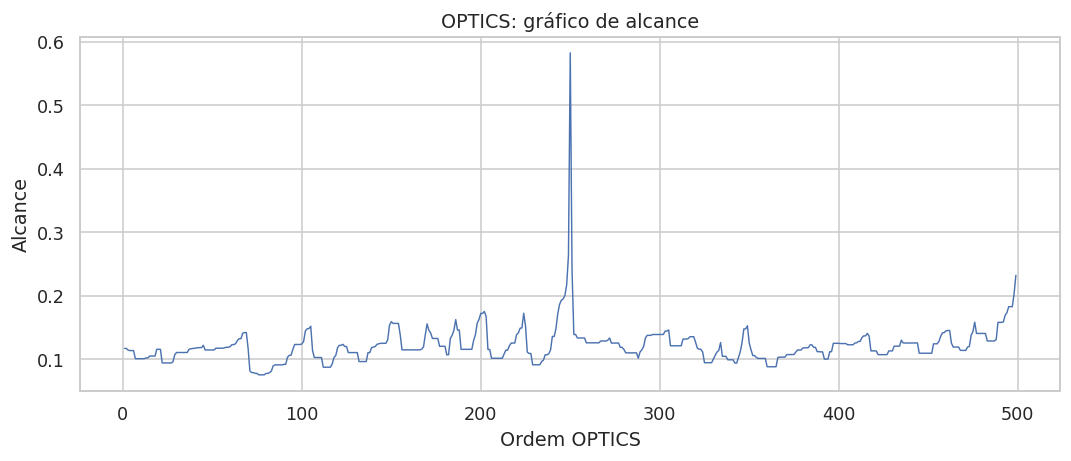

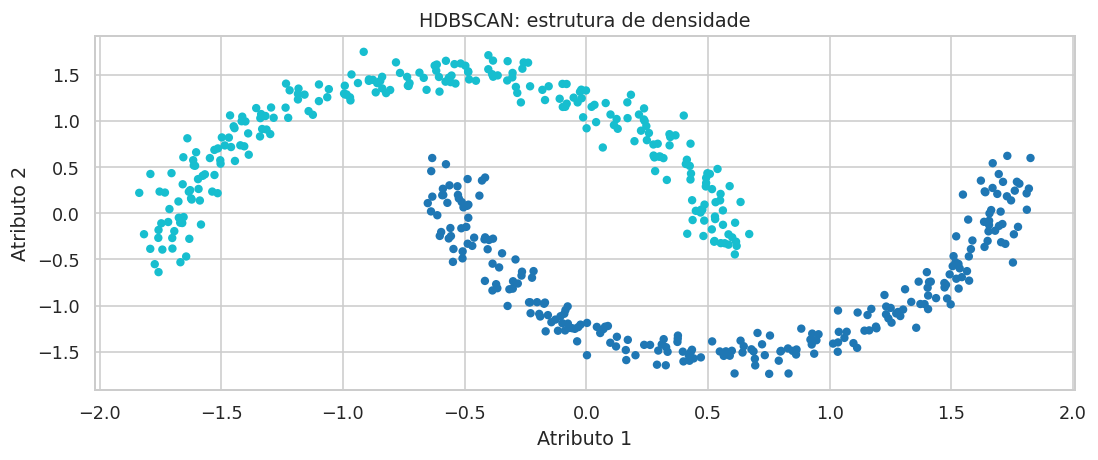

In [75]:
optics=OPTICS(min_samples=10,xi=0.05,min_cluster_size=0.08).fit(curvas_z)
ordem=optics.ordering_;alcance=optics.reachability_[ordem]
fig,ax=plt.subplots();ax.plot(np.arange(len(ordem)),np.where(np.isfinite(alcance),alcance,np.nan),linewidth=0.9)
ax.set(title='OPTICS: gráfico de alcance',xlabel='Ordem OPTICS',ylabel='Alcance');plt.show()
hdb=HDBSCAN(min_cluster_size=30,min_samples=8,copy=True).fit(curvas_z)
print('OPTICS: grupos =',len(set(optics.labels_)-{-1}),'| ruído =',(optics.labels_==-1).sum())
print('HDBSCAN: grupos =',len(set(hdb.labels_)-{-1}),'| ruído =',(hdb.labels_==-1).sum())
fig,ax=plt.subplots();ax.scatter(curvas_z[:,0],curvas_z[:,1],c=hdb.labels_,cmap='tab10',s=18)
ax.set(title='HDBSCAN: estrutura de densidade',xlabel='Atributo 1',ylabel='Atributo 2');plt.show()

**Interpretação do exemplo e decisão seguinte**

Examinar grupos e pontos de baixa persistência ou pertencimento. Estes métodos podem indicar ambiguidade que uma partição obrigatória esconde. Ainda é necessário verificar se a densidade tem significado para o problema de servidores ou sensores.

## 78. Gaussian Mixture: grupos probabilísticos e covariâncias

Uma mistura gaussiana representa a distribuição por uma soma ponderada de componentes normais multivariadas. Cada componente possui média, covariância e peso. Diferentemente de K-means, pode representar grupos elípticos e fornecer probabilidades de responsabilidade no modelo.

**O que se busca descobrir:** subpopulações modeladas por componentes e casos com pertencimento ambíguo. **Quando usar:** uma mistura de distribuições aproximadamente elípticas é plausível. **Escolhas:** quantidade de componentes e estrutura de covariância, como completa, diagonal ou compartilhada.

BIC combina ajuste e penalização por complexidade; menor valor é preferível entre os candidatos sob o modelo e a base. Não é uma medida absoluta de verdade, e um componente não equivale necessariamente a um grupo operacional. Uma distribuição com cauda pode ser aproximada por várias gaussianas sem que existam várias populações reais.

As responsabilidades são probabilidades condicionais dentro do modelo ajustado. Não chamá-las automaticamente de confiança validada de uma classe conhecida.

Componentes escolhidos por BIC: 4 | Convergência: True


,k,BIC,AIC
0,1,4180.47,4098.29
1,2,3125.63,2957.15
2,3,2612.26,2357.49
3,4,2328.88,1987.81
4,5,2418.16,1990.80
5,6,2463.65,1950.00


,servidor,grupo,maior_responsabilidade
256,S256,0,1.0
192,S192,0,1.0
225,S225,0,1.0
109,S109,2,1.0
12,S012,3,1.0
440,S440,1,1.0
441,S441,1,1.0
442,S442,1,1.0
443,S443,1,1.0
444,S444,1,1.0


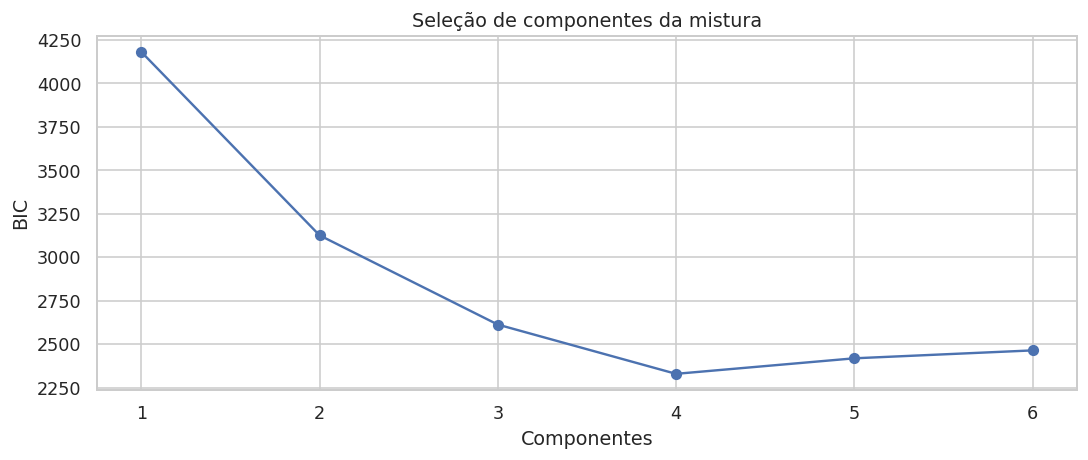

In [76]:
avaliacao_gmm=[]
for k in range(1,7):
    gm=GaussianMixture(n_components=k,covariance_type='full',n_init=5,reg_covar=1e-5,random_state=42).fit(Z)
    avaliacao_gmm.append({'k':k,'BIC':gm.bic(Z),'AIC':gm.aic(Z)})
avaliacao_gmm=pd.DataFrame(avaliacao_gmm);display(avaliacao_gmm.round(2))
k_gmm=int(avaliacao_gmm.loc[avaliacao_gmm['BIC'].idxmin(),'k'])
gmm=GaussianMixture(n_components=k_gmm,covariance_type='full',n_init=10,reg_covar=1e-5,random_state=42).fit(Z)
rotulos_gmm=gmm.predict(Z);responsabilidades=gmm.predict_proba(Z)
ambiguidade=pd.DataFrame({'servidor':perfis['servidor'],'grupo':rotulos_gmm,'maior_responsabilidade':responsabilidades.max(axis=1)})
display(ambiguidade.sort_values('maior_responsabilidade').head(10))
fig,ax=plt.subplots();ax.plot(avaliacao_gmm['k'],avaliacao_gmm['BIC'],'o-');ax.set(title='Seleção de componentes da mistura',xlabel='Componentes',ylabel='BIC');plt.show()
print('Componentes escolhidos por BIC:',k_gmm,'| Convergência:',gmm.converged_)

**Interpretação do exemplo e decisão seguinte**

Casos ambíguos merecem inspeção. BIC pode preferir mais componentes que os três perfis geradores devido a extremos ou à forma observada. Isso não invalida automaticamente a mistura nem revela mais categorias físicas.

## 79. Agrupamento espectral e semelhança em um grafo

Agrupamento espectral constrói uma representação por relações de afinidade em um grafo e usa autovetores associados à sua estrutura para dividir observações. Pode identificar formas que centroides Euclidianos não descrevem bem.

**Quando usar:** uma noção local de conexão ou afinidade é mais importante que proximidade a um centro. **O que se busca descobrir:** regiões conectadas e separadas no grafo. **Escolhas:** quantidade de grupos, definição de afinidade e parâmetros como gamma para um kernel RBF.

O exemplo usa as curvas e uma afinidade radial. Gamma alto torna afinidade muito local; baixo pode tornar tudo semelhante. Grafos desconectados ou conexões frágeis exigem interpretação. O algoritmo pode ter custo elevado em bases grandes e não fornece automaticamente uma regra simples para classificar novos pontos.

Um bom desenho da afinidade é parte da modelagem, não uma configuração neutra. Não concluir superioridade geral a partir de uma base escolhida para destacar formas curvas.

Método ajustado para esta base e esta afinidade.


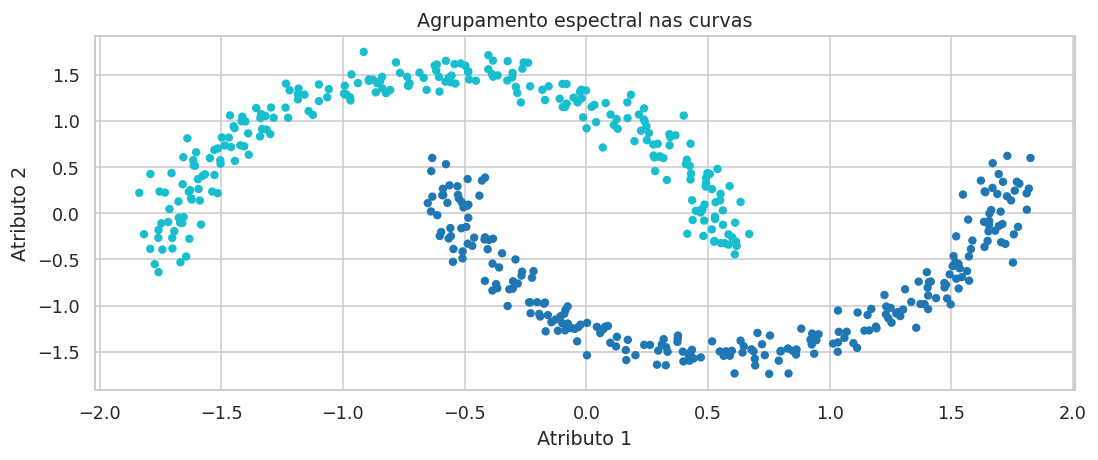

In [77]:
espectral=SpectralClustering(n_clusters=2,affinity='rbf',gamma=12,assign_labels='kmeans',n_init=20,random_state=42)
rotulos_espec=espectral.fit_predict(curvas_z)
fig,ax=plt.subplots();ax.scatter(curvas_z[:,0],curvas_z[:,1],c=rotulos_espec,cmap='tab10',s=18)
ax.set(title='Agrupamento espectral nas curvas',xlabel='Atributo 1',ylabel='Atributo 2');plt.show()
print('Método ajustado para esta base e esta afinidade.')

**Interpretação do exemplo e decisão seguinte**

O grafo define o problema de separação. Um resultado visualmente bom precisa ser robusto a escolhas próximas de afinidade. Para novos equipamentos, planejar uma extensão ou outro modelo com atribuição explícita.

## 80. Avaliação interna: silhueta, Davies-Bouldin e Calinski-Harabasz

Silhueta compara separação local com coesão. Davies-Bouldin relaciona dispersão interna e distância entre centros; menor tende a ser melhor no critério. Calinski-Harabasz compara variabilidade entre e dentro dos grupos; maior tende a ser melhor.

**O que se busca descobrir:** propriedades geométricas de partições candidatas. **Quando usar:** apoiar comparação na mesma representação e população. Os índices têm preferências e limitações: grupos curvos, densidades distintas e ruído podem ser mal resumidos por critérios de grupos compactos.

O exemplo compara partições dos servidores no mesmo Z. Não inclui as curvas, pois seriam outra base e outra população. Uma mistura pode ter uma quantidade de componentes distinta e representar densidade, não somente segmentação. Por isso, o ranking não será usado como decisão automática universal.

**Erro a evitar:** chamar silhueta de acurácia ou interpretar um índice alto como evidência de classes verdadeiras. A decisão final exige utilidade, domínio, estabilidade e qualidade dos atributos.

,metodo,grupos,silhueta,Davies_Bouldin,Calinski_Harabasz
0,K-means,4,0.7321,0.4555,1348.3087
1,Ward,4,0.7312,0.5946,1332.5958
2,MiniBatch,4,0.5344,1.2213,1109.1741
3,GMM,4,0.7312,0.5946,1332.5958


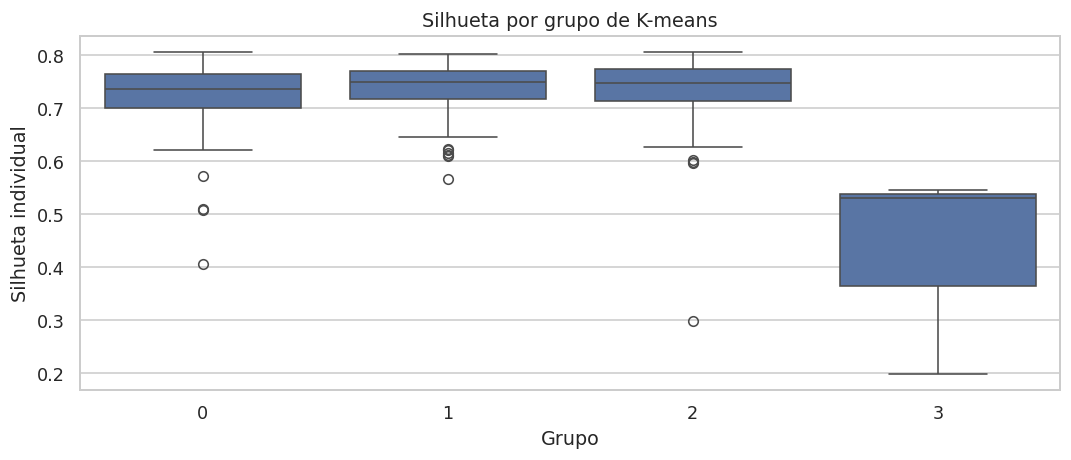

In [78]:
particoes={'K-means':rotulos_k,'Ward':rotulos_hier,'MiniBatch':mini_batch.labels_,'GMM':rotulos_gmm}
avaliacao_part=[]
for nome,rot in particoes.items():
    k=len(np.unique(rot))
    if 1<k<len(rot):
        avaliacao_part.append({'metodo':nome,'grupos':k,'silhueta':silhouette_score(Z,rot),
            'Davies_Bouldin':davies_bouldin_score(Z,rot),'Calinski_Harabasz':calinski_harabasz_score(Z,rot)})
avaliacao_part=pd.DataFrame(avaliacao_part);display(avaliacao_part.round(4))
sil_individual=silhouette_samples(Z,rotulos_k)
fig,ax=plt.subplots();sns.boxplot(x=rotulos_k,y=sil_individual,ax=ax)
ax.set(title='Silhueta por grupo de K-means',xlabel='Grupo',ylabel='Silhueta individual');plt.show()

**Interpretação do exemplo e decisão seguinte**

Um valor médio pode esconder um grupo com muitas observações de fronteira. Examinar distribuição e tamanhos, não apenas o índice global. Critérios internos medem a geometria escolhida; não substituem resultado operacional.

## 81. Estabilidade entre sementes, amostras e escalas

Uma estrutura útil não deveria desaparecer com mudanças pequenas e justificáveis do procedimento. Comparar sementes mede sensibilidade da otimização. Subamostragem mede uma forma de sensibilidade à composição. Trocar escala investiga dependência da representação.

ARI compara duas partições ignorando a permutação dos nomes dos grupos e corrige sua referência de concordância ao acaso. Valor um indica partições idênticas; valores próximos de zero sugerem concordância comparável à referência aleatória, e podem ocorrer valores negativos. Ele pode comparar resultados sem rótulos verdadeiros.

**O que se busca descobrir:** fragilidade da solução. **Quando usar:** antes de interpretar grupos como perfis estáveis. **Limite:** a demonstração de subamostragem ajusta e compara atribuições em uma base comum; não é uma prova formal nem substitui validação externa. Mesma partição pode ser estável e ainda não ser útil.

In [79]:
estabilidade=[]
for semente in [1,2,3,4,5]:
    rot=KMeans(n_clusters=k_escolhido,n_init=20,random_state=semente).fit_predict(Z)
    estabilidade.append({'tipo':'semente','execucao':semente,'ARI':adjusted_rand_score(rotulos_k,rot)})
rstab=np.random.default_rng(99)
for repeticao in range(5):
    idx=rstab.choice(len(Z),size=int(0.8*len(Z)),replace=False)
    mod=KMeans(n_clusters=k_escolhido,n_init=20,random_state=repeticao).fit(Z[idx])
    rot=mod.predict(Z)
    estabilidade.append({'tipo':'subamostra_80pct','execucao':repeticao,'ARI':adjusted_rand_score(rotulos_k,rot)})
display(pd.DataFrame(estabilidade))
rot_rob=KMeans(n_clusters=k_escolhido,n_init=20,random_state=42).fit_predict(Z_robusto)
print('ARI ao trocar StandardScaler por RobustScaler:',round(adjusted_rand_score(rotulos_k,rot_rob),4))
print('Verificação externa apenas na simulação, sem ter usado a origem no ajuste:')
print('ARI com origem geradora conhecida:',round(adjusted_rand_score(origem_simulada,rotulos_k),4))

ARI ao trocar StandardScaler por RobustScaler: 1.0
Verificação externa apenas na simulação, sem ter usado a origem no ajuste:
ARI com origem geradora conhecida: 0.9833


,tipo,execucao,ARI
0,semente,1,1.0
1,semente,2,1.0
2,semente,3,1.0
3,semente,4,1.0
4,semente,5,1.0
5,subamostra_80pct,0,1.0
6,subamostra_80pct,1,1.0
7,subamostra_80pct,2,1.0
8,subamostra_80pct,3,1.0
9,subamostra_80pct,4,1.0


**Interpretação do exemplo e decisão seguinte**

A verificação com origem conhecida é específica do ensino. Em dados reais, usar uma variável externa disponível não a transforma automaticamente em uma verdade absoluta. Concordância, estabilidade e utilidade são critérios diferentes.

## 82. Atribuir novos equipamentos sem reajustar a escala

Depois de uma exploração, um projeto pode precisar atribuir novos equipamentos a perfis existentes. K-means oferece `predict`, que escolhe o centro mais próximo na representação ajustada. O scaler precisa ser o mesmo usado no conjunto de referência.

**O que se busca descobrir:** a que perfil um novo dispositivo se aproxima e se ele é distante de todos os centros. **Quando usar:** aplicação de uma segmentação já definida. O método sempre escolhe um centro, mesmo que o ponto seja muito incomum. Por isso, atribuição não é garantia de pertencimento substantivo.

O exemplo separa uma referência e um conjunto reservado de perfis independentes. Aqui a divisão aleatória é compatível com a simulação sem ordem temporal; para telemetria histórica, utilizar um desenho temporal adequado. k é fixado como parte do exemplo e nenhuma informação do conjunto reservado é usada para ajustar a escala.

DBSCAN e o agrupamento hierárquico do scikit-learn não oferecem a mesma regra nativa de previsão de K-means. Não supor que todos os métodos possuem uma atribuição fora da amostra equivalente.

In [80]:
X_ref,X_novos=train_test_split(X,test_size=0.25,random_state=42)
escala_ref=StandardScaler().fit(X_ref)
Z_ref=escala_ref.transform(X_ref);Z_novos=escala_ref.transform(X_novos)
modelo_ref=KMeans(n_clusters=3,n_init=20,random_state=42).fit(Z_ref)
novos_grupos=modelo_ref.predict(Z_novos)
dist_centro=modelo_ref.transform(Z_novos).min(axis=1)
atri=pd.DataFrame({'servidor':perfis.loc[X_novos.index,'servidor'],'grupo':novos_grupos,'distancia_centro':dist_centro},index=X_novos.index)
display(atri.sort_values('distancia_centro',ascending=False).head(10))
print('As distâncias estão na escala ajustada somente na referência.')

As distâncias estão na escala ajustada somente na referência.


,servidor,grupo,distancia_centro
176,S176,1,1.184995
225,S225,1,1.129963
116,S116,2,1.081093
437,S437,0,1.064269
192,S192,1,1.033793
407,S407,0,1.005949
268,S268,1,0.983084
398,S398,0,0.981037
204,S204,1,0.977503
24,S024,2,0.942115


**Interpretação do exemplo e decisão seguinte**

Equipamentos distantes merecem análise adicional. Limites de distância devem ser calibrados conforme o objetivo e avaliados em dados novos, não escolhidos depois de observar uma situação para produzir um alerta desejado.

## 83. t-SNE: visualização local e riscos de interpretação

t-SNE constrói uma representação de baixa dimensão buscando preservar relações de vizinhança probabilísticas. É especialmente útil para visualizar estrutura local em dados multidimensionais. Perplexidade controla uma escala efetiva de vizinhança e deve ser menor que a quantidade de observações.

**O que se busca descobrir:** vizinhos e padrões locais que podem orientar exploração. **Quando usar:** visualização, não como comprovação automática de grupos. Distâncias globais, tamanhos de ilhas e espaços vazios podem ser distorcidos. Duas ilhas distantes não necessariamente representam maior diferença física que duas próximas.

O exemplo mostra duas perplexidades, mantendo rótulos de K-means apenas como cores, sem usá-los no ajuste. A geometria visual pode mudar. O resultado é uma representação dos pontos ajustados, e a implementação utilizada não fornece um `transform` geral para novos pontos.

**Erro a evitar:** medir silhueta no gráfico t-SNE e anunciar que os grupos originais foram validados. A projeção altera justamente a geometria que seria usada nesse índice.

Perplexidade 15 | trustworthiness local: 0.9772
Perplexidade 45 | trustworthiness local: 0.9786


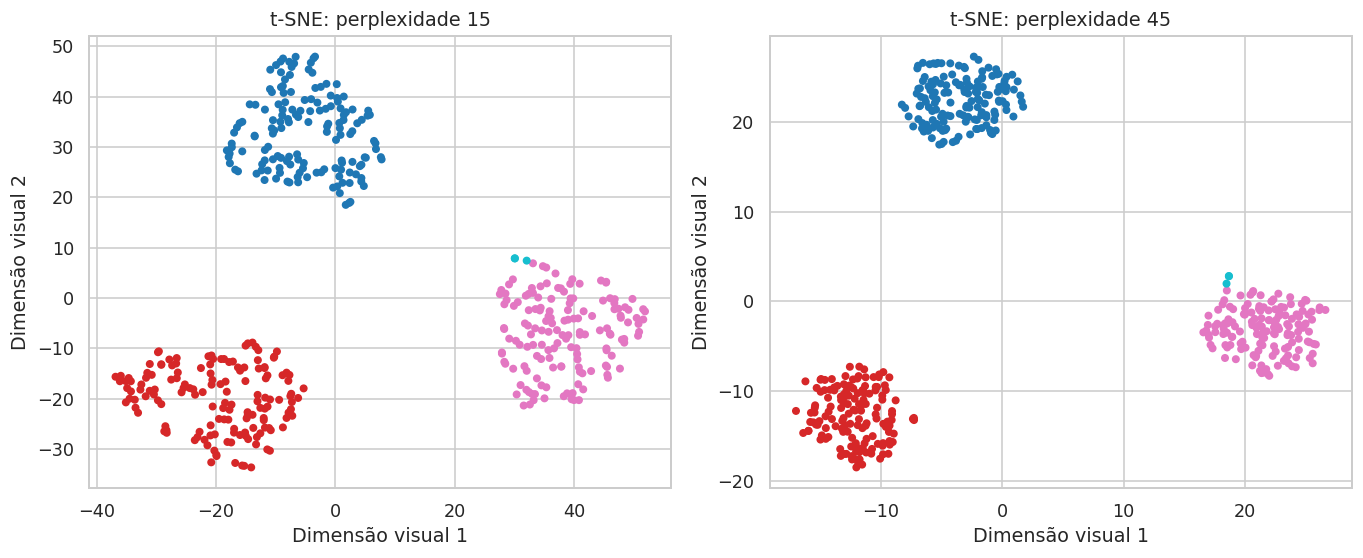

In [81]:
fig,axs=plt.subplots(1,2,figsize=(12,5))
representacoes_tsne={}
for ax,perplexidade in zip(axs,[15,45]):
    tsne=TSNE(n_components=2,perplexity=perplexidade,init='pca',learning_rate='auto',max_iter=1000,random_state=42)
    emb=tsne.fit_transform(Z);representacoes_tsne[perplexidade]=emb
    ax.scatter(emb[:,0],emb[:,1],c=rotulos_k,cmap='tab10',s=16)
    ax.set(title=f't-SNE: perplexidade {perplexidade}',xlabel='Dimensão visual 1',ylabel='Dimensão visual 2')
    print('Perplexidade',perplexidade,'| trustworthiness local:',round(trustworthiness(Z,emb,n_neighbors=10),4))
plt.tight_layout();plt.show()

**Interpretação do exemplo e decisão seguinte**

Trustworthiness avalia preservação de vizinhos no critério local, não verdade dos grupos. Comparar projeções com escores originais, exemplos de equipamentos e parâmetros. Não transformar a aparência de ilhas em uma taxonomia confirmada.

## 84. Isomap e UMAP: representações não lineares

Isomap constrói um grafo de vizinhos, aproxima distâncias ao longo desse grafo e procura uma representação que as preserve. É útil quando os dados se distribuem sobre uma estrutura curvada. Quantidade de vizinhos controla conectividade; poucas conexões podem fragmentar o grafo e muitas podem criar atalhos artificiais.

UMAP é outra técnica de representação não linear, com escolhas de vizinhança, distância mínima e métrica. Pode oferecer transformação de novos pontos em sua implementação usual. Assim como t-SNE, não comprova classes pela aparência e pode alterar distâncias ou densidades na representação.

**O que se busca descobrir:** estrutura que uma projeção linear não descreve. **Quando usar:** uma pergunta exploratória e uma hipótese plausível de estrutura de baixa dimensão. **Limites:** o mecanismo depende de parâmetros, da métrica e da quantidade de dados. O exemplo executa Isomap; UMAP é uma extensão opcional que exige o pacote `umap-learn` e fica desativada para não adicionar uma dependência ao percurso principal.

O exemplo de Isomap utiliza uma superfície contínua enrolada em três dimensões (Swiss roll), porque sua pergunta é recuperar uma estrutura curvada. Aplicar uma técnica de variedade a perfis muito separados pode produzir um grafo desconectado e uma representação inadequada. O gráfico compara a superfície original com a representação aprendida, usando a posição na superfície somente como cor, sem fornecer essa variável ao ajuste.

Componentes conectados do grafo: 1
Trustworthiness local: 0.8935
UMAP opcional não executado; Isomap integra a execução principal.


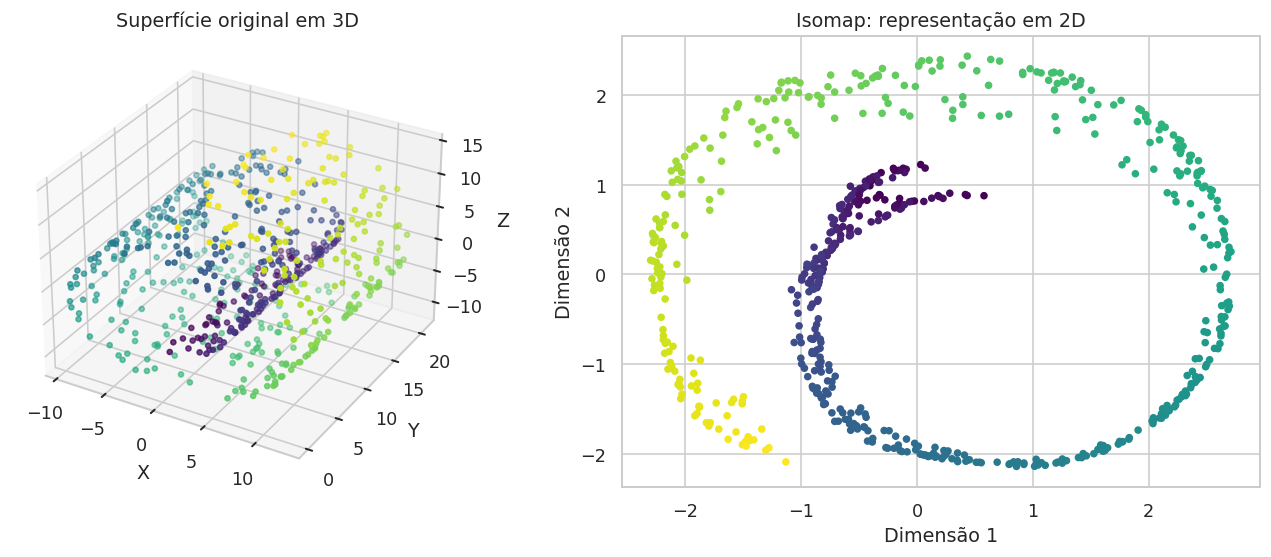

In [82]:
from sklearn.datasets import make_swiss_roll
from scipy.sparse.csgraph import connected_components
superficie, posicao_superficie = make_swiss_roll(n_samples=650, noise=0.03, random_state=42)
Z_superficie = StandardScaler().fit_transform(superficie)
grafo = NearestNeighbors(n_neighbors=20).fit(Z_superficie).kneighbors_graph(mode='connectivity')
n_componentes_grafo, _ = connected_components(grafo, directed=False)
print('Componentes conectados do grafo:', n_componentes_grafo)
if n_componentes_grafo != 1:
    raise ValueError('Revisar o número de vizinhos e a estrutura da base antes de usar Isomap.')
isomap = Isomap(n_components=2, n_neighbors=20)
emb_iso = isomap.fit_transform(Z_superficie)
fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(superficie[:,0], superficie[:,1], superficie[:,2], c=posicao_superficie, cmap='viridis', s=10)
ax1.set(title='Superfície original em 3D', xlabel='X', ylabel='Y', zlabel='Z')
ax2 = fig.add_subplot(122)
ax2.scatter(emb_iso[:,0],emb_iso[:,1],c=posicao_superficie,cmap='viridis',s=14)
ax2.set(title='Isomap: representação em 2D',xlabel='Dimensão 1',ylabel='Dimensão 2')
plt.tight_layout();plt.show()
print('Trustworthiness local:',round(trustworthiness(Z_superficie,emb_iso,n_neighbors=10),4))
EXECUTAR_UMAP=False
if EXECUTAR_UMAP:
    if importlib.util.find_spec('umap') is None:
        subprocess.check_call([sys.executable,'-m','pip','install','umap-learn'])
    import umap
    emb_umap=umap.UMAP(n_neighbors=20,min_dist=0.1,n_components=2,random_state=42).fit_transform(Z)
    fig,ax=plt.subplots();ax.scatter(emb_umap[:,0],emb_umap[:,1],c=rotulos_k,cmap='tab10',s=18)
    ax.set(title='UMAP opcional nos perfis de servidores',xlabel='Dimensão 1',ylabel='Dimensão 2');plt.show()
else:
    print('UMAP opcional não executado; Isomap integra a execução principal.')

**Interpretação do exemplo e decisão seguinte**

As cores mostram uma partição previamente ajustada e não entram na projeção. Preservação local e utilidade podem diferir. Se aparecer aviso de grafo desconectado, revisar vizinhança e representação antes de interpretar o gráfico como uma estrutura única.

## 85. Isolation Forest: pontuar combinações incomuns

Isolation Forest constrói árvores por divisões aleatórias. Pontos que são isolados em caminhos mais curtos tendem a receber maior indicação de anomalia. O algoritmo utiliza combinações de atributos e não depende de um limite individual para cada coluna.

**O que se busca descobrir:** equipamentos incomuns em relação à população observada. **Quando usar:** triagem exploratória de perfis multidimensionais. **Escolhas:** atributos, tamanho de amostra, quantidade de árvores e limiar de decisão. `contamination` define uma proporção ou uma política de corte; não revela a prevalência verdadeira de falhas.

O exemplo fixa 3% para ilustrar uma capacidade de investigação. Um alerta é um candidato, não um diagnóstico. Um servidor especializado pode ser incomum e perfeitamente saudável. Inversamente, uma falha frequente pode deixar de ser estatisticamente rara.

O ajuste e os escores são exploratórios na mesma base. Para detectar novidades em operação, ajustar no histórico de referência e avaliar novos pontos, acompanhando mudanças do processo.

Alertas pelo limiar definido: 14


,servidor,cpu_pct,memoria_pct,io_mb_s,rede_mb_s,temperatura_c,escore_anomalia,alerta
163,S163,99.000000,44.197416,294.242280,223.946512,69.912961,0.749211,True
322,S322,65.523309,94.765779,411.755174,326.409476,61.701974,0.747594,True
340,S340,68.128420,89.415811,420.168952,301.825641,55.277995,0.738669,True
12,S012,45.972150,35.127633,232.358474,216.307463,47.999832,0.667309,True
321,S321,17.541827,79.754209,245.249394,146.634793,45.095942,0.582519,True
368,S368,39.900372,96.234218,211.065922,108.280348,57.008668,0.567874,True
83,S083,9.034130,44.022427,1.996136,43.612079,35.528784,0.552539,True
3,S003,11.078828,55.806317,55.223133,0.100000,36.671366,0.551051,True
114,S114,21.880238,13.951524,48.764940,2.167643,32.333217,0.545490,True
155,S155,77.896206,67.407095,83.209464,38.552876,67.163013,0.542503,True


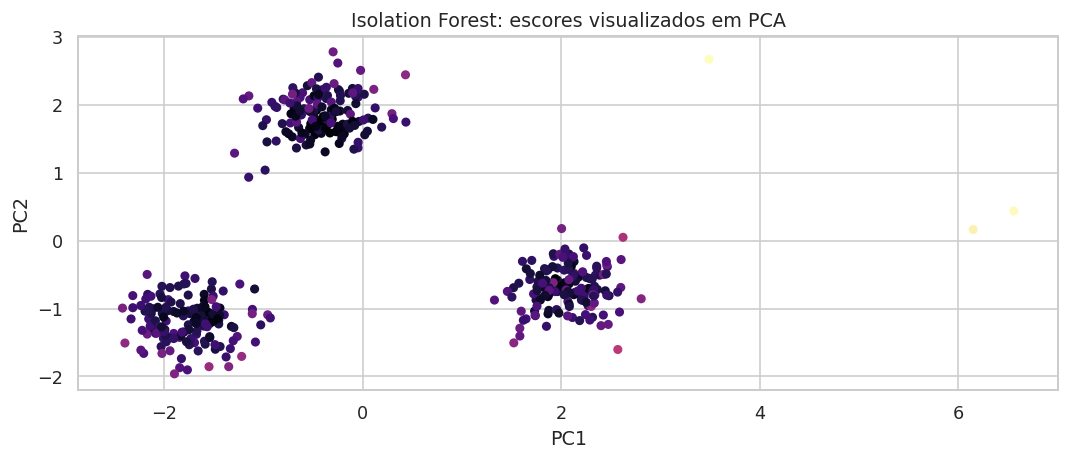

In [83]:
isolamento=IsolationForest(n_estimators=200,contamination=0.03,random_state=42).fit(Z)
rotulos_if=isolamento.predict(Z)
escore_if=-isolamento.score_samples(Z)  # Maior valor: mais incomum neste sentido de escore.
alertas_if=perfis.assign(escore_anomalia=escore_if,alerta=rotulos_if==-1)
display(alertas_if.sort_values('escore_anomalia',ascending=False).head(12))
fig,ax=plt.subplots();ax.scatter(componentes[:,0],componentes[:,1],c=escore_if,cmap='magma',s=22)
ax.set(title='Isolation Forest: escores visualizados em PCA',xlabel='PC1',ylabel='PC2');plt.show()
print('Alertas pelo limiar definido:',int((rotulos_if==-1).sum()))

**Interpretação do exemplo e decisão seguinte**

A quantidade de alertas é influenciada pela política de contaminação. Não interpretá-la como estimativa automática de percentual de equipamentos defeituosos. Verificar logs e custos de investigação para calibrar a decisão.

## 86. Local Outlier Factor: anomalia relativa aos vizinhos

LOF compara a densidade local de uma observação com a de seus vizinhos. Um ponto pode ser incomum em sua região mesmo sem ser extremo globalmente. Isso é útil em dados com subgrupos de densidades diferentes.

**O que se busca descobrir:** baixa densidade relativa no contexto local. **Quando usar:** uma noção de vizinhança tem significado e há interesse em discrepâncias locais. **Escolhas:** número de vizinhos, escala, métrica e limiar. Vizinhança muito pequena pode ser instável; muito grande pode apagar contexto.

Na modalidade padrão, `fit_predict` detecta outliers na própria amostra. Para novidade em observações novas, `novelty=True` permite `predict` após ajuste, mas a orientação da implementação exige usar essa previsão em dados novos, não como reavaliação equivalente dos dados de treino.

Comparar LOF com Isolation Forest ajuda a investigar se a discrepância é local ou global. Discordância não significa que um detector está errado: eles definem “incomum” de formas distintas.

In [84]:
lof=LocalOutlierFactor(n_neighbors=25,contamination=0.03)
rotulos_lof=lof.fit_predict(Z)
escore_lof=-lof.negative_outlier_factor_
comparacao_alertas=perfis[['servidor']].assign(IF=rotulos_if==-1,LOF=rotulos_lof==-1,escore_LOF=escore_lof)
display(comparacao_alertas.sort_values('escore_LOF',ascending=False).head(12))
print('Alertas em ambos:',int(((rotulos_if==-1)&(rotulos_lof==-1)).sum()))
lof_novidade=LocalOutlierFactor(n_neighbors=25,novelty=True,contamination=0.03).fit(Z_ref)
alerta_novos=lof_novidade.predict(Z_novos)
print('Novos perfis sinalizados pelo modelo de referência:',int((alerta_novos==-1).sum()))

Alertas em ambos: 7
Novos perfis sinalizados pelo modelo de referência: 2


,servidor,IF,LOF,escore_LOF
322,S322,True,True,6.950679
340,S340,True,True,6.442843
163,S163,True,True,6.373692
12,S012,True,True,3.692809
321,S321,True,True,1.685097
256,S256,False,True,1.624955
261,S261,False,True,1.561295
368,S368,True,True,1.549950
111,S111,False,True,1.531813
225,S225,False,True,1.509142


**Interpretação do exemplo e decisão seguinte**

Os escores não possuem a mesma escala e não devem ser comparados numericamente entre detectores sem calibração. Investigar casos discordantes pode ensinar mais sobre a estrutura do que simplesmente unir todos os alertas.

## 87. Regras de associação: eventos que aparecem juntos

Regras de associação investigam coocorrência em transações, como eventos presentes em uma janela de logs. Uma regra A → B possui suporte P(A e B), confiança P(B|A) e lift P(B|A)/P(B). Lift acima de um indica coocorrência maior que a referência de independência na base observada.

**O que se busca descobrir:** combinações recorrentes que orientam investigação de incidentes. **Quando usar:** observações representadas por conjuntos de itens, não valores contínuos brutos. **Limites:** confiança alta pode ser causada por B muito comum; lift pode ser instável em eventos raros; nenhuma dessas medidas estabelece causalidade ou sequência temporal.

O exemplo calcula regras com antecedentes e consequentes de um item por enumeração, adequado à base pequena. Apriori e FP-Growth são métodos de busca mais eficientes de conjuntos frequentes em aplicações maiores. A demonstração não implementa esses algoritmos e não deve ser chamada de Apriori.

A definição da janela muda as transações. Se o objetivo for sequência de eventos, regras temporais exigem preservar ordem em vez de apenas presença conjunta.

In [85]:
transacoes=[{'cpu_alta','temperatura_alta','ventilador'}, {'cpu_alta','temperatura_alta'},
 {'cpu_alta','temperatura_alta','timeout'}, {'rede_alta','timeout'}, {'rede_alta','timeout'},
 {'disco_erro','timeout'}, {'cpu_alta','temperatura_alta'}, {'rede_alta'},
 {'disco_erro','timeout'}, {'cpu_alta','ventilador'}, {'temperatura_alta','ventilador'},
 {'rede_alta','timeout','disco_erro'}]
itens=sorted(set().union(*transacoes));regras=[]
for ant in itens:
    for cons in itens:
        if ant==cons:continue
        pa=np.mean([ant in t for t in transacoes]);pb=np.mean([cons in t for t in transacoes])
        pab=np.mean([ant in t and cons in t for t in transacoes])
        if pab>=0.15:
            regras.append({'regra':ant+' → '+cons,'suporte':pab,'confianca':pab/pa,'lift':pab/(pa*pb)})
regras=pd.DataFrame(regras).sort_values(['lift','suporte'],ascending=False)
display(regras.round(4))

,regra,suporte,confianca,lift
2,disco_erro → timeout,0.2500,1.0000,2.00
6,timeout → disco_erro,0.2500,0.5000,2.00
0,cpu_alta → temperatura_alta,0.3333,0.8000,1.92
4,temperatura_alta → cpu_alta,0.3333,0.8000,1.92
1,cpu_alta → ventilador,0.1667,0.4000,1.60
5,temperatura_alta → ventilador,0.1667,0.4000,1.60
8,ventilador → cpu_alta,0.1667,0.6667,1.60
9,ventilador → temperatura_alta,0.1667,0.6667,1.60
3,rede_alta → timeout,0.2500,0.7500,1.50
7,timeout → rede_alta,0.2500,0.5000,1.50


**Interpretação do exemplo e decisão seguinte**

Uma regra temperatura_alta → cpu_alta não demonstra que temperatura cause CPU alta, nem define a ordem dos eventos. Usar a regra como hipótese a investigar e validar em novas janelas, considerando suporte e múltiplas buscas.

## 88. Comparar técnicas não supervisionadas conforme a pergunta

Não existe um algoritmo melhor para qualquer base. A escolha depende da estrutura buscada, volume, tipo de variável, capacidade de interpretar e necessidade de aplicação a pontos novos. O quadro reúne diferenças úteis após executar os exemplos.

**O que se busca descobrir:** um caminho coerente para um novo problema. **Erro a evitar:** decidir pelo gráfico mais bonito ou pelo maior índice entre representações diferentes. Agrupamentos, fatores, projeções e escores resolvem problemas distintos e não devem ser tratados como respostas intercambiáveis.

Métodos adicionais, como k-medoids, modelos de tópicos, embeddings e autoencoders, podem ser úteis em situações específicas. Autoencoders aprendem uma reconstrução não linear, mas exigem arquitetura, quantidade de dados, treinamento e validação próprios. Não constituem uma substituição automática de PCA, e um erro de reconstrução não é uma probabilidade de falha.

| Técnica | Busca principal | Escolhas essenciais | Limitação que deve acompanhar a interpretação |
|---|---|---|---|
| PCA | Direções de maior variância | Escala e dimensões | Variância não equivale a relevância ou classe |
| Análise fatorial | Covariação por fatores latentes | Número de fatores e rotação | Fatores estatísticos não comprovam mecanismos |
| SVD truncada | Representação compacta de matriz esparsa | Vetorização e dimensões | Sem centralização usual do PCA |
| NMF | Combinação não negativa de partes | Escala e componentes | Componentes variam com ajuste e representação |
| ICA | Fontes independentes em misturas | Modelo de mistura e fontes | Ordem, escala e sinais ambíguos |
| K-means | Grupos compactos por centroides | k, escala e sementes | Formas e densidades podem ser inadequadas |
| MiniBatchKMeans | Aproximação em lotes | Lote e inicialização | Pode diferir do ajuste completo |
| Hierárquico | Estrutura de fusões | Distância, ligação e corte | Árvore não é causal nem taxonomia confirmada |
| DBSCAN | Regiões densas conectadas | eps e min_samples | Sensível à escala e densidades distintas |
| OPTICS | Estrutura de alcance | Vizinhança e extração | Ordem e vales precisam de interpretação |
| HDBSCAN | Grupos persistentes por densidade | Tamanho mínimo e vizinhança | Ruído não significa falha real |
| GMM | Mistura probabilística | Componentes e covariâncias | Componente não equivale a população física |
| Espectral | Partição por afinidade em grafo | Afinidade e grupos | Custo e atribuição de novos pontos |
| t-SNE | Vizinhanças em visualização | Perplexidade e semente | Distâncias globais e ilhas podem enganar |
| Isomap/UMAP | Representação não linear | Vizinhança e métrica | Estrutura depende de parâmetros e conectividade |
| Isolation Forest | Facilidade de isolamento | Referência e limiar | Anomalia estatística não é diagnóstico |
| LOF | Densidade local relativa | Vizinhos e limiar | Treino e novidade exigem uso distinto |
| Regras de associação | Coocorrências | Transações, suporte e filtro | Associação não estabelece causalidade ou ordem |

## 89. Roteiro completo de uma análise após data wrangling

**Etapa 1: contrato e desenho.** Registrar unidade de observação, população, amostragem, variável, unidade física, fatores, dependência e objetivo. Confirmar o resultado do tratamento sem apagar o histórico de mudanças.

**Etapa 2: descrição.** Contar categorias e observações por grupo. Para quantitativas, apresentar centro, dispersão, quantis e distribuição. Escolher gráficos que respondam à pergunta e revelar caudas, extremos e misturas.

**Etapa 3: pergunta inferencial.** Definir o parâmetro: média, mediana, probabilidade, distribuição, relação condicional ou equivalência. Planejar efeito relevante, alfa, comparações e quantidade de dados. Não selecionar o parâmetro depois de descobrir qual gera evidência mais favorável.

**Etapa 4: diagnóstico e método.** Examinar independência pelo desenho, forma pelo gráfico, variabilidade e influência. Selecionar teste ou modelo compatível. O teste de normalidade é apenas uma parte possível desse diagnóstico.

**Etapa 5: estimativa e incerteza.** Reportar efeitos em unidades, intervalos, tamanho amostral e p quando apropriado. Controlar multiplicidade na família planejada. Não chamar ausência de evidência de equivalência.

**Etapa 6: descoberta não supervisionada.** Escolher atributos, escala e distância conforme o significado de semelhança. Comparar métodos coerentes, investigar quantidade de grupos, ruído, estabilidade e perfis nas unidades originais.

**Etapa 7: validação e comunicação.** Separar exploração de confirmação, examinar utilidade em dados novos e registrar limitações. Um perfil ou alerta precisa apoiar uma decisão concreta, não apenas produzir uma figura.

**Etapa 8: reprodução.** Preservar dados, notebook executado, versões, sementes, fórmulas, parâmetros, políticas de seleção e resultados. Quando a coleta mudar, revisar o procedimento antes de reutilizar conclusões.

## 90. Exportar resultados e construir um registro reutilizável

Os arquivos exportados documentam exemplos e resultados. O notebook preserva a teoria, o código e a saída, enquanto CSV permite integração com planilhas ou scripts. O conjunto de técnicas executadas é um material de referência, não um pacote automático de testes confirmatórios para ser aplicado integralmente a qualquer base.

**O que se busca descobrir:** quais resultados foram produzidos e com quais configurações. **Quando usar:** toda análise que será compartilhada ou repetida. **Cuidado:** os CSVs não contêm sozinho todo o contexto; o notebook é necessário para explicar perguntas e limites. Dados reais também exigem gestão de acesso e proteção adequada à finalidade.

Os rótulos dos grupos são arbitrários. Registrar as transformações e o significado adotado para nomear perfis evita comparar rótulo 0 de uma execução com rótulo 0 de outra como se fossem o mesmo grupo.

In [86]:
pd.DataFrame(registros).to_csv(saida/'registro_testes_didaticos.csv',index=False)
tabela_ic.to_csv(saida/'ic_medias_firmware.csv',index=False)
pares.to_csv(saida/'comparacoes_welch_holm.csv',index=False)
avaliacao_k.to_csv(saida/'avaliacao_kmeans.csv',index=False)
avaliacao_part.to_csv(saida/'avaliacao_particoes.csv',index=False)
perfis_agrupados.to_csv(saida/'perfis_com_grupos.csv',index=False)
alertas_if.to_csv(saida/'candidatos_anomalia.csv',index=False)
regras.to_csv(saida/'regras_associacao.csv',index=False)
config={'semente_principal':2026,'atributos_agrupamento':atributos,'escala':'StandardScaler',
        'k_exploratorio':k_escolhido,'componentes_gmm':k_gmm,'versoes':versoes,
        'natureza_dados':'sintéticos; exemplos didáticos'}
(saida/'configuracao.json').write_text(json.dumps(config,ensure_ascii=False,indent=2))
print('Resultados criados na pasta:',saida)
for arq in sorted(saida.iterdir()):print(arq.name)

Resultados criados na pasta: saidas_estatistica
avaliacao_kmeans.csv
avaliacao_particoes.csv
candidatos_anomalia.csv
comparacoes_welch_holm.csv
configuracao.json
dispositivos_limpos.csv
ic_medias_firmware.csv
perfis_com_grupos.csv
perfis_servidores.csv
registro_testes_didaticos.csv
regras_associacao.csv


**Interpretação do exemplo e decisão seguinte**

Os arquivos são gerados no ambiente de execução. No Colab, baixar os resultados desejados. Em um projeto próprio, acrescentar identificador de experimento, origem dos dados, critérios de exclusão e uma descrição de cada análise planejada.

## 91. Adaptar a uma base própria sem aplicar todos os testes

A célula oferece um início de importação, deliberadamente desativado para que o notebook execute sem outro arquivo. Antes de ativar, examinar nomes, separador, convenção decimal e unidade de observação. Uma tabela limpa pode conter identificadores, categorias, medidas repetidas e variáveis que não devem entrar em distância.

**O que se busca descobrir:** quais blocos do material atendem à pergunta real. **Sequência:** importar, conferir contrato, classificar variáveis, identificar independência, selecionar descrição, definir parâmetros e escolher técnicas. Para descoberta, definir uma tabela de atributos coerente e excluir identificadores.

Não reutilizar limites físicos, margens de equivalência, períodos ou limiares de anomalia sem justificativa. Não assumir que uma coleção de linhas é independente porque está em formato tabular. Para dados temporais, utilizar o notebook de séries temporais e uma validação compatível com tempo.

O material funciona como referência de procedimentos, não como sequência obrigatória de todos os testes. Uma análise simples bem justificada pode responder melhor que dezenas de resultados sem pergunta.

In [87]:
USAR_BASE_PROPRIA=False
if USAR_BASE_PROPRIA:
    base_propria=pd.read_csv('minha_base_limpa.csv',sep=',',decimal='.')
    display(base_propria.head())
    display(pd.DataFrame({'tipo':base_propria.dtypes.astype(str),
                          'ausentes':base_propria.isna().sum(),
                          'distintos':base_propria.nunique()}))
    # Definir explicitamente unidade de observação e colunas antes de analisar.
    # Exemplo de seleção, após revisar nomes reais:
    # atributos_proprios = ['consumo_w','temperatura_c','latencia_ms']
    # X_proprio = base_propria[atributos_proprios]
else:
    print('Importação própria desativada. Os exemplos principais já são autossuficientes.')

Importação própria desativada. Os exemplos principais já são autossuficientes.


**Interpretação do exemplo e decisão seguinte**

Ativar apenas após planejar a análise. Caso a base tenha medidas repetidas, identificar equipamento e condição antes de selecionar qualquer teste. O caminho adequado depende do desenho, não apenas do tipo numérico da coluna.

## 92. Exercícios guiados de estatística e interpretação

1. Identificar a unidade independente nas três bases: dispositivos, benchmarks pareados e perfis de servidores. Explicar por que 144 medições pareadas não são 144 placas independentes.
2. Explicar qual pergunta é respondida por média, mediana e p95 da latência. Criar um exemplo em que a média aumenta e a mediana praticamente não muda.
3. Comparar desvio padrão e erro padrão. Investigar o que muda ao duplicar literalmente as linhas, sem coletar novas unidades. Explicar por que isso não cria informação independente.
4. Examinar Q-Q e Shapiro. Explicar por que rejeitar normalidade não invalida o cálculo da média nem determina automaticamente usar Mann-Whitney.
5. Comparar diferença média A − B, IC e Hedges g. Definir uma margem de relevância de engenharia e verificar o que os resultados permitem concluir.
6. Na base pareada, embaralhar apenas a coluna B e observar a alteração no resultado. Explicar por que a correspondência não pode ser perdida em um benchmark real.
7. Explicar a diferença entre Welch, Mann-Whitney e KS. Formular uma pergunta coerente para cada um, sem tratá-los como alternativas intercambiáveis.
8. Comparar p bruto e p corrigido de Holm. Identificar a família de hipóteses e explicar por que não se deve corrigir apenas comparações previamente favoráveis.
9. Em proporções, apresentar numerador e denominador. Explicar a diferença entre aumento relativo de 50% e aumento de cinco pontos percentuais.
10. Interpretar risco relativo e odds ratio da tabela de falhas. Inverter linhas e investigar o que muda.
11. Comparar regressão simples e múltipla. Explicar o significado de manter termos fixos e o motivo pelo qual ajuste não comprova causalidade.
12. Investigar resíduos e influência. Comparar coeficientes com e sem o dispositivo de maior Cook apenas como análise de sensibilidade, mantendo a justificativa.
13. Comparar média prevista, quantil p90 e intervalo de previsão individual. Formular decisões que exigem cada resposta.
14. Explicar por que não rejeitar diferença zero não demonstra equivalência. Definir margens antes da análise.
15. Descrever o que aconteceria ao tratar tempos censurados como tempos exatos de falha.

Em todas as atividades, entregar pergunta, desenho, gráfico, estimativa, interpretação e limitação. Uma captura de tela com p-valor não constitui uma resposta completa.

## 93. Exercícios guiados de técnicas não supervisionadas

1. Executar K-means sem escalonamento e comparar perfis, silhueta e estabilidade com a versão padronizada. Explicar quais atributos passam a dominar e por quê.
2. Adicionar o identificador numérico do servidor como atributo. Investigar a alteração e justificar por que esse número não representa uma medida física de semelhança.
3. Remover um atributo redundante e comparar PCA e agrupamento. Explicar por que duplicar informação pode alterar distâncias.
4. Escolher duas quantidades de componentes PCA e comparar erro de reconstrução. Investigar se um perfil raro fica escondido na projeção.
5. Comparar K-means e Ward nas unidades originais. Identificar observações de fronteira e verificar se os nomes dos grupos permanecem coerentes.
6. Alterar eps e min_samples em DBSCAN. Apresentar grupos, ruído e sensibilidade, sem chamar ruído de defeito.
7. Comparar GMM com k fixo e seleção por BIC. Investigar responsabilidades de casos ambíguos e distinguir componente de categoria operacional.
8. Alterar perplexidade e semente no t-SNE. Explicar por que distâncias entre ilhas e seus tamanhos não podem ser lidos como propriedades físicas diretas.
9. Comparar a estabilidade por ARI entre sementes e subamostras. Discutir por que estabilidade não equivale a utilidade.
10. Examinar alertas discordantes entre Isolation Forest e LOF. Escolher dois casos e explicar em qual contexto são incomuns.
11. Alterar contamination e investigar quantidade de alertas. Explicar por que esse parâmetro não estima a prevalência real de falhas.
12. Nas regras de associação, encontrar uma regra de confiança alta e discutir a frequência do consequente. Verificar o papel de lift e suporte.
13. Planejar atribuição de novos equipamentos. Definir quais transformações ficam fixas e qual regra será usada para observações distantes.
14. Formular um projeto próprio: descoberta de perfis, redução de sensores ou organização de logs. Definir objetivo, unidade, atributos, distância, método, validação e uma decisão operacional.

Não alterar simultaneamente todos os parâmetros. Modificar uma decisão por vez, registrar a justificativa e comparar na mesma base e representação sempre que a pergunta exigir comparação direta.

## 94. Respostas orientadoras e síntese dos critérios de escolha

**Média versus mediana.** A média é sensível à magnitude de todas as observações e é relevante para somas e valores esperados. A mediana representa o centro por ordenação e resiste a alguns extremos. Nenhuma exige normalidade para existir como descrição da amostra.

**Independência.** A quantidade de unidades não é a quantidade de linhas quando há repetição. No benchmark, cada placa traz três resultados relacionados. Preservar pares ou a estrutura hierárquica é parte da análise.

**Testes diferentes.** Welch investiga médias independentes; Mann-Whitney utiliza postos e exige condições adicionais para leitura de mediana; KS investiga uma diferença de distribuição. Trocar o nome do teste pode trocar a pergunta.

**Ausência de evidência.** p elevado não comprova igualdade. Um IC largo pode admitir diferenças relevantes dos dois sinais. Equivalência exige margem definida e um procedimento correspondente.

**Componentes e grupos.** PCA e SVD produzem representações, não categorias verdadeiras. K-means impõe uma partição para k dado. DBSCAN pode deixar pontos sem grupo. GMM atribui responsabilidades no modelo.

**Validação não supervisionada.** Índices internos descrevem geometria; ARI entre execuções descreve concordância; uma variável externa pode apoiar interpretação; utilidade exige uma decisão verificável. Nenhum desses critérios sozinho comprova uma estrutura natural.

**Anomalias.** Um perfil raro pode ser especializado e saudável. Um perfil comum pode estar inadequado se o problema afetar muitos equipamentos. Investigar a origem e o custo do alerta é indispensável.

**Comunicação.** Sempre dizer o que foi estimado, em qual unidade, sob qual desenho, com que incerteza e para qual população. A resposta técnica termina nos limites sustentados pelos dados, não nos limites do software.

## 95. Glossário e limites de aplicação

| Termo | Significado neste notebook |
|---|---|
| Parâmetro | Característica do modelo ou população, como média ou probabilidade |
| Estatística | Quantidade calculada na amostra |
| Erro padrão | Variabilidade estimada de uma estimativa entre amostras |
| IC | Intervalo de confiança de um procedimento frequentista |
| IP | Intervalo para uma observação futura sob um modelo |
| Efeito | Magnitude definida pela pergunta, como diferença ou razão |
| p-valor | Extremidade da estatística sob hipótese nula e modelo |
| Alfa | Nível previamente definido do procedimento de teste |
| Poder | Probabilidade de detectar um efeito especificado no desenho |
| Confundimento | Mistura de mecanismos que dificulta interpretar uma associação |
| Heterocedasticidade | Variância condicional dos erros não constante |
| Pareamento | Correspondência entre medições da mesma unidade ou pares definidos |
| Pseudorreplicação | Tratar repetição dependente como informação independente |
| Fator latente | Variável não diretamente observada em um modelo de estrutura |
| Centroide | Centro representativo de um grupo na geometria usada |
| Silhueta | Critério de coesão e separação na métrica escolhida |
| Responsabilidade | Peso probabilístico de componente em uma mistura ajustada |
| Ruído em DBSCAN | Ponto sem atribuição a grupo sob os parâmetros |
| Novidade | Observação nova avaliada em referência anterior |
| Contaminação | Política/parâmetro de quantidade de casos marcados como incomuns |
| Lift | Coocorrência relativa à referência de independência |

Análises de dados composicionais, espaciais, redes, grandes grafos, sinais complexos, desenhos causais, amostras com pesos, imputação múltipla e inferência pós-seleção exigem metodologias específicas. O roteiro ajuda a reconhecer quando a estrutura dos dados ultrapassa um teste simples. Não é adequado tratar todos esses cenários como tabelas independentes comuns.

## 96. Referências e documentação para consulta

A teoria introdutória e os exemplos foram organizados para ensino. As referências abaixo permitem aprofundar desenho, interpretação e uso das bibliotecas. As APIs foram consultadas na documentação oficial; as versões realmente utilizadas aparecem na preparação do ambiente.

MONTGOMERY, D. C.; RUNGER, G. C. *Applied Statistics and Probability for Engineers*. 7. ed. Hoboken: Wiley, 2018.

JAMES, G. et al. *An Introduction to Statistical Learning: with Applications in Python*. Cham: Springer, 2023. Disponível em: https://www.statlearning.com/ .

SCIPY. *Statistical functions (scipy.stats)*. Disponível em: https://docs.scipy.org/doc/scipy/reference/stats.html .

SCIPY. *ttest_ind*. Disponível em: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html .

SCIPY. *mannwhitneyu*. Disponível em: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html .

SCIPY. *permutation_test*. Disponível em: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html .

STATSMODELS. *Statistics*. Disponível em: https://www.statsmodels.org/stable/stats.html .

STATSMODELS. *Regression and Linear Models*. Disponível em: https://www.statsmodels.org/stable/regression.html .

STATSMODELS. *Generalized Linear Models*. Disponível em: https://www.statsmodels.org/stable/glm.html .

SCIKIT-LEARN. *Unsupervised learning*. Disponível em: https://scikit-learn.org/stable/unsupervised_learning.html .

SCIKIT-LEARN. *Clustering*. Disponível em: https://scikit-learn.org/stable/modules/clustering.html .

SCIKIT-LEARN. *Decomposing signals in components*. Disponível em: https://scikit-learn.org/stable/modules/decomposition.html .

SCIKIT-LEARN. *Outlier and novelty detection*. Disponível em: https://scikit-learn.org/stable/modules/outlier_detection.html .

SCIKIT-LEARN. *TSNE*. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html .

SCIKIT-LEARN. *HDBSCAN*. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html .

MCINNES, L.; HEALY, J.; MELVILLE, J. *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction*. 2018. Disponível em: https://arxiv.org/abs/1802.03426 . Documentação: https://umap-learn.readthedocs.io/ .

Consulta das páginas oficiais de estatística e aprendizado não supervisionado: 9 out. 2026. Os resultados são demonstrativos e baseados em dados sintéticos. UMAP permanece opcional, sem execução no percurso principal.